# Agentic Claims-Denial Framework — Coordinator + 4 Specialists + HIPAA/GDPR review + Hybrid Contextual RAG

**LLM:** `openai/gpt-oss-120b` on **Groq** for every agent. RAG embeddings run in-process with
[fastembed](https://github.com/qdrant/fastembed) (`BAAI/bge-small-en-v1.5`) — no extra service.

**Data:** `data/claim_metrics.csv` — one row per claim (see `data/README.md` for the column dictionary).
**Policy documents** for the RAG go in `docs/` (see the repository README).
With Groq, the minimum-necessary data layer (Section 4) is what limits which claim data leaves the machine.

![Architecture: coordinator, 4 specialist agents, hybrid RAG, quality gate and HIPAA/GDPR post-review](assets/architecture_vertical.png)

<sub>Mermaid source: `assets/architecture.mmd`</sub>

| Section | What it does |
|---|---|
| 0 | Libraries — installs `requirements.txt` and imports every package in one place |
| 1 | Setup & configuration (secrets + overrides in `.env`, template `.env.example` — no hardcoded paths/keys) |
| 2 | LLM: Groq `openai/gpt-oss-120b` through pydantic-ai's OpenAI-compatible model |
| 3 | **Model training with Optuna hyper-parameter tuning** on `claim_metrics.csv` (cached; retrains when data/spec change) |
| 4 | **Claim analytics computed in the notebook** — scores + TreeSHAP, code-graph **GNN** + combo lift, claim GNN, counterfactual recourse. Everything is computed from `data/claim_metrics.csv` |
| 5 | Hybrid Contextual RAG (contextual chunk headers by the LLM + BM25 + dense embeddings, Reciprocal Rank Fusion) |
| 6 | The 4 specialist sub-agents |
| 7 | HIPAA / GDPR compliance agent — post-review of the finished report (PHI, GDPR, insurer names) |
| 8 | Coordinator + end-to-end pipeline |
| 9 | Demo runs |

## 0. Libraries

#### Install the requirements

In [1]:
# Run once per environment
%pip install -q -r requirements.txt


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#### Imports

In [2]:
# ---- Standard library ------------------------------------------------------------------------
import asyncio
import hashlib
import html as _html
import json
import logging
import os
import re
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from itertools import combinations
from pathlib import Path
from typing import Any, Dict, List, Literal, Optional

# ---- Data, ML + plotting ---------------------------------------------------------------------
import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
import torch.nn as nn
import xgboost as xgb
import yaml
from scipy.special import boxcox as boxcox_apply
from scipy.stats import boxcox, skew
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler

# ---- LLM, agents + RAG -----------------------------------------------------------------------
import httpx
from fastembed import TextEmbedding
from openai import AsyncOpenAI
from pydantic import BaseModel, Field
from pydantic_ai import Agent, PromptedOutput, RunContext
from pydantic_ai.exceptions import ModelHTTPError
from pydantic_ai.models.openai import OpenAIChatModel
from pydantic_ai.providers.openai import OpenAIProvider
from pypdf import PdfReader
from rank_bm25 import BM25Okapi

# ---- Environment (.env) ----------------------------------------------------------------------
from dotenv import load_dotenv

# ---- Notebook display ------------------------------------------------------------------------
from IPython.display import HTML, Markdown, display

/Users/sofiacampos/claims-agentic-framework-public/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Setup & configuration

#### Environment (`.env`)

Secrets and overrides live in `.env` at the repository root (git-ignored). Copy `.env.example` to `.env` and set `GROQ_API_KEY`. Values in `.env` win over the shell's.

In [3]:
ENV_FILE = Path.cwd() / ".env"
print(f".env {'loaded' if load_dotenv(ENV_FILE, override=True) else 'not found — copy .env.example to .env'}  ({ENV_FILE})")

.env loaded  (/Users/sofiacampos/claims-agentic-framework-public/.env)


#### Logging

In [4]:
os.environ.setdefault("PYDANTIC_AI_NO_BANNER", "1")
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s", force=True)
logging.getLogger("pypdf").setLevel(logging.ERROR)
logging.getLogger("httpx").setLevel(logging.WARNING)
logger = logging.getLogger("claims_agents")

#### Paths

In [5]:
# ---- Paths (relative to the repository root, where this notebook lives) ----------------------
NOTEBOOK_DIR = Path.cwd()
RAG_DIR = Path(os.getenv("DOCS_DIR", NOTEBOOK_DIR / "docs"))                 # policy PDFs / Markdown for the RAG
RAG_CACHE_DIR = Path(os.getenv("RAG_CACHE_DIR", NOTEBOOK_DIR / ".rag_cache"))

# Training data + feature spec — every model / analysis in this notebook is computed from this CSV
TRAINING_CSV = Path(os.getenv("TRAINING_CSV", NOTEBOOK_DIR / "data" / "claim_metrics.csv"))
FEATURE_SPEC_PATH = Path(os.getenv("FEATURE_SPEC_PATH", NOTEBOOK_DIR / "config" / "feature_spec_xgboost.yaml"))
CODE_LABELS_PATH = Path(os.getenv("CODE_LABELS_PATH", NOTEBOOK_DIR / "config" / "code_labels.csv"))   # code → description
TRAIN_OUT_DIR = Path(os.getenv("TRAIN_OUT_DIR", NOTEBOOK_DIR / "artifacts"))

#### LLM settings

In [6]:
# ---- LLM: Groq only (OpenAI-compatible endpoint) -------------------------------------------
LLM_BASE_URL = os.getenv("GROQ_BASE_URL", "https://api.groq.com/openai/v1")
LLM_MODEL = os.getenv("GROQ_MODEL", "openai/gpt-oss-120b")
LLM_API_KEY = os.getenv("GROQ_API_KEY", "")
LLM_TEMPERATURE = float(os.getenv("LLM_TEMPERATURE", "0.1"))
LLM_MAX_RETRIES = int(os.getenv("LLM_MAX_RETRIES", "8"))      # backs off on 429 rate limits

#### Embedding settings

In [7]:
# ---- Embeddings (in-process, fastembed) -----------------------------------------------------
EMBED_MODEL = os.getenv("EMBED_MODEL", "BAAI/bge-small-en-v1.5")

#### RAG settings

In [8]:
# ---- RAG ------------------------------------------------------------------------------------
HIPAA_DOCS = {s.strip() for s in os.getenv("HIPAA_DOCS", "summary_HIPAA.md").split(",") if s.strip()}
RAG_EXTENSIONS = {".pdf", ".md", ".txt"}
CHUNK_SIZE = int(os.getenv("RAG_CHUNK_SIZE", "1200"))
CHUNK_OVERLAP = int(os.getenv("RAG_CHUNK_OVERLAP", "150"))
RAG_CONTEXTUALIZE = os.getenv("RAG_CONTEXTUALIZE", "1") == "1"   # LLM contextual headers (cached)
RAG_CONCURRENCY = int(os.getenv("RAG_CONCURRENCY", "6"))
RRF_K = int(os.getenv("RRF_K", "60"))
RAG_TOP_K = int(os.getenv("RAG_TOP_K", "5"))

#### Training settings

In [114]:
# ---- Training (Section 3) -------------------------------------------------------------------
RUN_TRAINING = os.getenv("RUN_TRAINING", "0") == "1"            # True = force retrain (otherwise the cached model is reused)
TUNE_N_TRIALS = int(os.getenv("TUNE_N_TRIALS", "30"))
TUNE_SCORING = os.getenv("TUNE_SCORING", "f1")
CV_FOLDS = int(os.getenv("CV_FOLDS", "5"))
TEST_SIZE = float(os.getenv("TEST_SIZE", "0.2"))
RANDOM_STATE = int(os.getenv("RANDOM_STATE", "42"))
TRAIN_SAMPLE = int(os.getenv("TRAIN_SAMPLE", "0"))               # 0 = all rows
XGB_N_JOBS = int(os.getenv("XGB_N_JOBS", "4"))
DENIED_STATUSES = [s.strip() for s in os.getenv("DENIED_STATUSES", "rejected,partially_paid").split(",")]
KEPT_STATUSES = [s.strip() for s in os.getenv("KEPT_STATUSES", "rejected,partially_paid,paid,accepted,approved").split(",")]

#### Analytics settings (GNN, Section 4)

In [115]:
# ---- GNN -------------------------------------------------------------------------------------
GNN_MIN_DF = int(os.getenv("GNN_MIN_DF", "25"))                  # min claims per code node
GNN_MIN_SUPPORT = int(os.getenv("GNN_MIN_SUPPORT", "30"))        # min claims per ranked combo
GNN_TRIPLES = os.getenv("GNN_TRIPLES", "1") == "1"
GNN_MAX_TRIPLE_CODES = int(os.getenv("GNN_MAX_TRIPLE_CODES", "1500"))
GNN_HOPS = int(os.getenv("GNN_HOPS", "2"))
GNN_HIDDEN = int(os.getenv("GNN_HIDDEN", "64"))
GNN_EPOCHS = int(os.getenv("GNN_EPOCHS", "200"))
GNN_LR = float(os.getenv("GNN_LR", "1e-2"))
GNN_DROPOUT = float(os.getenv("GNN_DROPOUT", "0.1"))
GNN_DEVICE = os.getenv("GNN_DEVICE", "auto")                     # auto | cpu | mps | cuda
TORCH_NUM_THREADS = int(os.getenv("TORCH_NUM_THREADS", "1"))     # >1 can deadlock with XGBoost's OpenMP on macOS
FORCE_RECOMPUTE = os.getenv("FORCE_RECOMPUTE", "0") == "1"       # rebuild cached analytics

#### Check paths

In [116]:
RAG_CACHE_DIR.mkdir(parents=True, exist_ok=True)
for name, p in {"DOCS_DIR": RAG_DIR, "TRAINING_CSV": TRAINING_CSV, "FEATURE_SPEC_PATH": FEATURE_SPEC_PATH,
                "CODE_LABELS_PATH": CODE_LABELS_PATH}.items():
    print(f"{name:18s} {'OK ' if p.exists() else 'MISSING'}  {p}")
print(f"LLM                groq:{LLM_MODEL}  (GROQ_API_KEY {'set' if LLM_API_KEY else 'MISSING — add it to .env'})")

DOCS_DIR           OK   /Users/sofiacampos/claims-agentic-framework-public/docs
TRAINING_CSV       OK   /Users/sofiacampos/claims-agentic-framework-public/data/claim_metrics.csv
FEATURE_SPEC_PATH  OK   /Users/sofiacampos/claims-agentic-framework-public/config/feature_spec_xgboost.yaml
CODE_LABELS_PATH   OK   /Users/sofiacampos/claims-agentic-framework-public/config/code_labels.csv
LLM                groq:openai/gpt-oss-120b  (GROQ_API_KEY set)


## 2. LLM — Groq `openai/gpt-oss-120b`

Groq exposes an OpenAI-compatible API, so one pydantic-ai `OpenAIChatModel` drives every agent. Native tool calling
is used for coordinator → sub-agent routing. Structured outputs (the compliance verdict) use `PromptedOutput` (JSON schema). Groq does not allow JSON mode
together with tools, so the compliance agent receives its retrieved HIPAA passages in the prompt (retrieve-then-judge)
instead of calling a search tool. The OpenAI client retries with back-off on Groq rate limits (HTTP 429).

In [117]:
llm_client = AsyncOpenAI(base_url=LLM_BASE_URL, api_key=LLM_API_KEY, max_retries=LLM_MAX_RETRIES)
llm = OpenAIChatModel(LLM_MODEL, provider=OpenAIProvider(openai_client=llm_client))
LLM_SETTINGS = {"temperature": LLM_TEMPERATURE}


async def run_agent(agent: Agent, *args, attempts: int = 3, **kwargs):
    """agent.run with a retry for Groq's intermittent `tool_use_failed` (the model emitted an invalid tool call)."""
    for k in range(attempts):
        try:
            return await agent.run(*args, **kwargs)
        except ModelHTTPError as exc:
            if exc.status_code != 400 or "tool_use_failed" not in str(exc.body) or k == attempts - 1:
                raise
            logger.warning("Groq tool_use_failed — retrying (%d/%d)", k + 1, attempts - 1)

ping = await Agent(llm, model_settings=LLM_SETTINGS).run("Reply with exactly: ready")
print(f"groq:{LLM_MODEL} ->", ping.output.strip())

2026-10-12 21:40:34,868 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


groq:openai/gpt-oss-120b -> ready


## 3. Data and model training with hyper-parameter tuning

### The dataset — `data/claim_metrics.csv`

One row per **adjudicated claim** (≈100k rows, 81 columns; full dictionary in `data/README.md`). The columns used here:

| Group | Columns | Used for |
|---|---|---|
| Identity / outcome | `claim_id`, `claim_status` (`paid` · `partially_paid` · `rejected`) | key; **target** = `rejected` or `partially_paid` |
| Claim | `claim_type`, `claim_subtype`, `claim_total`, `claim_month`, `claim_day_of_week`, `status_date` | features, population stats (date → year only) |
| Payer | `insurer_name`, `insurer_avg_claim_total` | features, payer denial rates (names are pseudonymised in every report) |
| Patient | `age_range`, `gender`, `patient_claim_count`, `patient_avg_claim_total`, `patient_rejection_ratio_120d` | features |
| Pre-authorization | `has_pre_auth`, `was_pre_auth_approved` | features, recourse |
| Process | `bureaucracy_time` (interval, e.g. `20 days 11:24:00`) | feature, recourse |
| Clinical codes | `diagnosis_codes`, `procedure_codes`, `medication_codes` (array literals `{A,B,C}`), `number_of_procedures`, `number_of_medication` | multi-hot features, code graph / GNN |

> **Never use as features:** `claim_remittance`, `claim_remittance_ratio`, `number_of_rejected_lines`, `processing_time`,
> `is_denied` — they are known only after adjudication and leak the outcome.

### Training

Everything the agents use is computed **in this notebook from `claim_metrics.csv`**. The denial model:

* **Target** — `claim_status ∈ {rejected, partially_paid}` (not the `is_denied` boolean).
* **Features** — driven by `config/feature_spec_xgboost.yaml`: active numerics (Box-Cox + StandardScaler),
  categorical one-hots, spec bins, binary flags, multi-hot dx/px/rx codes.
* **Leakage guard** — post-decision columns (`processing_time`, rejection-rate windows) stay out, exactly as in the spec's `inactive` list.
* **Tuning** — Optuna TPE over the XGBoost search space below, maximising CV `TUNE_SCORING` (StratifiedKFold).
* **Final fit** — XGBoost with `eval_set=test`, Platt calibration (`CalibratedClassifierCV(sigmoid)`), TreeSHAP.

The trained model is cached in `TRAIN_OUT_DIR` and re-used on the next run; it is retrained automatically when the
CSV, the sample size or the feature spec change, or when `RUN_TRAINING = True` (force).

#### Load the training CSV

In [118]:
def load_training_frame(path: Path, sample: int = 0) -> pd.DataFrame:
    df = pd.read_csv(path, low_memory=False)
    df["claim_total"] = pd.to_numeric(df["claim_total"].astype(str).str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")
    df = df[df["claim_status"].isin(KEPT_STATUSES) & (df["claim_total"] > 10)].copy()
    df["target"] = df["claim_status"].isin(DENIED_STATUSES).astype(int)
    if sample and sample < len(df):
        df = df.sample(sample, random_state=RANDOM_STATE)
    return df.reset_index(drop=True)

#### Code-array parser

In [119]:
def parse_pg_array(value) -> List[str]:
    """'{E11.9,I10}' -> ['E11.9', 'I10']"""
    if not isinstance(value, str) or not value.strip("{} "):
        return []
    return [v.strip().strip('"') for v in value.strip("{}").split(",") if v.strip()]

#### Spec-driven preprocessor

In [120]:
class SpecPreprocessor:
    """Notebook re-implementation of the spec-driven XGBoost preprocessing (fit on train only)."""

    MONTHS = ["january", "february", "march", "april", "may", "june", "july",
              "august", "september", "october", "november", "december"]

    def __init__(self, spec: Dict[str, Any]):
        self.spec = spec
        num = spec["numerical"]
        self.active = list(num["active"])
        self.boxcox_cols = [c for c in num["feature_groups"].get("boxcox_features", []) if c in self.active]
        self.multi_hot = num.get("derived", {}).get("multi_hot", {})
        self.categoricals = list(spec.get("categorical", {}).keys())
        self.binned = spec.get("binned", {})
        self.binary = list(spec.get("binary", []))
        dow_op = next((op for op in spec.get("pipeline", []) if op.get("column") == "claim_day_of_week"), {})
        self.dow_map = {int(k): v for k, v in dow_op.get("mapping", {}).items()}

    # -- raw → engineered columns (stateless) --
    def _engineer(self, df: pd.DataFrame) -> pd.DataFrame:
        df = df.copy()
        for src in ("bureaucracy_time", "processing_time"):
            df[f"{src}_days"] = pd.to_timedelta(df[src], errors="coerce").dt.total_seconds().div(86400).fillna(0.0)
        df["claim_month"] = pd.to_numeric(df["claim_month"], errors="coerce").map(
            {i + 1: m for i, m in enumerate(self.MONTHS)}).fillna("missing")
        df["claim_day_of_week"] = pd.to_numeric(df["claim_day_of_week"], errors="coerce").map(self.dow_map).fillna("missing")
        has_pa = df["has_pre_auth"].astype(str).str.lower().eq("true")
        pa_ok = df["was_pre_auth_approved"].astype(str).str.lower().eq("true")
        df["no_pre_auth_flag"] = (~has_pa).astype(int)
        df["pre_auth_denied_flag"] = (has_pa & ~pa_ok).astype(int)
        # patient with a high recent denial ratio (>= 0.5 over the last 120 days)
        df["patient_high_denial_120d"] = (pd.to_numeric(df["patient_rejection_ratio_120d"], errors="coerce") >= 0.5).astype(int)
        diag_n = df["diagnosis_codes"].map(lambda v: len(parse_pg_array(v)))
        df["claim_total_per_diagnosis"] = df["claim_total"] / diag_n.replace(0, 1)
        return df

    def fit(self, df: pd.DataFrame) -> "SpecPreprocessor":
        e = self._engineer(df)
        self.boxcox_lambdas = {}
        for c in self.boxcox_cols:
            x = pd.to_numeric(e[c], errors="coerce").fillna(0.0).clip(lower=0) + 1e-6
            if abs(skew(x)) > 0.75:
                _, self.boxcox_lambdas[c] = boxcox(x)
        self.cat_levels = {c: sorted(e[c].astype(str).unique()) for c in self.categoricals if c in e}
        self.codes = {}
        for name, cfg in self.multi_hot.items():
            counts = e[cfg["column"]].map(parse_pg_array).explode().value_counts()
            self.codes[name] = list(counts[counts >= cfg.get("min_df", 1)].index[: cfg.get("max_codes", 50)])
        self.scaler = StandardScaler().fit(self._numeric(e))
        self.feature_names = list(self._assemble(e).columns)
        return self

    def _numeric(self, e: pd.DataFrame) -> pd.DataFrame:
        out = pd.DataFrame({c: pd.to_numeric(e[c], errors="coerce").fillna(0.0) for c in self.active})
        for c, lam in self.boxcox_lambdas.items():
            out[c] = boxcox_apply(out[c].clip(lower=0) + 1e-6, lam)
        return out

    def _assemble(self, e: pd.DataFrame, scaled: Optional[np.ndarray] = None) -> pd.DataFrame:
        parts = [pd.DataFrame(scaled if scaled is not None else self._numeric(e).values, columns=self.active, index=e.index)]
        for c, levels in self.cat_levels.items():
            v = e[c].astype(str)
            parts.append(pd.DataFrame({f"{c}_{lv}": (v == lv).astype(int) for lv in levels}, index=e.index))
        for bin_name, cfg in self.binned.items():
            edges = [float(x) for x in cfg["default_bins"]]
            b = pd.cut(pd.to_numeric(e[cfg["source_column"]], errors="coerce"), bins=edges, labels=cfg["labels"], include_lowest=True)
            parts.append(pd.DataFrame({f"{bin_name}_{lb}": (b == lb).astype(int) for lb in cfg["labels"]}, index=e.index))
        parts.append(e[self.binary].astype(int))
        for name, cfg in self.multi_hot.items():
            sets = e[cfg["column"]].map(lambda v: set(parse_pg_array(v)))
            parts.append(pd.DataFrame({f"{cfg['prefix']}_{code}": sets.map(lambda s, k=code: int(k in s)) for code in self.codes[name]}, index=e.index))
        return pd.concat(parts, axis=1)

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        e = self._engineer(df)
        X = self._assemble(e, scaled=self.scaler.transform(self._numeric(e)))
        return X.reindex(columns=self.feature_names, fill_value=0).astype(float)

#### Optuna tuning + final fit

In [121]:
def train_with_tuning(df: pd.DataFrame) -> Dict[str, Any]:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    spec = yaml.safe_load(FEATURE_SPEC_PATH.read_text())
    print(f"rows={len(df):,}  denial rate={df['target'].mean():.3f}  ids {df.claim_id.min()}–{df.claim_id.max()}")

    tr, te = train_test_split(df, test_size=TEST_SIZE, stratify=df["target"], random_state=RANDOM_STATE)
    prep = SpecPreprocessor(spec).fit(tr)
    X_train, X_test = prep.transform(tr), prep.transform(te)
    y_train, y_test = tr["target"].values, te["target"].values
    print(f"features={X_train.shape[1]}  train={len(X_train):,}  test={len(X_test):,}")

    base = {"objective": "binary:logistic", "random_state": RANDOM_STATE, "n_jobs": XGB_N_JOBS, "tree_method": "hist"}
    spw = float((y_train == 0).sum()) / max(float((y_train == 1).sum()), 1.0)
    tune_cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

    def objective(trial: "optuna.trial.Trial") -> float:
        params = {**base,
                  "max_depth": trial.suggest_int("max_depth", 3, 7),
                  "min_child_weight": trial.suggest_int("min_child_weight", 1, 5),
                  "subsample": trial.suggest_float("subsample", 0.6, 1.0),
                  "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
                  "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
                  "n_estimators": trial.suggest_int("n_estimators", 200, 600, step=100),
                  "gamma": trial.suggest_float("gamma", 0.0, 0.4),
                  "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 2.0),
                  "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 2.0),
                  "scale_pos_weight": trial.suggest_categorical("scale_pos_weight", [1.0, spw])}
        return float(cross_val_score(xgb.XGBClassifier(**params), X_train, y_train, cv=tune_cv,
                                     scoring=TUNE_SCORING, n_jobs=1).mean())

    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=TUNE_N_TRIALS, show_progress_bar=False)
    best = dict(study.best_params)
    print(f"Optuna: {TUNE_N_TRIALS} trials in {time.time() - t0:.0f}s — best CV {TUNE_SCORING}={study.best_value:.4f}")

    model = xgb.XGBClassifier(**base, **best)
    cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_ap = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=1)
    model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
    calibrator = CalibratedClassifierCV(model, cv=5, method="sigmoid").fit(X_train, y_train)

    proba, proba_cal = model.predict_proba(X_test)[:, 1], calibrator.predict_proba(X_test)[:, 1]
    y_pred = (proba >= 0.5).astype(int)
    metrics = {
        "split_strategy": "stratified_random", "n_train": int(len(X_train)), "n_test": int(len(X_test)),
        "tuned_hyperparameters": best, "optuna_best_cv": float(study.best_value), "tune_scoring": TUNE_SCORING,
        "precision": float(precision_score(y_test, y_pred)), "recall": float(recall_score(y_test, y_pred)),
        "f1": float(f1_score(y_test, y_pred)), "roc_auc": float(roc_auc_score(y_test, proba)),
        "average_precision": float(average_precision_score(y_test, proba)),
        "calibrated_roc_auc": float(roc_auc_score(y_test, proba_cal)),
        "cv_mean_roc_auc": float(cv_auc.mean()), "cv_std_roc_auc": float(cv_auc.std()),
        "cv_mean_pr_auc": float(cv_ap.mean()), "cv_std_pr_auc": float(cv_ap.std()),
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
        "classification_report": classification_report(y_test, y_pred, output_dict=True, zero_division=0),
    }

    # TreeSHAP (log-odds space) — native XGBoost contributions, last column is the bias
    contrib = model.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)[:, :-1]
    shap_imp = (pd.DataFrame({"feature": X_test.columns, "mean_abs_shap": np.abs(contrib).mean(axis=0)})
                .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))

    bundle = {"model": model, "calibrator": calibrator, "preprocessor": prep, "feature_names": prep.feature_names,
              "best_params": best, "metrics": metrics, "test_ids": te["claim_id"].tolist(),
              "fingerprint": FINGERPRINT, "trained_at": time.strftime("%Y%m%dT%H%M%S")}
    TRAIN_OUT_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(bundle, BUNDLE_PATH)
    (TRAIN_OUT_DIR / "claims_notebook_metrics.json").write_text(json.dumps(metrics, indent=2))
    shap_imp.to_csv(TRAIN_OUT_DIR / "claims_notebook_feature_importance_shap.csv", index=False)
    return bundle

#### Data fingerprint + load the claims

In [122]:
def data_fingerprint() -> str:
    """Identifies the training population + split: CSV identity + sample + seed + test size + feature spec."""
    st = TRAINING_CSV.stat()
    raw = f"{TRAINING_CSV.resolve()}|{st.st_size}|{int(st.st_mtime)}|{TRAIN_SAMPLE}|{RANDOM_STATE}|{TEST_SIZE}|{FEATURE_SPEC_PATH.read_text()}"
    return hashlib.sha1(raw.encode()).hexdigest()[:12]


FINGERPRINT = data_fingerprint()
BUNDLE_PATH = TRAIN_OUT_DIR / "claims_notebook.joblib"
CLAIMS = load_training_frame(TRAINING_CSV, TRAIN_SAMPLE)
print(f"{len(CLAIMS):,} claims  ·  denial rate {CLAIMS['target'].mean():.3f}  ·  fingerprint {FINGERPRINT}")

99,079 claims  ·  denial rate 0.274  ·  fingerprint b95a43da8b62


#### Train (or load the cached model)

In [123]:
bundle = joblib.load(BUNDLE_PATH) if BUNDLE_PATH.exists() else None
if RUN_TRAINING or bundle is None or bundle.get("fingerprint") != FINGERPRINT:
    bundle = train_with_tuning(CLAIMS)
else:
    print(f"Loaded cached model trained {bundle['trained_at']} (set RUN_TRAINING = True to retrain).")
display(pd.Series({k: v for k, v in bundle["metrics"].items() if isinstance(v, (int, float))}).to_frame("XGBoost (notebook)"))
print("Tuned hyper-parameters:", json.dumps(bundle["best_params"], indent=1))

Loaded cached model trained 20261011T145742 (set RUN_TRAINING = True to retrain).


,XGBoost (notebook)
n_train,79263.000000
n_test,19816.000000
optuna_best_cv,0.780348
precision,0.796261
recall,0.759794
f1,0.777600
roc_auc,0.900111
average_precision,0.856352
calibrated_roc_auc,0.900122
cv_mean_roc_auc,0.897662


Tuned hyper-parameters: {
 "max_depth": 6,
 "min_child_weight": 2,
 "subsample": 0.6710783805614178,
 "colsample_bytree": 0.9057409313106157,
 "learning_rate": 0.011915836642707088,
 "n_estimators": 400,
 "gamma": 0.3558909823414387,
 "reg_alpha": 1.7646897972366085,
 "reg_lambda": 0.17595612982014472,
 "scale_pos_weight": 1.0
}


## 4. Claim analytics — computed in this notebook

Every number the specialists see is produced by the code in this section, on the same claims as the model:

| Agent | Computed by |
|---|---|
| Predict | 4.1 — calibrated XGBoost score for every claim (held-out test membership flagged) |
| Stats + Explainability | 4.1 — TreeSHAP for every claim (log-odds) + population statistics from the CSV |
| Combinations | 4.2 — code co-occurrence graph + message-passing **GNN** (code propensity), pair/triple **lift**, bipartite claim↔code **GNN** (per-claim denial probability) |
| Causality | 4.3 — counterfactual **recourse**: the claim re-scored by the XGBoost model under actionable what-ifs |

Results are cached in `TRAIN_OUT_DIR/analytics_*` (keyed by data fingerprint and model) — set
`FORCE_RECOMPUTE = True` to rebuild. **HIPAA minimum-necessary**: the data layer only returns fields the analysis
needs and generalises dates to the year before anything reaches the LLM.

#### Analytics cache

In [124]:
DATA_CACHE = TRAIN_OUT_DIR / f"analytics_{FINGERPRINT}"                         # GNN (data only)
MODEL_CACHE = TRAIN_OUT_DIR / f"analytics_{FINGERPRINT}_{bundle['trained_at']}"  # scores + SHAP (model)


def cached(cache_dir: Path, name: str, compute):
    path = cache_dir / f"{name}.joblib"
    if path.exists() and not FORCE_RECOMPUTE:
        print(f"[cache] {name} ← {path.name}")
        return joblib.load(path)
    t0 = time.time()
    out = compute()
    cache_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(out, path)
    print(f"[computed] {name} in {time.time() - t0:.0f}s")
    return out


def claim_codes(df: pd.DataFrame) -> List[List[str]]:
    """Per-claim prefixed codes: dx:<diagnosis> px:<procedure> rx:<medication>."""
    cols = {"dx": "diagnosis_codes", "px": "procedure_codes", "rx": "medication_codes"}
    return [[f"{p}:{c}" for p, col in cols.items() for c in parse_pg_array(row[col])]
            for row in df[list(cols.values())].to_dict("records")]


# ONE train/test split for every model: the stratified random split the XGBoost was trained with.
IS_TEST = CLAIMS["claim_id"].isin(set(bundle["test_ids"])).to_numpy()
SPLIT_PATH = TRAIN_OUT_DIR / f"split_{FINGERPRINT}.csv"
pd.DataFrame({"claim_id": CLAIMS["claim_id"], "split": np.where(IS_TEST, "test", "train")}).to_csv(SPLIT_PATH, index=False)
print(f"split: train={int((~IS_TEST).sum()):,}  test={int(IS_TEST.sum()):,}  "
      f"(denial rate {CLAIMS['target'][~IS_TEST].mean():.4f} / {CLAIMS['target'][IS_TEST].mean():.4f}) → {SPLIT_PATH.name}")

CLAIMS["codes"] = claim_codes(CLAIMS)
CLAIMS["diagnosis_count"] = CLAIMS["diagnosis_codes"].map(lambda v: len(parse_pg_array(v)))
CLAIMS["bureaucracy_time_days"] = pd.to_timedelta(CLAIMS["bureaucracy_time"], errors="coerce").dt.total_seconds().div(86400)
CLAIM_INDEX = {int(c): i for i, c in enumerate(CLAIMS["claim_id"])}

split: train=79,263  test=19,816  (denial rate 0.2744 / 0.2744) → split_b95a43da8b62.csv


#### Code labels (dx = ICD-10 diagnosis, px = procedure / service item, rx = medication)

In [125]:
CODE_LABELS = pd.read_csv(CODE_LABELS_PATH).set_index("code")["label"].to_dict() if CODE_LABELS_PATH.exists() else {}
CODE_TYPE_NAMES = {"dx": "diagnosis", "px": "procedure", "rx": "medication"}
FEATURE_CODE_PREFIX = {"diagnosis_codes_": "dx", "procedure_code_": "px", "medication_code_": "rx"}   # multi-hot features


def code_label(code: str) -> str:
    return CODE_LABELS.get(code, "unlabelled code")


def code_type_name(code: str) -> str:
    return CODE_TYPE_NAMES.get(code.split(":", 1)[0], "code")


def feature_label(feature: str) -> Optional[str]:
    """Human label for a multi-hot code feature (e.g. procedure_code_FI0017), else None."""
    for prefix, t in FEATURE_CODE_PREFIX.items():
        if feature.startswith(prefix):
            return f"{t}:{feature[len(prefix):]} — {code_label(f'{t}:{feature[len(prefix):]}')}"
    return None


NUMERIC_PLAIN = {"bureaucracy_time_days": "processing (bureaucracy) time", "claim_total": "claim amount",
                 "patient_claim_count": "number of claims by the patient",
                 "patient_avg_claim_total": "patient's average claim amount",
                 "insurer_avg_claim_total": "payer's average claim amount"}
ONE_HOT_PLAIN = {"has_pre_auth_False": "no pre-authorization requested", "has_pre_auth_True": "pre-authorization requested",
                 "was_pre_auth_approved_False": "pre-authorization not approved",
                 "was_pre_auth_approved_True": "pre-authorization approved",
                 "no_pre_auth_flag": "no pre-authorization", "pre_auth_denied_flag": "pre-authorization was denied",
                 "patient_high_denial_120d": "patient had many denials in the last 120 days"}
PREFIX_PLAIN = [("patient_rejection_ratio_120d_bin_", "patient's recent (120-day) denial rate is {}"),
                ("claim_total_per_diagnosis_bin_", "amount per diagnosis is {}"), ("claim_type_", "claim type is {}"),
                ("claim_subtype_", "claim is {}"), ("claim_month_", "claim month is {}"),
                ("claim_day_of_week_", "claim day is {}"), ("age_range_", "patient age group {}"),
                ("gender_", "patient gender {}"), ("insurer_name_", "payer is {}")]


def plain_feature(feature: str, value: float) -> str:
    """Plain-language reading of a model feature for THIS claim (uses the claim's value)."""
    if feature in NUMERIC_PLAIN:                    # standardised numeric input → relative wording
        level = "higher than typical" if value > 0.5 else "lower than typical" if value < -0.5 else "about typical"
        return f"{NUMERIC_PLAIN[feature]} ({level})"
    text = feature_label(feature)
    if text is None:
        text = ONE_HOT_PLAIN.get(feature)
    if text is None:
        for prefix, tmpl in PREFIX_PLAIN:
            if feature.startswith(prefix):
                text = tmpl.format(feature[len(prefix):].replace("_", " "))
                break
    text = text or feature.replace("_", " ")
    if feature_label(feature):                       # code feature: present / absent on the claim
        return f"{text} {'is on the claim' if value >= 0.5 else 'is NOT on the claim'}"
    return text if value >= 0.5 else f"NOT: {text}"


def impact_word(shap_value: float) -> str:
    a = abs(shap_value)
    return "strong" if a >= 0.5 else "moderate" if a >= 0.1 else "small"


all_codes = {c for cs in CLAIMS["codes"] for c in cs}
print(f"code labels: {len(all_codes & CODE_LABELS.keys())}/{len(all_codes)} codes in the data are labelled")

code labels: 143/143 codes in the data are labelled


### 4.1 Prediction + TreeSHAP for every claim

#### Score + explain all claims

In [126]:
def score_and_explain(bundle: Dict[str, Any], claims: pd.DataFrame) -> Dict[str, Any]:
    X = bundle["preprocessor"].transform(claims)
    contrib = bundle["model"].get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    margin = contrib.sum(axis=1)                                    # log-odds = bias + Σ SHAP
    return {
        "score": bundle["calibrator"].predict_proba(X)[:, 1],       # calibrated probability
        "proba_raw": 1.0 / (1.0 + np.exp(-margin)),
        "margin": margin,
        "base_value": float(contrib[0, -1]),
        "shap": contrib[:, :-1].astype(np.float32),
        "x": X.to_numpy(np.float32),
        "feature_names": list(X.columns),
        "in_test": IS_TEST.copy(),
    }


SCORED = cached(MODEL_CACHE, "scores_shap", lambda: score_and_explain(bundle, CLAIMS))
THRESHOLD = float(os.getenv("DECISION_THRESHOLD", "0.5"))
print(f"scored {len(SCORED['score']):,} claims · predicted denial rate {np.mean(SCORED['score'] >= THRESHOLD):.3f} "
      f"· actual {CLAIMS['target'].mean():.3f}")

[cache] scores_shap ← scores_shap.joblib
scored 99,079 claims · predicted denial rate 0.266 · actual 0.274


### 4.2 Combinations — code graph + GNN

* **Stage 1 — code graph:** nodes = dx/px/rx codes (`min_df`), edges = co-occurrence (log-damped counts). A
  message-passing GNN (edge-conditioned messages, K hops, no PyG dependency) regresses each code's marginal
  denial rate from the graph → `gnn_predicted_propensity`; `relational_lift = propensity − marginal`.
  Pair and triple combinations get empirical **lift** = joint denial rate / overall rate.
* **Code labels:** every code is shown with its description from `config/code_labels.csv`
  (dx = ICD-10 diagnosis, px = procedure / service item, rx = medication).
* **Graph view:** `code_graph()` draws the code-denial network (d3 force layout, like the denial explorer):
  node colour = GNN propensity, size = frequency, shape = code type, red links = pairs with lift > 1.5.
  `code_graph(claim_id)` draws one claim's codes and lists its risky combinations. Files go to `TRAIN_OUT_DIR/graphs/`.
* **Stage 2 — claim↔code bipartite graph:** claims and codes as nodes, membership edges, claim numerics +
  pre-auth as features → per-claim GNN denial probability.

**One split for everything:** both GNNs and the recourse use the **same stratified random split** as the XGBoost
(`IS_TEST`, saved to `split_<fingerprint>.csv`): stage 1 statistics come from TRAIN claims only, stage 2 trains on the
TRAIN claims and is evaluated on the TEST claims. Demo claims are TEST claims, out-of-sample for every model.

#### GNN core (edge-conditioned message passing, plain PyTorch — no PyG/DGL dependency)

In [127]:
def resolve_device(name: str) -> "torch.device":
    if name == "auto":
        name = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
    return torch.device(name)


class MessagePassingGNN(nn.Module):
    def __init__(self, n_features: int, hidden: int, n_layers: int, out_dim: int, dropout: float, aggregation: str = "mean"):
        super().__init__()

        def mlp(i, h, o):
            return nn.Sequential(nn.Linear(i, h), nn.ReLU(), nn.Dropout(dropout), nn.Linear(h, o))

        self.input_proj = nn.Linear(n_features, hidden)
        self.msg_mlps = nn.ModuleList([mlp(2 * hidden + 1, hidden, hidden) for _ in range(n_layers)])  # [h_src, h_dst, w]
        self.upd_mlps = nn.ModuleList([mlp(2 * hidden, hidden, hidden) for _ in range(n_layers)])      # [h_dst, agg]
        self.head = nn.Linear(hidden, out_dim)
        self.aggregation = aggregation

    def encode(self, x, edge_index, edge_weight):
        h = self.input_proj(x)
        src, dst = edge_index[0], edge_index[1]
        for msg_mlp, upd_mlp in zip(self.msg_mlps, self.upd_mlps):
            msgs = msg_mlp(torch.cat([h[src], h[dst], edge_weight.unsqueeze(-1)], dim=-1))
            agg = torch.zeros_like(h).index_add_(0, dst, msgs)
            if self.aggregation == "mean":
                counts = torch.zeros(h.shape[0], device=h.device, dtype=h.dtype).index_add_(
                    0, dst, torch.ones(dst.shape[0], device=h.device, dtype=h.dtype))
                agg = agg / counts.clamp(min=1.0).unsqueeze(-1)
            h = upd_mlp(torch.cat([h, agg], dim=-1))
        return h

    def forward(self, x, edge_index, edge_weight):
        return self.head(self.encode(x, edge_index, edge_weight))


def to_undirected(edge_index: np.ndarray, edge_weight: np.ndarray):
    return np.concatenate([edge_index, edge_index[::-1, :]], axis=1), np.concatenate([edge_weight, edge_weight])


# XGBoost and PyTorch ship different OpenMP runtimes on macOS: once XGBoost has run, a multi-threaded torch CPU op
# deadlocks. Torch therefore runs single-threaded on the CPU side (the GNN itself trains on MPS/CUDA when available).
torch.set_num_threads(TORCH_NUM_THREADS)
GNN_DEVICE_T = resolve_device(GNN_DEVICE)
print("GNN device:", GNN_DEVICE_T, "· torch CPU threads:", torch.get_num_threads())

GNN device: mps · torch CPU threads: 1


#### Stage 1 — code co-occurrence graph, GNN propensity, pair/triple lift

In [128]:
def gnn_stage1(claims: pd.DataFrame) -> Dict[str, Any]:
    codes_per_claim, denied = claims["codes"].tolist(), claims["target"].to_numpy()
    overall = float(denied.mean())
    code_n, code_d = Counter(), Counter()
    for cs, d in zip(codes_per_claim, denied):
        for c in set(cs):
            code_n[c] += 1; code_d[c] += int(d)
    vocab = sorted(c for c, n in code_n.items() if n >= GNN_MIN_DF)
    idx = {c: i for i, c in enumerate(vocab)}
    marginal = np.array([code_d[c] / code_n[c] for c in vocab])
    freq = np.array([code_n[c] for c in vocab], dtype=float)

    pair_n, pair_d = Counter(), Counter()
    for cs, d in zip(codes_per_claim, denied):
        for ab in combinations(sorted({c for c in cs if c in idx}), 2):
            pair_n[ab] += 1; pair_d[ab] += int(d)
    ei = np.array([[idx[a] for a, _ in pair_n], [idx[b] for _, b in pair_n]], dtype=np.int64)
    ew = np.log1p(np.array(list(pair_n.values()), dtype=float))       # damp heavy-hitter pairs
    ei, ew = to_undirected(ei, ew)

    # node features: code type one-hot + standardised log frequency (NO denial signal)
    types = np.array([c.split(":")[0] for c in vocab])
    lf = np.log1p(freq)
    feat = np.stack([types == "dx", types == "px", types == "rx", (lf - lf.mean()) / (lf.std() + 1e-8)], axis=1).astype(np.float32)

    torch.manual_seed(RANDOM_STATE)
    dev = GNN_DEVICE_T
    x, eit, ewt = (torch.tensor(feat, device=dev), torch.tensor(ei, device=dev), torch.tensor(ew, dtype=torch.float32, device=dev))
    y = torch.tensor(marginal, dtype=torch.float32, device=dev).unsqueeze(-1)
    model = MessagePassingGNN(feat.shape[1], GNN_HIDDEN, GNN_HOPS, 1, GNN_DROPOUT).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=GNN_LR, weight_decay=1e-4)
    model.train()
    for _ in range(GNN_EPOCHS):
        opt.zero_grad()
        loss = nn.functional.mse_loss(model(x, eit, ewt), y)
        loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        propensity = np.clip(model(x, eit, ewt).cpu().numpy().ravel(), 0.0, 1.0)

    codes_df = pd.DataFrame({"code": vocab, "type": types, "frequency": freq.astype(int), "marginal_denial_rate": marginal,
                             "gnn_predicted_propensity": propensity, "relational_lift": propensity - marginal})

    rows = [{"code_a": a, "code_b": b, "code_c": None, "types": f"{a.split(':')[0]}+{b.split(':')[0]}", "support": n,
             "denied": pair_d[(a, b)], "joint_denial_rate": pair_d[(a, b)] / n, "lift": pair_d[(a, b)] / n / overall}
            for (a, b), n in pair_n.items() if n >= GNN_MIN_SUPPORT]
    tri_vocab = {c for (a, b), n in pair_n.items() if n >= GNN_MIN_SUPPORT for c in (a, b)}
    if GNN_TRIPLES and len(tri_vocab) <= GNN_MAX_TRIPLE_CODES:
        tri_n, tri_d = Counter(), Counter()
        for cs, d in zip(codes_per_claim, denied):
            present = sorted({c for c in cs if c in tri_vocab})
            if len(present) >= 3:
                for abc in combinations(present, 3):
                    tri_n[abc] += 1; tri_d[abc] += int(d)
        rows += [{"code_a": a, "code_b": b, "code_c": c, "types": "+".join(z.split(":")[0] for z in (a, b, c)), "support": n,
                  "denied": tri_d[(a, b, c)], "joint_denial_rate": tri_d[(a, b, c)] / n, "lift": tri_d[(a, b, c)] / n / overall}
                 for (a, b, c), n in tri_n.items() if n >= GNN_MIN_SUPPORT]
    combos_df = pd.DataFrame(rows).sort_values(["lift", "support"], ascending=False).reset_index(drop=True)
    return {"codes": codes_df, "combos": combos_df, "overall_rate": overall, "n_edges": int(len(pair_n))}


GNN1 = cached(DATA_CACHE, "gnn_stage1", lambda: gnn_stage1(CLAIMS[~IS_TEST]))   # TRAIN claims only — no test label leaks into lift/propensity
print(f"{len(GNN1['codes'])} codes · {GNN1['n_edges']:,} co-occurrence edges · {len(GNN1['combos']):,} combos (support ≥ {GNN_MIN_SUPPORT})")
GNN1["codes"]["label"] = GNN1["codes"]["code"].map(code_label)
for col in ("code_a", "code_b", "code_c"):
    GNN1["combos"][f"{col}_label"] = GNN1["combos"][col].map(lambda c: code_label(c) if isinstance(c, str) else None)
display(GNN1["combos"][["code_a", "code_a_label", "code_b", "code_b_label", "code_c", "code_c_label",
                        "support", "joint_denial_rate", "lift"]].head(10))

[cache] gnn_stage1 ← gnn_stage1.joblib
143 codes · 10,153 co-occurrence edges · 99,463 combos (support ≥ 30)


,code_a,code_a_label,code_b,code_b_label,code_c,code_c_label,support,joint_denial_rate,lift
0,dx:R50.9,"Fever, unspecified",px:FI0100,Hip joint prosthesis,rx:FI0078,Biologic drug,61,1.000000,3.644946
1,px:FI0053,Surgical consumables support fee,px:FI0100,Hip joint prosthesis,rx:FI0077,Chemotherapy drug,76,0.986842,3.596986
2,dx:R91.8,Other nonspecific abnormal finding of lung field,px:FI0100,Hip joint prosthesis,rx:FI0078,Biologic drug,57,0.982456,3.581000
3,px:FI0100,Hip joint prosthesis,px:FI0101,Knee joint prosthesis,rx:FI0077,Chemotherapy drug,211,0.981043,3.575848
4,px:FI0066,Rehabilitation inpatient day,px:FI0100,Hip joint prosthesis,rx:FI0078,Biologic drug,100,0.980000,3.572047
5,px:FI0000,General practice consultation,px:FI0100,Hip joint prosthesis,rx:FI0078,Biologic drug,103,0.970874,3.538783
6,px:FI0100,Hip joint prosthesis,rx:FI0077,Chemotherapy drug,rx:FI0078,Biologic drug,238,0.970588,3.537742
7,px:FI0020,Mammography,rx:FI0077,Chemotherapy drug,rx:FI0078,Biologic drug,94,0.968085,3.528618
8,px:FI0061,Pediatric inpatient day,px:FI0100,Hip joint prosthesis,rx:FI0078,Biologic drug,93,0.967742,3.527367
9,dx:D64.9,"Anemia, unspecified",px:FI0100,Hip joint prosthesis,rx:FI0077,Chemotherapy drug,61,0.967213,3.525440


#### Code-denial network (interactive d3 graph, like the denial explorer)

In [129]:
GRAPH_DIR = TRAIN_OUT_DIR / "graphs"
D3_URL = "https://cdn.jsdelivr.net/npm/d3@7.9.0/dist/d3.min.js"

_GRAPH_TEMPLATE = r"""<!doctype html><html><head><meta charset="utf-8"><title>__TITLE__</title>
<style>
 :root{--ink:#1f2937;--muted:#6b7280;--line:#e5e7eb;--blue:#3b4fc4;--px:#283593;--rx:#2e6b47;--dx:#9a6a2a}
 *{box-sizing:border-box} body{margin:0;font:13px -apple-system,Segoe UI,Helvetica,Arial,sans-serif;color:var(--ink);background:#fff}
 #app{display:flex;height:__H__px} #main{flex:1;position:relative;min-width:0} #side{width:360px;border-left:1px solid var(--line);display:flex;flex-direction:column}
 header{position:absolute;top:0;left:0;right:0;padding:14px 18px;pointer-events:none}
 header *{pointer-events:auto} .title{font-size:20px;font-weight:700;display:flex;align-items:center;gap:8px;flex-wrap:wrap}
 .title .sub{font-weight:500;color:#64748b} .diamond{color:var(--blue)}
 .row{display:flex;gap:8px;flex-wrap:wrap;margin-top:10px;align-items:center}
 .pill{border:1px solid #c7cdea;border-radius:999px;padding:6px 16px;background:#fff;color:#475569;cursor:pointer;font:500 13px -apple-system,Segoe UI,Helvetica,Arial,sans-serif}
 .pill.on{background:#eef1fd;border-color:var(--blue);color:var(--blue);font-weight:600}
 .chip{border:1px solid var(--line);border-radius:10px;padding:6px 12px;background:#fff;color:#475569}.chip b{color:var(--ink)}
 .ctrl{border:1px solid var(--line);border-radius:10px;padding:6px 12px;background:#fff;display:flex;gap:10px;align-items:center;color:#475569}
 .ctrl button{border:1px solid var(--line);border-radius:8px;background:#fff;color:var(--blue);padding:3px 10px;cursor:pointer;font:inherit}
 svg{width:100%;height:100%;display:block}
 .legend{position:absolute;left:18px;bottom:18px;border:1px solid var(--line);border-radius:12px;padding:12px 16px;background:#fff;width:230px}
 .legend .it{display:flex;align-items:center;gap:8px;margin:3px 0} .ring{width:12px;height:12px;border-radius:50%;border:3px solid;display:inline-block}
 .grad{height:8px;border-radius:6px;background:linear-gradient(90deg,#e6e9fb,#6f80e0);margin:6px 0 2px}
 .tabs{display:flex;border-bottom:1px solid var(--line)} .tab{flex:1;text-align:center;padding:14px 0;cursor:pointer;color:var(--muted)}
 .tab.on{color:var(--ink);border-bottom:2px solid var(--blue);font-weight:600} #panel{overflow:auto;padding:14px 16px;flex:1}
 .cap{letter-spacing:.12em;font-size:11px;color:var(--muted);font-weight:600;margin:6px 0 10px}
 .card{border:1px solid var(--line);border-radius:12px;padding:12px;margin-bottom:12px;background:#fafbff}
 .card .top{display:flex;justify-content:space-between;gap:8px} .pct{font-size:22px;font-weight:700;color:#6f80e0}
 .cchip{display:inline-block;border:1px solid;border-radius:999px;padding:3px 10px;margin:3px 0;background:#fff;font-size:12px}
 .bar{height:5px;border-radius:5px;background:#eceffa;margin:10px 0 6px}.bar i{display:block;height:100%;border-radius:5px;background:#6f80e0}
 .meta{color:var(--muted);font-size:12px} .kv{display:flex;justify-content:space-between;padding:5px 0;border-bottom:1px dashed var(--line)}
 .tip{position:absolute;pointer-events:none;background:#111827;color:#fff;padding:6px 9px;border-radius:7px;font-size:12px;opacity:0;max-width:300px}
 text.lbl{font-size:10px;fill:#6b7280;pointer-events:none}
</style></head><body>
<div id="app"><div id="main"><svg></svg>
 <header>
  <div class="title"><span class="diamond">◆</span>__TITLE__<span class="sub">· Code Relation Explorer</span>
   <span style="flex:1"></span>
   <button class="pill on" data-t="all">All</button><button class="pill" data-t="procedure">Procedure</button>
   <button class="pill" data-t="medication">Medication</button><button class="pill" data-t="diagnosis">Diagnosis</button></div>
  <div class="row" id="chips"></div>
  <div class="row"><div class="ctrl">Spread <input id="spread" type="range" min="0.5" max="3" step="0.1" value="1.2"><button id="recenter">Re-center</button></div></div>
 </header>
 <div class="legend"><div class="it"><span class="ring" style="border-color:var(--px)"></span>Procedure</div>
  <div class="it"><span class="ring" style="border-color:var(--rx)"></span>Medication</div>
  <div class="it"><span class="ring" style="border-color:var(--dx)"></span>Diagnosis</div>
  <div style="border-top:1px solid var(--line);margin-top:8px;padding-top:8px">Node fill + edge → Denial rate</div>
  <div class="grad"></div><div class="meta" style="display:flex;justify-content:space-between"><span>Low</span><span>High</span></div>
  <div style="margin-top:6px">Node size → frequency</div><div id="hl" class="meta"></div></div>
 <div class="tip"></div></div>
 <div id="side"><div class="tabs"><div class="tab" data-p="node">Node Detail</div><div class="tab on" data-p="combos">Top Combinations</div></div>
  <div id="panel"></div></div></div>
<script src="__D3__"></script>
<script>
const data = __DATA__;
const TYPE_COL = {procedure:"var(--px)", medication:"var(--rx)", diagnosis:"var(--dx)"};
const TYPE_HEX = {procedure:"#283593", medication:"#2e6b47", diagnosis:"#9a6a2a"};
const pct = v => (100*v).toFixed(0) + "%";
document.getElementById("chips").innerHTML =
  [["Codes", data.nodes.length], ["Links", data.links.length], ["Claims", data.n_claims.toLocaleString()],
   ["Overall denial", pct(data.overall_rate)]].map(([k,v]) => `<span class="chip">${k} <b>${v}</b></span>`).join("");
if (data.claim_codes.length) document.getElementById("hl").textContent = "Bold ring → code on this claim";

const svg = d3.select("svg"), main = document.getElementById("main");
const W = main.clientWidth || 900, H = __H__, g = svg.append("g");
const zoom = d3.zoom().scaleExtent([0.25, 4]).on("zoom", e => g.attr("transform", e.transform));
svg.call(zoom);
const rr = d3.extent(data.nodes, d => d.rate);
const fill = d3.scaleLinear().domain([rr[0], rr[1]]).range(["#e6e9fb", "#6f80e0"]);
const size = d3.scaleSqrt().domain(d3.extent(data.nodes, d => d.freq)).range([9, 34]);
const lw = d3.scaleLinear().domain(d3.extent(data.links, d => d.lift)).range([0.8, 4.5]);
const lo = d3.scaleLinear().domain(d3.extent(data.links, d => d.rate)).range([0.25, 0.85]);
const tip = d3.select(".tip");
const show = (e, h) => tip.style("opacity", 1).html(h).style("left", (e.offsetX + 14) + "px").style("top", (e.offsetY + 12) + "px");
const hide = () => tip.style("opacity", 0);

const SPREAD0 = data.nodes.length < 25 ? 3.0 : 1.2;           // small (per-claim) graphs need more room
document.getElementById("spread").value = SPREAD0;
const sim = d3.forceSimulation(data.nodes)
  .force("link", d3.forceLink(data.links).id(d => d.id).distance(75 * SPREAD0).strength(0.25))
  .force("charge", d3.forceManyBody().strength(-180 * SPREAD0))
  .force("center", d3.forceCenter(W / 2, H / 2 + 40))
  .force("collide", d3.forceCollide(d => size(d.freq) + 6));
const link = g.append("g").selectAll("line").data(data.links).join("line")
  .attr("stroke", "#7b8be0").attr("stroke-opacity", d => lo(d.rate)).attr("stroke-width", d => lw(d.lift))
  .on("mousemove", (e, d) => show(e, `<b>${d.source.code}</b> ${d.source.label}<br>+ <b>${d.target.code}</b> ${d.target.label}<br>${d.denied}/${d.support} denied (${pct(d.rate)}) · ${d.lift.toFixed(2)}× lift`))
  .on("mouseleave", hide);
const node = g.append("g").selectAll("circle").data(data.nodes).join("circle")
  .attr("r", d => size(d.freq)).attr("fill", d => fill(d.rate))
  .attr("stroke", d => TYPE_HEX[d.type]).attr("stroke-width", d => d.in_claim ? 5 : 2.5)
  .style("cursor", "pointer")
  .on("mousemove", (e, d) => show(e, `<b>${d.code}</b> · ${d.label}<br>${d.type} · ${d.freq.toLocaleString()} claims · ${pct(d.rate)} denied`))
  .on("mouseleave", hide).on("click", (e, d) => { selectNode(d); })
  .call(d3.drag().on("start", (e, d) => { if (!e.active) sim.alphaTarget(.3).restart(); d.fx = d.x; d.fy = d.y; })
                 .on("drag", (e, d) => { d.fx = e.x; d.fy = e.y; })
                 .on("end", (e, d) => { if (!e.active) sim.alphaTarget(0); d.fx = null; d.fy = null; }));
const text = g.append("g").selectAll("text").data(data.nodes).join("text").attr("class", "lbl")
  .attr("text-anchor", "middle").text(d => d.code).style("font-weight", d => d.in_claim ? 700 : 400);
sim.on("tick", () => {
  link.attr("x1", d => d.source.x).attr("y1", d => d.source.y).attr("x2", d => d.target.x).attr("y2", d => d.target.y);
  node.attr("cx", d => d.x).attr("cy", d => d.y); text.attr("x", d => d.x).attr("y", d => d.y + size(d.freq) + 12);
});

// type filter
let typeOn = "all";
document.querySelectorAll(".pill[data-t]").forEach(b => b.onclick = () => {
  document.querySelectorAll(".pill[data-t]").forEach(x => x.classList.remove("on")); b.classList.add("on"); typeOn = b.dataset.t;
  const vis = d => typeOn === "all" || d.type === typeOn;
  node.style("display", d => vis(d) ? null : "none"); text.style("display", d => vis(d) ? null : "none");
  link.style("display", d => vis(d.source) && vis(d.target) ? null : "none");
});
// spread + re-center
document.getElementById("spread").oninput = e => {
  const s = +e.target.value;
  sim.force("charge").strength(-180 * s); sim.force("link").distance(75 * s); sim.alpha(0.6).restart();
};
document.getElementById("recenter").onclick = () => svg.transition().duration(500).call(zoom.transform, d3.zoomIdentity);

// side panel
const chip = c => `<span class="cchip" style="border-color:${TYPE_HEX[c.type]};color:${TYPE_HEX[c.type]}">${c.code} · ${c.label}</span><br>`;
const card = c => `<div class="card"><div class="top"><div>${c.codes.map(chip).join("")}</div><div class="pct">${pct(c.rate)}</div></div>
  <div class="bar"><i style="width:${(100*c.rate).toFixed(1)}%"></i></div>
  <div class="meta">${c.denied}/${c.support} denied · ${c.lift.toFixed(2)}× lift</div></div>`;
const panel = document.getElementById("panel");
function showCombos() {
  panel.innerHTML = `<div class="cap">CODE COMBOS — RANKED BY DENIAL RATE</div>` +
    (data.combos.length ? data.combos.map(card).join("") : `<div class="meta">No combination with enough support.</div>`);
}
let selected = null;
function showNode() {
  if (!selected) { panel.innerHTML = `<div class="meta">Click a node to see its details.</div>`; return; }
  const d = selected, mine = data.combos_all.filter(c => c.codes.some(x => x.code === d.code)).slice(0, 8);
  panel.innerHTML = `<div class="cap">NODE DETAIL</div>
   <div style="font-size:16px;font-weight:700">${d.code}</div><div style="margin-bottom:10px">${d.label}</div>
   <div class="kv"><span>Type</span><b style="color:${TYPE_HEX[d.type]}">${d.type}</b></div>
   <div class="kv"><span>Claims with this code</span><b>${d.freq.toLocaleString()}</b></div>
   <div class="kv"><span>Denial rate</span><b>${pct(d.rate)}</b></div>
   <div class="kv"><span>Graph-model denial propensity</span><b>${pct(d.propensity)}</b></div>
   <div class="kv"><span>${d.in_claim ? "On this claim" : "Overall denial"}</span><b>${d.in_claim ? "yes" : pct(data.overall_rate)}</b></div>
   <div class="cap" style="margin-top:16px">RISKIEST COMBINATIONS WITH THIS CODE</div>` +
   (mine.length ? mine.map(card).join("") : `<div class="meta">None with enough support.</div>`);
}
function setTab(p) {
  document.querySelectorAll(".tab").forEach(t => t.classList.toggle("on", t.dataset.p === p));
  p === "node" ? showNode() : showCombos();
}
function selectNode(d) {
  selected = d; node.attr("stroke-width", n => n === d ? 6 : (n.in_claim ? 5 : 2.5)); setTab("node");
}
document.querySelectorAll(".tab").forEach(t => t.onclick = () => setTab(t.dataset.p));
showCombos();
</script></body></html>"""


def _node(code: str, codes_idx: pd.DataFrame, in_claim: bool = False) -> Dict[str, Any]:
    p = codes_idx.loc[code]
    return {"id": code, "code": code.split(":", 1)[1], "label": code_label(code), "type": code_type_name(code),
            "freq": int(p.frequency), "rate": float(p.marginal_denial_rate),
            "propensity": float(p.gnn_predicted_propensity), "in_claim": in_claim}


def _combo(r) -> Dict[str, Any]:
    codes = [c for c in (r.code_a, r.code_b, r.code_c) if isinstance(c, str)]
    return {"codes": [{"code": c.split(":", 1)[1], "label": code_label(c), "type": code_type_name(c)} for c in codes],
            "rate": float(r.joint_denial_rate), "denied": int(r.denied), "support": int(r.support), "lift": float(r.lift)}


def code_graph(claim_id: Optional[int] = None, top_links: int = 140, n_combos: int = 15,
               height: int = 760, show: bool = True) -> Path:
    """Code Relation Explorer (like the HTML denial explorer): global network of the strongest code pairs, or ONE
    claim's codes. Saves a self-contained HTML file and displays it inline."""
    combos, codes_idx = GNN1["combos"], GNN1["codes"].set_index("code")
    vocab = set(codes_idx.index)
    pairs = combos[combos["code_c"].isna()]
    by_rate = combos.sort_values(["joint_denial_rate", "support"], ascending=False)
    if claim_id is None:
        sel = pairs.head(top_links)                                   # strongest pairs by lift
        codes = sorted(set(sel.code_a) | set(sel.code_b))
        claim_codes_, title, combo_rows = set(), "Claim Denial", by_rate
    else:
        claim_codes_ = {c for c in CLAIMS["codes"].iloc[CLAIM_INDEX[int(claim_id)]] if c in vocab}
        sel = pairs[pairs.code_a.isin(claim_codes_) & pairs.code_b.isin(claim_codes_)]
        codes = sorted(claim_codes_)
        m = combos.code_a.isin(claim_codes_) & combos.code_b.isin(claim_codes_) & (combos.code_c.isna() | combos.code_c.isin(claim_codes_))
        title, combo_rows = f"Claim {claim_id}", by_rate[m]
    in_graph = set(codes)
    graph_combos = combo_rows[combo_rows.code_a.isin(in_graph) & combo_rows.code_b.isin(in_graph)
                              & (combo_rows.code_c.isna() | combo_rows.code_c.isin(in_graph))]
    data = {
        "nodes": [_node(c, codes_idx, c in claim_codes_) for c in codes],
        "links": [{"source": r.code_a, "target": r.code_b, "lift": float(r.lift), "rate": float(r.joint_denial_rate),
                   "denied": int(r.denied), "support": int(r.support)} for r in sel.itertuples()],
        "combos": [_combo(r) for r in graph_combos.head(n_combos).itertuples()],
        "combos_all": [_combo(r) for r in graph_combos.head(400).itertuples()],
        "claim_codes": sorted(claim_codes_),
        "n_claims": int(len(CLAIMS[~IS_TEST])), "overall_rate": float(GNN1["overall_rate"]),
    }
    page = (_GRAPH_TEMPLATE.replace("__DATA__", json.dumps(data)).replace("__D3__", D3_URL)
            .replace("__H__", str(height)).replace("__TITLE__", _html.escape(title)))
    GRAPH_DIR.mkdir(parents=True, exist_ok=True)
    path = GRAPH_DIR / (f"claim_{claim_id}.html" if claim_id is not None else "code_network.html")
    path.write_text(page)
    if show:
        with warnings.catch_warnings():   # IPython suggests IFrame(src=…), but srcdoc keeps the graph self-contained
            warnings.simplefilter("ignore")
            display(HTML(f'<iframe srcdoc="{_html.escape(page)}" style="width:100%;height:{height + 10}px;border:1px solid #e5e7eb;border-radius:8px"></iframe>'))
        print(f"saved → {path}")
    return path


_ = code_graph()   # global network (like the denial explorer)


saved → /Users/sofiacampos/claims-agentic-framework-public/artifacts/graphs/code_network.html


#### Stage 2 — bipartite claim↔code GNN (per-claim denial probability)

In [130]:
def gnn_stage2(claims: pd.DataFrame, is_test: np.ndarray) -> Dict[str, Any]:
    codes_per_claim = claims["codes"].tolist()
    code_n = Counter(c for cs in codes_per_claim for c in set(cs))
    vocab = sorted(c for c, n in code_n.items() if n >= GNN_MIN_DF)
    cidx = {c: i for i, c in enumerate(vocab)}
    n_cl, n_co = len(claims), len(vocab)

    num = claims[["claim_total", "number_of_procedures", "number_of_medication", "diagnosis_count"]].apply(
        pd.to_numeric, errors="coerce").fillna(0.0).to_numpy(float)
    num[:, 0] = np.log1p(num[:, 0])                                      # monetary total
    num = (num - num.mean(0)) / (num.std(0) + 1e-8)
    pre_auth = claims["has_pre_auth"].astype(str).str.lower().eq("true").to_numpy(float)

    F = 1 + 3 + 1 + num.shape[1] + 1                                     # [is_claim, dx, px, rx, log_freq, nums, pre_auth]
    X = np.zeros((n_cl + n_co, F), dtype=np.float32)
    X[:n_cl, 0], X[:n_cl, 5:5 + num.shape[1]], X[:n_cl, -1] = 1.0, num, pre_auth
    for c, j in cidx.items():
        t = c.split(":")[0]
        X[n_cl + j, 1:5] = [t == "dx", t == "px", t == "rx", np.log1p(code_n[c])]
    fr = X[n_cl:, 4]
    X[n_cl:, 4] = (fr - fr.mean()) / (fr.std() + 1e-8)

    src = [i for i, cs in enumerate(codes_per_claim) for c in set(cs) if c in cidx]
    dst = [n_cl + cidx[c] for cs in codes_per_claim for c in set(cs) if c in cidx]
    ei, ew = to_undirected(np.array([src, dst], dtype=np.int64), np.ones(len(src)))

    y_all = claims["target"].to_numpy()
    train_idx, test_idx = np.flatnonzero(~is_test), np.flatnonzero(is_test)   # same claims as the XGBoost split

    torch.manual_seed(RANDOM_STATE)
    dev = GNN_DEVICE_T
    x, eit = torch.tensor(X, device=dev), torch.tensor(ei, device=dev)
    ewt, y = torch.tensor(ew, dtype=torch.float32, device=dev), torch.tensor(y_all, dtype=torch.float32, device=dev)
    tr, te = torch.tensor(train_idx, device=dev), torch.tensor(test_idx, device=dev)
    pos = float(y_all[train_idx].sum())
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([(len(train_idx) - pos) / max(pos, 1.0)], device=dev))
    model = MessagePassingGNN(F, GNN_HIDDEN, GNN_HOPS, 1, GNN_DROPOUT).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=GNN_LR, weight_decay=1e-4)

    best_auc, best_state = -1.0, None
    for ep in range(GNN_EPOCHS):
        model.train(); opt.zero_grad()
        loss = loss_fn(model(x, eit, ewt).squeeze(-1)[tr], y[tr])
        loss.backward(); opt.step()
        if (ep + 1) % max(1, GNN_EPOCHS // 10) == 0:
            model.eval()
            with torch.no_grad():
                p = torch.sigmoid(model(x, eit, ewt).squeeze(-1)[te]).cpu().numpy()
            auc = roc_auc_score(y_all[test_idx], p)
            print(f"  epoch {ep + 1}/{GNN_EPOCHS}  loss={loss.item():.4f}  test_auc={auc:.4f}")
            if auc > best_auc:
                best_auc, best_state = auc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        proba_all = torch.sigmoid(model(x, eit, ewt).squeeze(-1)[:n_cl]).cpu().numpy()
    yte, pte = y_all[test_idx], proba_all[test_idx]
    metrics = {"split_strategy": "stratified_random (shared with XGBoost)", "n_train": int(len(train_idx)), "n_test": int(len(test_idx)),
               "roc_auc": float(roc_auc_score(yte, pte)), "average_precision": float(average_precision_score(yte, pte)),
               "f1": float(f1_score(yte, (pte >= 0.5).astype(int))), "test_denial_rate": float(yte.mean())}
    return {"proba": proba_all, "in_test": is_test.copy(), "metrics": metrics}


GNN2 = cached(DATA_CACHE, "gnn_stage2", lambda: gnn_stage2(CLAIMS, IS_TEST))
print("claim-level GNN:", json.dumps(GNN2["metrics"], indent=1))

[cache] gnn_stage2 ← gnn_stage2.joblib
claim-level GNN: {
 "split_strategy": "stratified_random (shared with XGBoost)",
 "n_train": 79263,
 "n_test": 19816,
 "roc_auc": 0.6713447613422405,
 "average_precision": 0.5877176215526909,
 "f1": 0.5057530704589528,
 "test_denial_rate": 0.27437424303593055
}


### 4.3 Causality — counterfactual recourse

For a claim, re-score it with the **same calibrated XGBoost model** after changing raw inputs an operator can act on
(obtain pre-authorization, bring processing time to the typical approved level). The drop in denial probability is
the recourse; *flips* = the prediction crosses the decision threshold. Structural what-ifs (e.g. claim type) are
scored for context only and never counted as recourse.

#### Recourse — re-score the claim with the XGBoost model under actionable what-ifs

In [131]:
INTERVENTIONS = [  # interventions target RAW columns, so the same preprocessing derives every feature
    {"name": "obtain_pre_auth", "label": "Obtain & approve pre-authorization", "actionable": True,
     "set": {"has_pre_auth": True, "was_pre_auth_approved": True}},
    {"name": "reduce_bureaucracy_time", "label": "Reduce processing time to the typical approved level", "actionable": True,
     "set": {"bureaucracy_time": "approved_baseline"}},
    {"name": "claim_type_oral", "label": "Claim type → Oral (structural what-if)", "actionable": False,
     "set": {"claim_type": "oral"}},
]
APPROVED_BUREAUCRACY = pd.to_timedelta(CLAIMS.loc[CLAIMS["target"] == 0, "bureaucracy_time"], errors="coerce").median()
print("typical approved bureaucracy time:", APPROVED_BUREAUCRACY)


def recourse_for(claim_id: int) -> Dict[str, Any]:
    row = CLAIMS.iloc[CLAIM_INDEX[int(claim_id)]].to_dict()

    def apply(r, setting):
        r = dict(r)
        for col, val in setting.items():
            r[col] = str(APPROVED_BUREAUCRACY) if val == "approved_baseline" else val
        return r

    variants = [row] + [apply(row, iv["set"]) for iv in INTERVENTIONS]
    actionable = {k: v for iv in INTERVENTIONS if iv["actionable"] for k, v in iv["set"].items()}
    variants.append(apply(row, actionable))
    probs = bundle["calibrator"].predict_proba(bundle["preprocessor"].transform(pd.DataFrame(variants)))[:, 1]
    obs_p, items = float(probs[0]), []
    for iv, p in zip(INTERVENTIONS + [{"name": "__all_actionable__", "label": "All actionable together", "actionable": True}], probs[1:]):
        items.append({"name": iv["name"], "label": iv["label"], "actionable": iv["actionable"], "cf_prob": round(float(p), 4),
                      "reduction": round(obs_p - float(p), 4), "flips": bool(obs_p >= THRESHOLD > p)})
    best = min((i for i in items if i["actionable"]), key=lambda i: i["cf_prob"])
    return {"observed_prob": round(obs_p, 4), "best_achievable_prob": best["cf_prob"], "best_reduction": best["reduction"],
            "claim_split": "test" if IS_TEST[CLAIM_INDEX[int(claim_id)]] else "train", "items": items}


recourse_for(int(CLAIMS["claim_id"].iloc[0]))

typical approved bureaucracy time: 17 days 23:39:30


{'observed_prob': 0.0657,
 'best_achievable_prob': 0.0553,
 'best_reduction': 0.0104,
 'claim_split': 'train',
 'items': [{'name': 'obtain_pre_auth',
   'label': 'Obtain & approve pre-authorization',
   'actionable': True,
   'cf_prob': 0.0553,
   'reduction': 0.0104,
   'flips': False},
  {'name': 'reduce_bureaucracy_time',
   'label': 'Reduce processing time to the typical approved level',
   'actionable': True,
   'cf_prob': 0.0657,
   'reduction': -0.0,
   'flips': False},
  {'name': 'claim_type_oral',
   'label': 'Claim type → Oral (structural what-if)',
   'actionable': False,
   'cf_prob': 0.2506,
   'reduction': -0.185,
   'flips': False},
  {'name': '__all_actionable__',
   'label': 'All actionable together',
   'actionable': True,
   'cf_prob': 0.0553,
   'reduction': 0.0104,
   'flips': False}]}

#### Split consistency — XGBoost, GNN 2 and recourse see the same train/test claims

In [132]:
recourse_split = np.array([recourse_for(int(c))["claim_split"] == "test"
                           for c in CLAIMS["claim_id"].sample(200, random_state=RANDOM_STATE)])
assert np.array_equal(SCORED["in_test"], IS_TEST), "XGBoost split differs"
assert np.array_equal(GNN2["in_test"], IS_TEST), "GNN split differs"
assert np.array_equal(recourse_split, IS_TEST[CLAIMS["claim_id"].sample(200, random_state=RANDOM_STATE).index]), "recourse split differs"
print(f"one split: {int(IS_TEST.sum()):,} test claims shared by XGBoost, both GNNs (stage 1 fit on train only) and recourse")

one split: 19,816 test claims shared by XGBoost, both GNNs (stage 1 fit on train only) and recourse


### 4.5 Data layer the agents call

#### Helpers

In [133]:
def _pct_rank(sorted_arr: np.ndarray, value: float) -> float:
    return float(np.searchsorted(sorted_arr, value, side="right") / max(len(sorted_arr), 1))


def minimum_necessary(attrs: Dict[str, Any]) -> Dict[str, Any]:
    """HIPAA Safe Harbor style generalisation: keep only the year of any date-like attribute."""
    out = {}
    for k, v in attrs.items():
        if isinstance(v, str) and re.match(r"^\d{4}-\d{2}-\d{2}", v):
            out[k.replace("_date", "_year")] = v[:4]
        else:
            out[k] = v
    return out

#### ClaimAnalytics — agent-facing views over 4.1–4.4

In [134]:
class ClaimAnalytics:
    def __init__(self):
        self.claims, self.scored, self.metrics = CLAIMS, SCORED, bundle["metrics"]
        self.feature_names = SCORED["feature_names"]
        abs_shap = np.abs(SCORED["shap"])
        self.global_shap = pd.Series(abs_shap.mean(0), index=self.feature_names).sort_values(ascending=False)
        self.global_rank = {f: i + 1 for i, f in enumerate(self.global_shap.index)}
        self.global_dir = {f: "+" if v > 0 else "-" for f, v in
                           zip(self.feature_names, (SCORED["shap"] * (SCORED["x"] - SCORED["x"].mean(0))).mean(0))}
        self.abs_shap_sorted = np.sort(abs_shap, axis=0)
        self.sorted_scores = np.sort(SCORED["score"])
        self.attr_cols = ["claim_total", "number_of_procedures", "diagnosis_count", "number_of_medication", "bureaucracy_time_days"]
        self.attr_dists = {c: np.sort(pd.to_numeric(CLAIMS[c], errors="coerce").dropna().to_numpy()) for c in self.attr_cols}
        self.payers = (CLAIMS.assign(score=SCORED["score"]).groupby("insurer_name")
                       .agg(claims=("target", "size"), actual_denial_rate=("target", "mean"), avg_predicted=("score", "mean")))
        self.code_prop = GNN1["codes"].set_index("code")
        self.combos = GNN1["combos"]

    def _i(self, claim_id: int) -> int:
        if int(claim_id) not in CLAIM_INDEX:
            raise KeyError(f"claim {claim_id} is not in the analysed claims ({len(CLAIM_INDEX):,})")
        return CLAIM_INDEX[int(claim_id)]

    def pick_demo_claims(self) -> Dict[str, int]:
        """Held-out (test) claims only: a high-risk denied one, a borderline one (just above the threshold), a low-risk paid one."""
        df = pd.DataFrame({"claim_id": CLAIMS["claim_id"], "score": SCORED["score"], "y": CLAIMS["target"], "test": SCORED["in_test"]})
        t = df[df["test"]]
        return {"high_risk": int(t[t.y == 1].nlargest(1, "score").claim_id.iloc[0]),
                "borderline": int(t[t.score >= THRESHOLD].nsmallest(1, "score").claim_id.iloc[0]),
                "low_risk": int(t[t.y == 0].nsmallest(1, "score").claim_id.iloc[0])}

    def prediction(self, claim_id: int) -> Dict[str, Any]:
        i, m = self._i(claim_id), self.metrics
        s = float(SCORED["score"][i])
        return {"claim_id": int(claim_id), "denial_probability_calibrated": round(s, 4),
                "predicted_label": "DENIED" if s >= THRESHOLD else "NOT DENIED", "decision_threshold": THRESHOLD,
                "score_percentile_among_claims": round(_pct_rank(self.sorted_scores, s), 4),
                "claim_split": "test" if IS_TEST[i] else "train",
                "actual_status": CLAIMS["claim_status"].iloc[i],
                "actual_denied (rejected or partially_paid)": bool(CLAIMS["target"].iloc[i]),
                "population_actual_denial_rate": round(float(CLAIMS["target"].mean()), 4),
                "population_predicted_denial_rate": round(float((SCORED["score"] >= THRESHOLD).mean()), 4),
                "model": {"type": "xgboost (Optuna-tuned, Platt-calibrated)", "test_roc_auc": round(m["roc_auc"], 4),
                          "test_average_precision": round(m["average_precision"], 4), "test_precision": round(m["precision"], 4),
                          "test_recall": round(m["recall"], 4), "cv_roc_auc": f"{m['cv_mean_roc_auc']:.4f} ± {m['cv_std_roc_auc']:.4f}"}}

    def shap_explanation(self, claim_id: int, top: int = 12) -> Dict[str, Any]:
        i = self._i(claim_id)
        sv, xv = SCORED["shap"][i], SCORED["x"][i]
        feats = []
        for j in np.argsort(-np.abs(sv))[:top]:
            f = self.feature_names[j]
            feats.append({"driver": plain_feature(f, float(xv[j])), "impact": impact_word(float(sv[j])),
                          "pushes": "towards REJECTION" if sv[j] > 0 else "towards PAYMENT",
                          "feature": f, "shap_log_odds": round(float(sv[j]), 4),
                          "model_input_value": round(float(xv[j]), 4), "global_rank": self.global_rank[f],
                          "global_mean_abs_shap": round(float(self.global_shap[f]), 4),
                          "abs_shap_percentile_vs_all_claims": round(_pct_rank(self.abs_shap_sorted[:, j], abs(sv[j])), 3)})
        return {"claim_id": int(claim_id), "margin_space": "log_odds", "base_value_log_odds": round(SCORED["base_value"], 4),
                "model_margin_log_odds": round(float(SCORED["margin"][i]), 4),
                "DENIAL_probability_calibrated": round(float(SCORED["score"][i]), 4),
                "value_encoding_note": "Numeric inputs are standardised (z-scores, Box-Cox for skewed ones); one-hot/bin/code features are 0/1.",
                "top_features": feats}

    def population_stats(self, claim_id: int) -> Dict[str, Any]:
        r = CLAIMS.iloc[self._i(claim_id)]
        attrs = minimum_necessary({"claim_total": float(r.claim_total), "insurer_name": r.insurer_name,
                                   "claim_type": r.claim_type, "claim_subtype": r.claim_subtype,
                                   "diagnosis_count": int(r.diagnosis_count), "number_of_procedures": int(r.number_of_procedures),
                                   "number_of_medication": int(r.number_of_medication),
                                   "bureaucracy_time_days": round(float(r.bureaucracy_time_days), 1),
                                   "has_pre_auth": str(r.has_pre_auth).lower() == "true", "status_date": str(r.status_date)})
        pct = {c: round(_pct_rank(self.attr_dists[c], float(attrs[c])), 3) for c in self.attr_cols}
        p = self.payers.loc[r.insurer_name]
        return {"claim_id": int(claim_id), "attributes": attrs, "attribute_percentiles": pct,
                "payer_stats": {"payer": r.insurer_name, "claims": int(p.claims), "actual_denial_rate": round(float(p.actual_denial_rate), 4),
                                "avg_predicted_probability": round(float(p.avg_predicted), 4)},
                "population_actual_denial_rate": round(float(CLAIMS["target"].mean()), 4),
                "global_top10_shap_features": [{"feature": f, "mean_abs_shap": round(float(v), 4), "dir": self.global_dir[f]}
                                               for f, v in self.global_shap.head(10).items()]}

    def combinations(self, claim_id: int, top_n: int = 10) -> Dict[str, Any]:
        i = self._i(claim_id)
        codes = set(CLAIMS["codes"].iloc[i])
        cb = self.combos
        mask = cb["code_a"].isin(codes) & cb["code_b"].isin(codes) & (cb["code_c"].isna() | cb["code_c"].isin(codes))
        hits = cb[mask].head(top_n)
        per_code = [{"code": c, "label": code_label(c), "type": code_type_name(c),
                     "in_plain_words": f"{code_label(c)} ({c}) — claims with it are denied {100 * p.marginal_denial_rate:.0f}% of the time",
                     "frequency": int(p.frequency), "marginal_denial_rate": round(float(p.marginal_denial_rate), 4),
                     "gnn_predicted_propensity": round(float(p.gnn_predicted_propensity), 4),
                     "relational_lift": round(float(p.relational_lift), 4)}
                    for c, p in self.code_prop.loc[[c for c in codes if c in self.code_prop.index]].iterrows()]
        return {"claim_id": int(claim_id), "codes": [{"code": c, "label": code_label(c), "type": code_type_name(c)} for c in sorted(codes)],
                "n_matching_combos": int(mask.sum()),
                "matching_combos_ranked_by_lift": [
                    {"codes": [f"{c} — {code_label(c)}" for c in (r.code_a, r.code_b, r.code_c) if isinstance(c, str)],
                     "in_plain_words": f"{' + '.join(code_label(c) for c in (r.code_a, r.code_b, r.code_c) if isinstance(c, str))}"
                                       f" — denied {100 * r.joint_denial_rate:.0f}% of the time ({r.lift:.1f}× the average), "
                                       f"seen in {int(r.support)} claims",
                     "types": r.types,
                     "support": int(r.support), "joint_denial_rate": round(float(r.joint_denial_rate), 4), "lift": round(float(r.lift), 3)}
                    for r in hits.itertuples()],
                "per_code_gnn_propensity": sorted(per_code, key=lambda d: -d["gnn_predicted_propensity"]),
                "claim_level_gnn_denial_probability": round(float(GNN2["proba"][i]), 4),
                "claim_split": "test" if IS_TEST[i] else "train",
                "population_denial_rate": round(GNN1["overall_rate"], 4),
                "gnn_model_quality (claim-level, same split as XGBoost)": GNN2["metrics"],
                "definitions": {"lift": "joint denial rate of claims containing ALL codes / population denial rate (>1 = riskier)",
                                "relational_lift": "GNN propensity − marginal denial rate (graph context effect)"}}

    def recourse(self, claim_id: int) -> Dict[str, Any]:
        self._i(claim_id)
        return {"claim_id": int(claim_id), **recourse_for(claim_id), "decision_threshold": THRESHOLD,
                "baselines": {"approved_bureaucracy_time_days": round(APPROVED_BUREAUCRACY.total_seconds() / 86400, 2)},
                "note": "Model-estimated denial probability under the intervention (calibrated XGBoost). A recourse what-if — not a guaranteed causal effect."}


store = ClaimAnalytics()
DEMO = store.pick_demo_claims()
print("Demo claims (held-out test set):", DEMO)

Demo claims (held-out test set): {'high_risk': 596226, 'borderline': 617991, 'low_risk': 621301}


In [135]:
print(json.dumps(store.prediction(DEMO["high_risk"]), indent=1))

{
 "claim_id": 596226,
 "denial_probability_calibrated": 0.9636,
 "predicted_label": "DENIED",
 "decision_threshold": 0.5,
 "score_percentile_among_claims": 1.0,
 "claim_split": "test",
 "actual_status": "rejected",
 "actual_denied (rejected or partially_paid)": true,
 "population_actual_denial_rate": 0.2744,
 "population_predicted_denial_rate": 0.2656,
 "model": {
  "type": "xgboost (Optuna-tuned, Platt-calibrated)",
  "test_roc_auc": 0.9001,
  "test_average_precision": 0.8564,
  "test_precision": 0.7963,
  "test_recall": 0.7598,
  "cv_roc_auc": "0.8977 \u00b1 0.0029"
 }
}


## 5. Hybrid Contextual RAG (BM25 + Contextual Retrieval)

1. **Load** every PDF / Markdown in `rag/` (page-aware for PDFs; empty files skipped).
2. **Chunk** — paragraph → sentence packing to `CHUNK_SIZE` chars with `CHUNK_OVERLAP` overlap.
3. **Contextualise** — the LLM writes a 1–2 sentence header situating each chunk in its document
   (Anthropic "contextual retrieval"); cached on disk by content hash, so it runs once.
4. **Index** the contextualised text twice: **BM25** (lexical — exact codes, section numbers, "Part A")
   and **dense** embeddings (`bge-small-en-v1.5` via fastembed — semantics).
5. **Fuse** with Reciprocal Rank Fusion: `score = Σ 1 / (RRF_K + rank)` — scale-free, so BM25 and cosine
   scores never need normalising.

Two separate indexes: **policy** (Medicare/CMS/KFF/claims docs) for the coordinator, **HIPAA** for the compliance agent.

#### Tokenizer + Chunk

In [136]:
STOPWORDS = set("""a an and are as at be by for from has have in is it its of on or that the this to was were will with
which who whom what when where why how not no can may must shall should would could than then there their they them
these those such into also any all each other only more most""".split())


def tokenize(text: str) -> List[str]:
    return [t for t in re.findall(r"[a-z0-9]+(?:[.\-][a-z0-9]+)*", text.lower()) if t not in STOPWORDS]


@dataclass
class Chunk:
    chunk_id: str
    source: str
    page: Optional[int]
    text: str
    context: str = ""

    @property
    def indexed_text(self) -> str:
        return f"{self.context}\n\n{self.text}" if self.context else self.text

    @property
    def key(self) -> str:
        return hashlib.sha1(f"{self.source}|{self.page}|{self.text}".encode()).hexdigest()

#### Load documents

In [137]:
def load_pages(rag_dir: Path) -> List[Dict[str, Any]]:
    pages = []
    for p in sorted(rag_dir.iterdir()):
        if p.suffix.lower() not in RAG_EXTENSIONS or not p.is_file() or p.name.lower() == "readme.md":   # docs/README is not a source
            continue
        if p.suffix.lower() == ".pdf":
            for i, page in enumerate(PdfReader(str(p)).pages, 1):
                text = page.extract_text() or ""
                if text.strip():
                    pages.append({"source": p.name, "page": i, "text": text})
        else:
            text = p.read_text(errors="ignore")
            if text.strip():
                pages.append({"source": p.name, "page": None, "text": text})
    return pages

#### Chunking

In [138]:
def split_text(text: str, size: int = CHUNK_SIZE, overlap: int = CHUNK_OVERLAP) -> List[str]:
    text = re.sub(r"[ \t]+", " ", text).strip()
    units: List[str] = []
    for para in re.split(r"\n\s*\n", text):
        para = para.strip()
        if not para:
            continue
        for sent in ([para] if len(para) <= size else re.split(r"(?<=[.!?;:])\s+", para)):
            while len(sent) > size:                      # hard-wrap pathological sentences
                cut = sent.rfind(" ", 0, size)
                cut = cut if cut > size // 2 else size
                units.append(sent[:cut]); sent = sent[cut:].strip()
            if sent:
                units.append(sent)
    chunks, buf = [], ""
    for u in units:
        if buf and len(buf) + len(u) + 1 > size:
            chunks.append(buf)
            tail = buf[-overlap:]
            buf = (tail[tail.find(" ") + 1:] if " " in tail else tail) + " " + u
        else:
            buf = f"{buf}\n{u}" if buf else u
    if buf:
        chunks.append(buf)
    return chunks


def build_chunks(pages: List[Dict[str, Any]]) -> List[Chunk]:
    chunks, counters = [], defaultdict(int)
    for pg in pages:
        for piece in split_text(pg["text"]):
            counters[pg["source"]] += 1
            chunks.append(Chunk(f"{pg['source']}#{counters[pg['source']]}", pg["source"], pg["page"], piece))
    return chunks

#### Build the chunks

In [139]:
pages = load_pages(RAG_DIR)
all_chunks = build_chunks(pages)
hipaa_chunks = [c for c in all_chunks if c.source in HIPAA_DOCS]
policy_chunks = [c for c in all_chunks if c.source not in HIPAA_DOCS]
display(pd.DataFrame([{"source": c.source} for c in all_chunks]).value_counts().rename("chunks").to_frame())
print(f"policy chunks={len(policy_chunks)}  hipaa chunks={len(hipaa_chunks)}")

,chunks
source,
"Inpatient Hospital Services - KiwiCare, Golden Pear Assurance, Redwood Apple Health Plans.md",173
summary_HIPAA.md,85
Claims Denials and Appeals - Marketplace Plans 2023.md,44
"Eligibility and Enrollment - Citrus Shield Insurance, Papaya Health Network, Blueberry Benefit Partners.md",26
state-of-claims-2025.md,9
"Hospice Care - MangoSure, Apricot Risk Management, Citrus Shield Insurance.md",8
"Skilled Nursing Facility Care - Evergreen Orchard Payers, Harvest Grove Insurance, KiwiCare.md",8


policy chunks=268  hipaa chunks=85


#### Contextualiser prompt

In [140]:
CONTEXTUALIZER_PROMPT = """You situate a chunk of a healthcare policy document to improve search retrieval.

<document_title>{source}{page}</document_title>
<surrounding_text>
{window}
</surrounding_text>
<chunk>
{chunk}
</chunk>

Write 1-2 sentences of context that situate this chunk within the document: the program/benefit/rule it
belongs to (e.g. Medicare Part A inpatient, SNF, hospice, eligibility, HIPAA Privacy Rule, claim denials),
and any key figures, dates or section names it relies on. Do not say "This chunk". Answer only with the context."""

contextualizer = Agent(llm, model_settings=LLM_SETTINGS,
                       system_prompt="You are a document analyst. You write short, factual retrieval context. No preamble.")

#### Context cache

In [141]:
class ContextCache:
    def __init__(self, path: Path):
        self.path = path
        self.data: Dict[str, str] = json.loads(path.read_text()) if path.exists() else {}

    def save(self):
        self.path.write_text(json.dumps(self.data, indent=0))

#### Contextualiser

In [142]:
async def contextualize(chunks: List[Chunk], cache: ContextCache, concurrency: int = RAG_CONCURRENCY) -> None:
    by_source = defaultdict(list)
    for c in chunks:
        by_source[c.source].append(c)
    todo = [c for c in chunks if c.key not in cache.data]
    for c in chunks:
        c.context = cache.data.get(c.key, "")
    if not todo:
        print(f"contextual headers: all {len(chunks)} cached")
        return
    print(f"contextualising {len(todo)} chunks with groq:{LLM_MODEL} (cached: {len(chunks) - len(todo)}) …")
    sem, done, t0 = asyncio.Semaphore(concurrency), 0, time.time()

    async def one(c: Chunk):
        nonlocal done
        sib = by_source[c.source]
        i = sib.index(c)
        window = "\n".join(s.text for s in sib[max(0, i - 1): i + 2])[:4000]
        prompt = CONTEXTUALIZER_PROMPT.format(source=c.source, page=f" (page {c.page})" if c.page else "",
                                              window=window, chunk=c.text)
        async with sem:
            try:
                r = await run_agent(contextualizer, prompt)
                c.context = " ".join(r.output.split())[:600]
                cache.data[c.key] = c.context
            except Exception as exc:  # keep the raw chunk if the LLM fails
                logger.warning("context failed for %s: %s", c.chunk_id, exc)
        done += 1
        if done % 10 == 0 or done == len(todo):
            cache.save()
            print(f"  {done}/{len(todo)}  ({time.time() - t0:.0f}s)")

    await asyncio.gather(*(one(c) for c in todo))
    cache.save()

#### Run contextualisation (cached)

In [143]:
context_cache = ContextCache(RAG_CACHE_DIR / f"contexts_{re.sub(r'[^A-Za-z0-9]+', '_', LLM_MODEL)}.json")
if RAG_CONTEXTUALIZE:
    await contextualize(all_chunks, context_cache)
else:
    for c in all_chunks:
        c.context = context_cache.data.get(c.key, "")
print(f"chunks with a contextual header: {sum(bool(c.context) for c in all_chunks)}/{len(all_chunks)}")
print("\nExample:\n", all_chunks[len(all_chunks) // 2].indexed_text[:700])

contextual headers: all 353 cached
chunks with a contextual header: 353/353

Example:
 The passage outlines the Medicare‑required pre‑admission screening process for Inpatient Rehabilitation Facility (IRF) admissions, citing 42 CFR § 412.622(a)(3), (a)(4) and (a)(5) (including subsection (a)(4)(i)(B)) and specifies how the KiwiCare/Golden Pear/Redwood Apple health‑plan policies must ensure comprehensive review of a patient’s condition and medical history when admitting from home or the community.

includes a detailed and comprehensive review of the patient’s condition and medical
history in accordance with 42 CFR § 412.622(a)(4)(i)(B). The IRF should develop a thorough preadmission screening process for patients admitted
to the IRF from the home or community-based environment,


#### Embedder (fastembed, in-process)

In [144]:
class FastEmbedder:
    """Local ONNX embeddings (fastembed). Passages are cached on disk; queries use the model's query prompt."""

    def __init__(self, model: str, cache_path: Path):
        self.model, self.cache_path = TextEmbedding(model_name=model), cache_path
        self.cache: Dict[str, List[float]] = json.loads(cache_path.read_text()) if cache_path.exists() else {}

    async def embed(self, texts: List[str], use_cache: bool = True, is_query: bool = False) -> np.ndarray:
        loop = asyncio.get_running_loop()
        if is_query:   # queries are never cached
            vecs = await loop.run_in_executor(None, lambda: list(self.model.query_embed(texts)))
        else:
            keys = [hashlib.sha1(t.encode()).hexdigest() for t in texts]
            missing = [(k, t) for k, t in zip(keys, texts) if not (use_cache and k in self.cache)]
            if missing:
                new = await loop.run_in_executor(None, lambda: list(self.model.passage_embed([t for _, t in missing])))
                self.cache.update({k: v.tolist() for (k, _), v in zip(missing, new)})
                if use_cache:
                    self.cache_path.write_text(json.dumps(self.cache))
            vecs = [self.cache[k] for k in keys]
        vecs = np.asarray(vecs, dtype=np.float32)
        return vecs / np.clip(np.linalg.norm(vecs, axis=1, keepdims=True), 1e-9, None)

#### Hybrid retriever (BM25 + dense + RRF)

In [145]:
class HybridContextualRetriever:
    """BM25 + dense retrieval over contextualised chunks, fused with Reciprocal Rank Fusion."""

    def __init__(self, name: str, chunks: List[Chunk], embedder: FastEmbedder, rrf_k: int = RRF_K):
        self.name, self.chunks, self.embedder, self.rrf_k = name, chunks, embedder, rrf_k
        self.bm25 = BM25Okapi([tokenize(c.indexed_text) for c in chunks])
        self.matrix: Optional[np.ndarray] = None

    async def build(self) -> "HybridContextualRetriever":
        t0 = time.time()
        self.matrix = await self.embedder.embed([c.indexed_text for c in self.chunks])
        print(f"[{self.name}] {len(self.chunks)} chunks indexed (BM25 + {self.matrix.shape[1]}-d dense) in {time.time() - t0:.1f}s")
        return self

    async def search(self, query: str, k: int = RAG_TOP_K, candidates: int = 30) -> List[Dict[str, Any]]:
        bm = self.bm25.get_scores(tokenize(query))
        bm_rank = [i for i in np.argsort(-bm)[:candidates] if bm[i] > 0]
        qv = (await self.embedder.embed([query], is_query=True))[0]
        dense = self.matrix @ qv
        dense_rank = list(np.argsort(-dense)[:candidates])
        fused = defaultdict(float)
        for r, i in enumerate(bm_rank):
            fused[i] += 1.0 / (self.rrf_k + r + 1)
        for r, i in enumerate(dense_rank):
            fused[i] += 1.0 / (self.rrf_k + r + 1)
        hits = []
        for i in sorted(fused, key=fused.get, reverse=True)[:k]:
            c = self.chunks[i]
            hits.append({"chunk_id": c.chunk_id, "source": c.source, "page": c.page, "rrf": round(fused[i], 5),
                         "bm25_rank": bm_rank.index(i) + 1 if i in bm_rank else None,
                         "dense_rank": dense_rank.index(i) + 1 if i in dense_rank else None,
                         "context": c.context, "text": c.text})
        return hits

#### Hit formatter

In [146]:
def format_hits(hits: List[Dict[str, Any]], max_chars: int = 900) -> str:
    return "\n\n".join(f"[{h['chunk_id']}{' p.' + str(h['page']) if h['page'] else ''}] ({h['context']})\n{h['text'][:max_chars]}"
                       for h in hits) or "NO RESULTS"

#### Build the policy + HIPAA indexes

In [147]:
embedder = FastEmbedder(EMBED_MODEL, RAG_CACHE_DIR / f"embeddings_{re.sub(r'[^A-Za-z0-9]+', '_', EMBED_MODEL)}.json")
policy_rag = await HybridContextualRetriever("policy", policy_chunks, embedder).build()
hipaa_rag = await HybridContextualRetriever("hipaa", hipaa_chunks, embedder).build()

[policy] 268 chunks indexed (BM25 + 384-d dense) in 0.0s
[hipaa] 85 chunks indexed (BM25 + 384-d dense) in 0.0s


In [148]:
# Retrieval check — note how BM25 and dense ranks complement each other
for q in ["How many days of inpatient hospital care does Medicare Part A cover per benefit period?",
          "most common reasons insurers deny in-network claims",
          "minimum necessary standard for disclosures of protected health information"]:
    rag = hipaa_rag if "health information" in q else policy_rag
    hits = await rag.search(q, k=3)
    print(f"\nQ: {q}")
    display(pd.DataFrame(hits)[["chunk_id", "page", "rrf", "bm25_rank", "dense_rank", "context"]])


Q: How many days of inpatient hospital care does Medicare Part A cover per benefit period?


,chunk_id,page,rrf,bm25_rank,dense_rank,context
0,Skilled Nursing Facility Care - Evergreen Orch...,None,0.03252,1,2,The passage explains the Medicare‑benefit rule...
1,Skilled Nursing Facility Care - Evergreen Orch...,None,0.03151,2,5,These lines detail the cost‑sharing rules for ...
2,"Inpatient Hospital Services - KiwiCare, Golden...",None,0.03068,10,1,The passage outlines the Covered Inpatient Hos...



Q: most common reasons insurers deny in-network claims


,chunk_id,page,rrf,bm25_rank,dense_rank,context
0,Claims Denials and Appeals - Marketplace Plans...,None,0.03200,3,2,The passage is part of the “Claims Denials and...
1,Claims Denials and Appeals - Marketplace Plans...,None,0.03175,2,4,The passage is from the 2023 ACA Marketplace (...
2,Claims Denials and Appeals - Marketplace Plans...,None,0.03154,6,1,The passage is part of the “Claims Denials and...



Q: minimum necessary standard for disclosures of protected health information


,chunk_id,page,rrf,bm25_rank,dense_rank,context
0,summary_HIPAA.md#42,None,0.03279,1,1,The excerpt is from the OCR‑issued HIPAA Priva...
1,summary_HIPAA.md#40,None,0.03226,2,2,The passage is from the HIPAA Privacy Rule dis...
2,summary_HIPAA.md#43,None,0.03175,3,3,The passage is part of the HIPAA Privacy Rule ...


## 6. The four specialist sub-agents

Each specialist is its own LLM agent with **only the tools of its domain** (small toolsets keep the model
accurate), a strict "use only tool data" rule, and a fixed markdown section format. They share `AnalysisDeps`
(saved-results store + RAG indexes + a trace of every call).

#### Shared dependencies

In [149]:
@dataclass
class AnalysisDeps:
    store: ClaimAnalytics
    policy_rag: HybridContextualRetriever
    hipaa_rag: HybridContextualRetriever
    trace: List[Dict[str, Any]] = field(default_factory=list)
    agent_outputs: Dict[str, str] = field(default_factory=dict)
    actor: str = "coordinator"          # who triggered the step: "coordinator" (its own plan) or "quality-gate"

    def log(self, kind: str, name: str, arg: Any, t0: float, ok: bool = True):
        self.trace.append({"kind": kind, "name": name, "arg": str(arg)[:80], "by": self.actor,
                           "seconds": round(time.time() - t0, 1), "ok": ok})


def tool_call(ctx: RunContext[AnalysisDeps], name: str, arg: Any, fn) -> Dict[str, Any]:
    t0 = time.time()
    try:
        out = fn()
        ctx.deps.log("tool", name, arg, t0)
        return out
    except Exception as exc:
        ctx.deps.log("tool", name, arg, t0, ok=False)
        return {"error": str(exc)}

#### Shared rules

In [150]:
COMMON_RULES = """
RULES
- Use ONLY numbers returned by your tools. Never invent values, codes or claim facts. If a tool returns an error, say so.
- Call your tools first, then answer. Quote probabilities as percentages with 1 decimal.
- Be concise: at most ~200 words, markdown, no preamble."""

#### Agent 1 — Prediction

In [151]:
predict_agent = Agent(
    llm, deps_type=AnalysisDeps, model_settings=LLM_SETTINGS, retries=2,
    system_prompt="""You are the PREDICTION specialist for healthcare claim denials.
You report the claim's denial probability and put it in context, in plain language for claims and billing staff
(no jargon: NEVER write ROC-AUC, AUC, precision, recall or calibrated).

ALWAYS report the actual claim status exactly as provided in the input.
The actual claim status is the source of truth and MUST NEVER be inferred, modified, or replaced by the model's prediction.
Determine the actual outcome as follows:
- Rejected or Partially paid → Actual outcome: Denied
- Paid → Actual outcome: Approved

Output format:
### Prediction
- Denial probability and whether the model predicts REJECTION or PAYMENT (vs the decision threshold)
- Risk level: LOW (<20%), MEDIUM (20–50%), HIGH (50–80%), VERY HIGH (>80%) — "riskier than N% of claims"
- Actual outcome of the claim, and whether the model was right
- How reliable the model is, in plain words: "ranks a denied claim above a paid one about A% of the time
  (A = test_roc_auc × 100); when it predicts a denial it is right P% of the time; it catches R% of denials." """ + COMMON_RULES)


@predict_agent.tool
async def get_prediction(ctx: RunContext[AnalysisDeps], claim_id: int) -> Dict[str, Any]:
    """Calibrated XGBoost denial probability, label, threshold, percentile, actual status and model metrics for a claim."""
    return tool_call(ctx, "get_prediction", claim_id, lambda: ctx.deps.store.prediction(claim_id))

#### Agent 2 — Statistics + Explainability (SHAP)

In [152]:
explain_agent = Agent(
    llm, deps_type=AnalysisDeps, model_settings=LLM_SETTINGS, retries=2,
    system_prompt="""You are the RISK DRIVERS specialist. You describe the claim and explain, in plain language for claims
and billing staff, WHY the model rates it the way it does. Use the claim attributes, percentiles and payer statistics
from the population statistics, and the `driver`, `impact` and `pushes` fields of the explanation.
Write for non-technical readers:
- NO statistics jargon: never show SHAP values, log-odds, z-scores, ranks or the word "SHAP".
- Use the plain driver text; for code drivers use the label. "NOT: …" means the claim does NOT have that property.
- Say how strong each driver is (strong / moderate / small) and, where useful, the claim's real value
  (e.g. "processing time 55 days — longer than 92% of claims").
- Do not restate the claim's denial probability (another specialist reports it).
- ALWAYS refer the payer of the claim ID evaluated claim, including the overall denial rate of that payer group
Output format:
### Claim profile
- **Payer:** <payer name> — denies <payer actual_denial_rate>% of its claims vs <population_actual_denial_rate>% on
  average (<payer claims> claims)
- **Claim:** <claim type>, <inpatient/outpatient>, year <status_year> — amount $<claim_total> (higher than N% of claims)
- **Content:** <diagnoses> diagnoses · <procedures> procedures · <medications> medications
- **Process:** processing time <days> days (longer than N% of claims) · pre-authorization <requested / not requested>
### Why this claim is at risk
**Drivers toward rejection** (strongest first, at most 4)
- driver — strength — one short plain explanation
**Drivers toward payment** (at most 3)
- driver — strength""" + COMMON_RULES)



@explain_agent.tool
async def get_shap_explanation(ctx: RunContext[AnalysisDeps], claim_id: int) -> Dict[str, Any]:
    """Per-claim TreeSHAP top features (log-odds), base value, margin, global rank of each feature."""
    return tool_call(ctx, "get_shap_explanation", claim_id, lambda: ctx.deps.store.shap_explanation(claim_id))


@explain_agent.tool
async def get_population_statistics(ctx: RunContext[AnalysisDeps], claim_id: int) -> Dict[str, Any]:
    """Claim attributes (minimum necessary), their percentiles in the population, payer denial stats, global SHAP top-10."""
    return tool_call(ctx, "get_population_statistics", claim_id, lambda: ctx.deps.store.population_stats(claim_id))

#### Agent 3 — Combinations (GNN)

In [153]:
combo_agent = Agent(
    llm, deps_type=AnalysisDeps, model_settings=LLM_SETTINGS, retries=2,
    system_prompt="""You are the CODE-COMBINATIONS specialist. You tell claims and billing staff, in plain language, whether
the combination of diagnoses, procedures and medications on this claim is known to get rejected. Use the
`in_plain_words` fields. Write for non-technical readers:
- NO jargon: never write "lift", "propensity", "relational lift", "support", "GNN" or "ROC-AUC". Say "denied N% of
  the time", "N× the average", "seen in N claims".
- Always name codes by their label, with the code in brackets: "Chemotherapy drug (rx:FI0077)".
- A combination is HIGH-RISK when it is denied at least 1.5× the average and seen in at least 30 claims.
- Briefly say what the combination means (e.g. a chemotherapy drug billed together with a knee prosthesis).
Output format:
### Code combinations
**High-risk combinations on this claim** (at most 3) — labels — denied X% (N× the average) — seen in N claims
**Riskiest single codes** (at most 3) — label (code) — denied X% of the time
**Verdict: HIGH / MEDIUM / LOW** — one sentence (HIGH if any combination is ≥ 2× the average, MEDIUM if ≥ 1.5×,
otherwise LOW). If useful, add one short note that the code-pattern model is only a moderate predictor.""" + COMMON_RULES)


@combo_agent.tool
async def get_code_combinations(ctx: RunContext[AnalysisDeps], claim_id: int) -> Dict[str, Any]:
    """Code combos present in the claim ranked by denial lift, per-code GNN propensity, GNN quality metrics."""
    return tool_call(ctx, "get_code_combinations", claim_id, lambda: ctx.deps.store.combinations(claim_id))

#### Agent 4 — Causality (counterfactual recourse)

In [154]:
causal_agent = Agent(
    llm, deps_type=AnalysisDeps, model_settings=LLM_SETTINGS, retries=2,
    system_prompt="""You are the CAUSALITY specialist, focused on COUNTERFACTUAL RECOURSE.
For a claim you answer: "what could be changed so this claim is not denied?" using model what-ifs — the claim is
re-scored by the calibrated XGBoost model after an actionable change ('if pre-auth were obtained, the predicted
probability would be X'). These are model estimates, NOT guaranteed causal effects. 'flips' = the prediction crosses
the decision threshold. Only interventions with actionable=true are recourse; structural what-ifs (actionable=false)
are context only and must never be recommended.
Output format:
### Counterfactual recourse
- Observed denial probability vs the threshold
- Each actionable intervention: probability before → after, reduction, whether it flips the decision
- Best achievable outcome (all actionable changes together) and the single most effective lever""" + COMMON_RULES)


@causal_agent.tool
async def get_counterfactual_recourse(ctx: RunContext[AnalysisDeps], claim_id: int) -> Dict[str, Any]:
    """Per-claim counterfactual recourse: denial probability under each actionable intervention."""
    return tool_call(ctx, "get_counterfactual_recourse", claim_id, lambda: ctx.deps.store.recourse(claim_id))

#### Specialist registry

In [155]:
SPECIALISTS = {"prediction": predict_agent, "explainability": explain_agent,
               "combinations": combo_agent, "causality": causal_agent}

### Run each specialist on its own

#### Run Agent 1 — Prediction

In [156]:
deps_test = AnalysisDeps(store, policy_rag, hipaa_rag)
r = await run_agent(predict_agent, f"Analyse claim {DEMO['high_risk']}.", deps=deps_test)
display(Markdown(r.output))

2026-10-12 21:40:54,600 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:40:55,227 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


### Prediction  
- Denial probability: **96.4%** – model predicts **REJECTION** (threshold 0.5)  
- Risk level: **VERY HIGH** – riskier than **99.9%** of claims  

**Actual outcome:** Rejected → **Denied**  
**Model correctness:** The model was **right** (predicted denial and claim was denied).  

**Model reliability (plain language):**  
- In testing, the model ranked a denied claim above a paid one about **90.0%** of the time.  
- When it predicts a denial, it is correct about **79.6%** of the time.  
- It catches roughly **75.9%** of all denials.  

#### Run Agent 2 — Statistics + Explainability

In [157]:
r = await run_agent(explain_agent, f"Analyse claim {DEMO['high_risk']}.", deps=deps_test)
display(Markdown(r.output))

2026-10-12 21:40:55,436 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:40:55,591 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:40:57,203 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


### Claim profile
- **Payer:** Apricot Risk Management — denies **27.6%** of its claims vs **27.4%** on average (7,930 claims)  
- **Claim:** institutional, outpatient, year **2026** — amount **$10,025** (higher than **94%** of claims)  
- **Content:** **5** diagnoses · **9** procedures · **2** medications  
- **Process:** processing time **74.1 days** (longer than **95%** of claims) · pre‑authorization **not requested**  

### Why this claim is at risk
**Drivers toward rejection** (strongest first)  
- **Processing (bureaucracy) time** — **strong** — 74 days of handling, far longer than typical, adds major risk.  
- **Patient’s recent (120‑day) denial rate is very high** — **strong** — the patient has been denied on most recent claims, a strong warning sign.  
- **Patient had many denials in the last 120 days** — **moderate** — recent denial history further pushes toward rejection.  
- **Claim amount is high** — **moderate** — $10,025 is well above the usual claim size, increasing risk.  

**Drivers toward payment**  
- **Patient’s average claim amount is slightly above typical** — **small** – a modest factor that nudges toward payment.  
- **Number of claims by the patient is about typical** — **small** – normal claim frequency slightly supports payment.  
- **NOT: claim type is oral** — **small** – the claim is not an oral type, which modestly favors payment.  

#### Run Agent 3 — Combinations

In [158]:
r = await run_agent(combo_agent, f"Analyse claim {DEMO['high_risk']}.", deps=deps_test)
display(Markdown(r.output))
_ = code_graph(DEMO["high_risk"])   # the claim's code network

2026-10-12 21:40:57,688 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:40:58,656 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


### Code combinations
**High‑risk combinations on this claim**  
- Cardiology consultation (px:FI0002) + Knee joint prosthesis (px:FI0101) + Chemotherapy drug (rx:FI0077) — denied **93 %** (3.4 × the average), seen in **87** claims  
- Hyperlipidemia, unspecified (dx:E78.5) + Knee joint prosthesis (px:FI0101) + Chemotherapy drug (rx:FI0077) — denied **93 %** (3.4 × the average), seen in **206** claims  
- Gastro‑esophageal reflux disease (dx:K21.9) + Knee joint prosthesis (px:FI0101) + Chemotherapy drug (rx:FI0077) — denied **93 %** (3.4 × the average), seen in **204** claims  

**Riskiest single codes**  
- Chemotherapy drug (rx:FI0077) — denied **61 %** of the time  
- Knee joint prosthesis (px:FI0101) — denied **61 %** of the time  
- Cardiology consultation (px:FI0002) — denied **26 %** of the time  

**Verdict: HIGH** — at least one combination is more than 2 × the average denial rate (3.4 ×). The model gives a moderate prediction (overall claim‑level AUC ≈ 0.67).

saved → /Users/sofiacampos/claims-agentic-framework-public/artifacts/graphs/claim_596226.html


#### Run Agent 4 — Counterfactual recourse (borderline claim: recourse can flip it)

In [159]:
r = await run_agent(causal_agent, f"Analyse claim {DEMO['borderline']}.", deps=deps_test)
display(Markdown(r.output))

2026-10-12 21:40:58,902 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:40:59,432 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


### Counterfactual recourse
- **Observed denial probability:** 50.0 % (threshold = 50 %)
- **Actionable interventions**
  - **Obtain & approve pre‑authorization:** 50.0 % → **20.1 %**, reduction **29.9 %**, flips decision ✅  
  - **Reduce processing time to typical approved level:** 50.0 % → **6.5 %**, reduction **43.6 %**, flips decision ✅  
  - **All actionable together:** 50.0 % → **5.4 %**, reduction **44.6 %**, flips decision ✅  

- **Best achievable outcome:** 5.4 % denial probability (all actionable changes combined).  
- **Single most effective lever:** Reducing processing time to the typical approved level (drops probability to 6.5 %).

#### Tool-call trace

In [160]:
pd.DataFrame(deps_test.trace)

,kind,name,arg,by,seconds,ok
0,tool,get_prediction,596226,coordinator,0.0,True
1,tool,get_shap_explanation,596226,coordinator,0.0,True
2,tool,get_population_statistics,596226,coordinator,0.0,True
3,tool,get_code_combinations,596226,coordinator,0.0,True
4,tool,get_counterfactual_recourse,617991,coordinator,0.0,True


## 7. HIPAA / GDPR compliance agent (post-review only)

The compliance agent does **not** gate the question. It runs **after** the coordinator and checks the finished
report before it is shown, so nothing is released that compromises HIPAA, GDPR or payer confidentiality:

| Step | Deterministic (always applied) | LLM review (HIPAA RAG + GDPR checklist) |
|---|---|---|
| **PHI / personal data** | regex scan + redaction: SSN, phone, e-mail, full dates, MRN/member/policy ids, ZIP+4, IP | HIPAA minimum-necessary / Safe Harbor, cited from `summary_HIPAA.pdf` |
| **Insurer names** | every payer name in the data (+ `EXTRA_INSURER_NAMES`) → stable pseudonym `PAYER-xxxxxx` (also inside feature names like `insurer_name_…`) | flags any remaining identifiable organisation |
| **GDPR** | claim ids pseudonymised (`PSEUDONYMISE_CLAIM_IDS=1`, default) | Art. 5 minimisation / purpose limitation, Art. 9 health data, Art. 4(5) pseudonymisation, Art. 22 automated decisions |

The output carries a **compliance verdict**; if the LLM review finds issues, the report is marked *do not distribute*.

> There is no GDPR text in `rag/`, so the GDPR checks come from the checklist in the agent's prompt; HIPAA findings
> are grounded in retrieved passages. The (minimised) claim features reach Groq's cloud API — production needs a
> BAA / GDPR Art. 28 processor agreement with the provider.

#### Deterministic PHI scan / redaction

In [161]:
PHI_PATTERNS = {
    "SSN": r"\b\d{3}-\d{2}-\d{4}\b",
    "PHONE": r"(?<![\d.])(?:\+?1[\s.-]?)?\(?\d{3}\)?[\s.-]\d{3}[\s.-]\d{4}(?!\d)",
    "EMAIL": r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b",
    "FULL_DATE": r"\b\d{4}-\d{2}-\d{2}(?:[T ]\d{2}:\d{2}(?::\d{2}(?:\.\d+)?)?(?:\s?[+-]\d{2}:?\d{2}|Z)?)?\b|\b\d{1,2}/\d{1,2}/\d{2,4}\b",
    "MRN_OR_MEMBER_ID": r"\b(?:MRN|member\s*id|medical\s+record(?:\s+number)?|policy\s*(?:no|number))[:#\s]*[A-Za-z0-9-]{4,}",
    "ZIP_PLUS4": r"\b\d{5}-\d{4}\b",
    "IP_ADDRESS": r"\b(?:\d{1,3}\.){3}\d{1,3}\b",
}
PSEUDONYM_SALT = os.getenv("PSEUDONYM_SALT") or os.urandom(16).hex()
PSEUDONYMISE_CLAIM_IDS = os.getenv("PSEUDONYMISE_CLAIM_IDS", "1") == "1"   # claim ids are account numbers (HIPAA Safe Harbor)


def scan_phi(text: str) -> List[Dict[str, str]]:
    return [{"type": t, "match": m.group(0)} for t, p in PHI_PATTERNS.items() for m in re.finditer(p, text, flags=re.I)]


def redact_phi(text: str) -> str:
    for t, p in PHI_PATTERNS.items():
        text = re.sub(p, f"[REDACTED-{t}]", text, flags=re.I)
    return text


def _pseudonym(prefix: str, value: Any) -> str:
    return f"{prefix}-" + hashlib.sha256(f"{PSEUDONYM_SALT}{value}".encode()).hexdigest()[:6].upper()


def pseudonymise_claim_ids(text: str, claim_ids: List[int]) -> str:
    for cid in claim_ids:   # also catches '617 991', '617,991' (thin / narrow spaces too)
        digits = r"[\s,.\u2009\u202f]?".join(str(cid))
        text = re.sub(rf"(?<!\d){digits}(?!\d)", _pseudonym("CLAIM", cid), text)
    return text

#### Insurer-name pseudonymisation

In [162]:
NON_INSURER_PAYERS = {s.strip().lower() for s in os.getenv("NON_INSURER_PAYERS", "Self-pay").split(",") if s.strip()}


def load_insurer_names() -> List[str]:
    """Payer names from the claims data + the feature spec (+ EXTRA_INSURER_NAMES) — nothing hardcoded."""
    names = set(store.claims["insurer_name"].dropna().astype(str).unique())
    if FEATURE_SPEC_PATH.exists():
        names |= set(yaml.safe_load(FEATURE_SPEC_PATH.read_text()).get("categorical", {}).get("insurer_name", []))
    names |= {s.strip() for s in os.getenv("EXTRA_INSURER_NAMES", "").split(",") if s.strip()}
    return sorted((n for n in names if isinstance(n, str) and n.strip().lower() not in NON_INSURER_PAYERS), key=len, reverse=True)


INSURER_NAMES = load_insurer_names()
GENERIC_PAYER_WORDS = {"insurance", "insurer", "payers", "payer", "partners", "network", "plans", "plan", "health",
                       "assurance", "management", "group", "company", "benefits"}


def insurer_aliases(name: str) -> List[str]:
    """Full name + the short forms an LLM tends to write ('Acme Mutual Insurance' → 'Acme Mutual')."""
    words, out = name.split(), [name]
    while len(words) > 2 and words[-1].lower() in GENERIC_PAYER_WORDS:
        words = words[:-1]
        out.append(" ".join(words))
    return out


# every alias maps to the pseudonym of the FULL name; spaces may appear as '_' or '-' (one-hot feature names); longest first
INSURER_PATTERNS = sorted(
    [(n, re.compile(r"(?<![A-Za-z0-9])" + r"[\s_\-]+".join(map(re.escape, alias.split())) + r"(?:'s)?(?![A-Za-z0-9])", re.I), alias)
     for n in INSURER_NAMES for alias in insurer_aliases(n)],
    key=lambda t: -len(t[2]))


def scan_insurers(text: str) -> List[str]:
    return sorted({n for n, p, _ in INSURER_PATTERNS if p.search(text)})


def redact_insurers(text: str) -> str:
    for n, p, _ in INSURER_PATTERNS:
        text = p.sub(_pseudonym("PAYER", n.lower()), text)
    return text


print(f"{len(INSURER_NAMES)} insurer names ({len(INSURER_PATTERNS)} name forms) will be pseudonymised in every report")

10 insurer names (19 name forms) will be pseudonymised in every report


#### Compliance review schema

In [ ]:
class ComplianceReview(BaseModel):
    hipaa_compliant: bool = Field(description="No PHI beyond minimum necessary; Safe Harbor identifiers absent")
    gdpr_compliant: bool = Field(description="Data minimisation, purpose limitation, pseudonymisation, Art. 22 respected")
    no_insurer_identified: bool = Field(description="No insurer/payer organisation can be identified from the report")
    issues: List[str] = Field(default_factory=list, description="Concrete problems still present in the REDACTED report")
    guidance: List[str] = Field(default_factory=list,
        description="2-4 concrete handling instructions for THIS report (who may use it, for what purpose, what must not "
                    "be added or shared), each grounded in a HIPAA passage and ending with its chunk id in brackets")
    notes: str = Field(description="1-3 sentences for the reader on how this report may be used/shared")
    citations: List[str] = Field(default_factory=list, description="chunk ids of the HIPAA passages used")

#### Compliance agent

In [164]:
COMPLIANCE_SYSTEM = """You are the HIPAA + GDPR COMPLIANCE REVIEWER for a payer's internal claims-analytics team.
You review a report AFTER it was written and BEFORE it is released. Identifiers have already been redacted
deterministically ([REDACTED-…], PAYER-xxxxxx, CLAIM-xxxxxx are compliant placeholders — never flag them).

HIPAA — ground findings in the HIPAA PASSAGES provided: internal payment / health-care-operations analytics is
permitted under the minimum-necessary standard. Safe Harbor de-identification applies to data released OUTSIDE the
organisation, not to this internal report. Flag only what identifies a person: names, addresses, full dates (day +
month + year) or dates of birth / admission / discharge / death, contact details, record/member/account numbers.
ALLOWED — never flag these, they are the minimum necessary to explain a denial:
- a month or a year on its own (e.g. "claim month is January" is a seasonal model feature, not an identifier);
- the claim amount, procedure / diagnosis / medication codes with their labels, processing time, pre-authorization
  status, age band, the patient's or payer's aggregate denial rates, model scores, drivers and recourse.
GDPR (no GDPR text is provided; apply these articles):
- Art. 5(1)(b,c) purpose limitation & data minimisation — only data needed to explain/prevent the denial (the
  ALLOWED items above are needed; flag only data unrelated to the denial analysis).
- Art. 9 health data is special-category data — no clinical detail beyond what the analysis needs.
- Art. 4(5) pseudonymisation — individuals and organisations must not be directly identifiable.
- Art. 22 — the report must not present the model score as a final automated decision on the claim; a human
  must review denials. Flag wording that does.
PAYER CONFIDENTIALITY — no insurer/payer organisation may be identifiable (by name, brand or unique description).
Only list issues that are actually present in the report. Cite HIPAA chunk ids."""

compliance_agent = Agent(llm, deps_type=AnalysisDeps, model_settings=LLM_SETTINGS, retries=3,
                         output_type=PromptedOutput(ComplianceReview), system_prompt=COMPLIANCE_SYSTEM)

#### HIPAA RAG retrieval

In [ ]:
async def hipaa_passages(deps: AnalysisDeps, *queries: str, k: int = 3) -> str:
    """Hybrid search over the HIPAA index for each query; de-duplicated, cited passages."""
    t0, seen, hits = time.time(), set(), []
    for q in queries:
        for h in await deps.hipaa_rag.search(q, k=k):
            if h["chunk_id"] not in seen:
                seen.add(h["chunk_id"]); hits.append(h)
    deps.log("rag", "hipaa_rag", " | ".join(queries), t0)
    return format_hits(hits, max_chars=700)


async def hipaa_hits(deps: AnalysisDeps, *queries: str, k: int = 3) -> List[Dict[str, Any]]:
    """Hybrid search over the HIPAA index; de-duplicated hits (kept so they can be quoted in the report)."""
    t0, seen, hits = time.time(), set(), []
    for q in queries:
        for h in await deps.hipaa_rag.search(q, k=k):
            if h["chunk_id"] not in seen:
                seen.add(h["chunk_id"]); hits.append(h)
    deps.log("rag", "hipaa_rag", " | ".join(queries), t0)
    return hits


#### Post-review (runs after the coordinator)

In [ ]:
async def compliance_postreview(report: str, claim_ids: List[int], deps: AnalysisDeps) -> Dict[str, Any]:
    t0 = time.time()
    phi_found, insurers_found = scan_phi(report), scan_insurers(report)
    safe = redact_insurers(redact_phi(report))
    if PSEUDONYMISE_CLAIM_IDS:
        safe = pseudonymise_claim_ids(safe, claim_ids)
    hits = await hipaa_hits(deps, "minimum necessary de-identification safe harbor identifiers",
                            "health care operations internal use of protected health information",
                            "uses and disclosures for payment and health care operations")
    r = await run_agent(compliance_agent,
        f"HIPAA PASSAGES:\n{format_hits(hits, max_chars=700)}\n\nDeterministic redactions already applied — PHI patterns: "
        f"{len(phi_found)}, insurer names pseudonymised: {len(insurers_found)}.\n\nREPORT (already redacted):\n{safe[:8000]}",
        deps=deps)
    rv: ComplianceReview = r.output
    deps.log("agent", "compliance_postreview", all([rv.hipaa_compliant, rv.gdpr_compliant, rv.no_insurer_identified]), t0)
    return {"report": safe, "phi_found": phi_found, "insurers_found": insurers_found, "review": rv, "hipaa_hits": hits}


def compliance_footer(post: Dict[str, Any]) -> tuple:
    rv: ComplianceReview = post["review"]
    ok = rv.hipaa_compliant and rv.gdpr_compliant and rv.no_insurer_identified
    banner = "" if ok else "> ⚠️ **Compliance review flagged issues — do not distribute until resolved.**\n\n"
    footer = (f"\n\n---\n### HIPAA / GDPR compliance review\n"
              f"- **HIPAA:** {'✅' if rv.hipaa_compliant else '❌'} · **GDPR:** {'✅' if rv.gdpr_compliant else '❌'} · "
              f"**Insurers not identifiable:** {'✅' if rv.no_insurer_identified else '❌'}\n"
              f"- Redacted: {len(post['phi_found'])} PHI pattern(s), {len(post['insurers_found'])} insurer name(s) → PAYER pseudonyms"
              + "".join(f"\n- ⚠️ {i}" for i in rv.issues) + f"\n- {rv.notes}"
              + (f"\n- _HIPAA sources: {', '.join(rv.citations)}_" if rv.citations else ""))
    # how this report may be handled, written by the reviewer and grounded in HIPAA passages
    guidance = getattr(rv, "guidance", None) or []
    if guidance:
        footer += "\n\n#### Handling guidance\n" + "".join(f"\n{k}. {g}" for k, g in enumerate(guidance, 1))
    # quote the HIPAA passages the reviewer relied on (fallback: the top two retrieved)
    hits = post.get("hipaa_hits", [])
    cited = [h for h in hits if any(re.sub(r"[\[\]\s]", "", c).split("p.")[0] in h["chunk_id"] or h["chunk_id"] in c
                                     for c in rv.citations)]
    cited = cited or hits[:2]
    if cited:
        footer += "\n\n#### HIPAA basis (HIPAA Privacy Rule summary)\n"
        for h in cited[:3]:
            excerpt = " ".join(h["text"].split())[:420].rsplit(" ", 1)[0]
            footer += f"\n> **[{h['chunk_id']}]** {excerpt} …\n"
    # the reviewer's own text must not re-introduce identifiers either
    return banner, redact_insurers(redact_phi(footer))


### Run the compliance agent on its own

#### Deterministic PHI scan + redaction

In [167]:
sample = "Patient DOB 1984-03-02, SSN 123-45-6789, email jane.doe@mail.com, phone (555) 123-4567."
print(scan_phi(sample))
print(redact_phi(sample))

[{'type': 'SSN', 'match': '123-45-6789'}, {'type': 'PHONE', 'match': '(555) 123-4567'}, {'type': 'EMAIL', 'match': 'jane.doe@mail.com'}, {'type': 'FULL_DATE', 'match': '1984-03-02'}]
Patient DOB [REDACTED-FULL_DATE], SSN [REDACTED-SSN], email [REDACTED-EMAIL], phone [REDACTED-PHONE].


#### Insurer-name pseudonymisation (also inside SHAP feature names)

In [168]:
some = INSURER_NAMES[:2]
short = insurer_aliases(some[0])[-1]          # short form, e.g. 'Acme Mutual' for 'Acme Mutual Insurance'
sample_payer = (f"Payer {some[0]} denies 24% of claims, although {short}'s appeals are fast; "
                f"SHAP feature insurer_name_{some[1]} = +0.12.")
print(scan_insurers(sample_payer))
print(redact_insurers(sample_payer))

['Blueberry Benefit Partners', 'Redwood Apple Health Plans']
Payer PAYER-7A0A56 denies 24% of claims, although PAYER-7A0A56 appeals are fast; SHAP feature insurer_name_PAYER-615839 = +0.12.


#### HIPAA RAG search

In [169]:
print(format_hits(await hipaa_rag.search("minimum necessary standard", k=2), max_chars=400))

[summary_HIPAA.md#40] (The passage is from the HIPAA Privacy Rule discussion of marketing disclosures and the “minimum necessary” standard, outlining when a covered entity must obtain authorization, disclose remuneration from third‑party marketing, and limit PHI use to the smallest amount needed, with references to the OCR “Marketing” and “Minimum Necessary” guidance.)
remuneration from a third party must reveal that fact. See OCR "Marketing"
Guidance.
Limiting Uses
and Disclosures
to the
Minimum
Necessary Minimum Necessary. A central aspect of the Privacy Rule is the principle of
“minimum necessary” use and disclosure. A covered entity must make reasonable
efforts to use, disclose, and request only the minimum amount of protected health
information needed to ac

[summary_HIPAA.md#43] (The passage is part of the HIPAA Privacy Rule discussion on the “minimum necessary” standard for disclosures, outlining how covered entities may rely on requests from other covered entities, public offic

#### Post-review of a report that leaks PHI, a payer name and automated-decision wording

In [170]:
deps_test = AnalysisDeps(store, policy_rag, hipaa_rag)
leaky = (f"## Claim {DEMO['high_risk']}\nPatient born 1984-03-02 (phone 555-123-4567), billed to {INSURER_NAMES[0]}. "
         f"Denial probability 97.1% — the claim is automatically DENIED, no further review needed.")
post = await compliance_postreview(leaky, [DEMO["high_risk"]], deps_test)
banner, footer = compliance_footer(post)
display(Markdown(banner + post["report"] + footer))

2026-10-12 21:41:03,982 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


> ⚠️ **Compliance review flagged issues — do not distribute until resolved.**

## Claim CLAIM-ECB8DA
Patient born [REDACTED-FULL_DATE] (phone [REDACTED-PHONE]), billed to PAYER-7A0A56. Denial probability 97.1% — the claim is automatically DENIED, no further review needed.

---
### HIPAA / GDPR compliance review
- **HIPAA:** ✅ · **GDPR:** ❌ · **Insurers not identifiable:** ✅
- Redacted: 2 PHI pattern(s), 1 insurer name(s) → PAYER pseudonyms
- ⚠️ The report states the claim is automatically denied with no further review, presenting the model score as a final automated decision, which violates GDPR Art.22 requiring human oversight.
- The report can be shared internally for analytics, but must be revised to include a human review step before final denial decisions.
- _HIPAA sources: summary_HIPAA.md#41, summary_HIPAA.md#73_

## 8. Coordinator + end-to-end pipeline

The coordinator plans, calls the specialists as tools (each specialist is a full agent run), pulls policy
evidence from the hybrid RAG, and writes the final Chain-of-Thought-structured report.

* `mode="auto"` (default) — the coordinator plans and calls the agents itself (native tool calling).
* `mode="full"` — the code runs the four specialists first; the coordinator only synthesises.

**The coordinator is never told which tools to call** — it plans from the tool descriptions, so its choices are its
own. Coverage is guaranteed separately by a **quality gate** in `analyze()`: every claim answer must rest on the
4 specialists + the policy RAG (questions without a claim id: the policy RAG). Steps the coordinator did not choose
are run by the gate and handed to it as additional evidence, and the trace column `by` records who ran each step
(`coordinator` vs `quality-gate`) — so you can measure how often the coordinator's own plan was complete.

#### Coordinator prompt

In [171]:
COORDINATOR_SYSTEM = """You are the CLAIMS ANALYSIS COORDINATOR. You have specialist agents and a policy knowledge base
available as tools. Read the tool descriptions and decide yourself which ones you need, in which order, and how many
times — plan before you act. Work as follows:

1. ASSESSMENT — understand the question: which claim(s), and what would a complete, defensible answer require?
2. PLANNING & EVIDENCE — gather the evidence you judge necessary with your tools. Conclusions about a claim must rest
   on tool evidence, never on assumptions or general knowledge.
3. SYNTHESIS — reconcile the evidence: do the explanations, the risk estimate and the actionable levers agree?
   Flag contradictions and gaps.
4. RECOMMENDATIONS — prioritised, actionable steps grounded in the evidence you gathered.
5. CONFIDENCE ANALYSIS — ALWAYS score the confidence (between 0 and 1) in terms of Context Quality (Evaluates the reliability, clarity, consistency, and accuracy of the information provided to the AI system), 
Relevance (Is the available information relevant to the task), and Completeness (Does the information cover all aspects of the task?).

Rules:
- Only use numbers returned by tools; never invent claim facts. Recommend only interventions returned by the tools as
  actionable; never recommend non-actionable/structural what-ifs.
- Recommendations must be lawful and compliant: complete documentation, obtaining pre-authorization, accurate coding,
  timely filing, appeals. NEVER suggest splitting or unbundling a claim, changing amounts, codes or dates, or any
  other way to circumvent payer edits — that is improper billing.
- Only state the meaning of a denial/reason code (e.g. CARC 'CO24') if that exact definition appears in retrieved
  policy text; otherwise do not mention specific codes.
- Cite policy evidence inline as [chunk_id] exactly as returned by the policy search.
- Always write clinical codes with their labels ("rx:FI0077 — Chemotherapy drug"), never bare codes.
- Write for claims and billing staff, not data scientists: plain language and the specialists' plain wording.
  NEVER use the words SHAP, log-odds, z-score, lift, propensity, GNN, ROC-AUC, AUC or percentile rank. Instead say:
  "drivers toward rejection / toward payment" (strong · moderate · small), "high-risk combination — denied 97% of the
  time, 3.5× the average", and for model reliability "the model ranks a denied claim above a paid one about N% of the
  time" (N = ROC-AUC × 100).
- ALWAYS report the actual claim status exactly as provided in the input.
- Never invent identifiers or examples (claim numbers, patient names, dates); only mention claim ids given by the user.
- The Summary must state: "Decision support only — a human reviewer makes the final claim decision." (GDPR Art. 22).
- Do not include patient identifiers. Present the model score as decision support for human review, never as a
  final automated decision on the claim.
- Answer in markdown, starting with ## Summary; choose the remaining sections to fit the question (for a claim, e.g.
  claim profile (payer and its denial rate vs the average), prediction, drivers, code combinations, what could change
  the outcome, policy context, recommendations, caveats).
- Always include a confidence analysis section at the end."""

#### Coordinator agent

In [172]:
coordinator = Agent(llm, deps_type=AnalysisDeps, model_settings=LLM_SETTINGS, retries=2, system_prompt=COORDINATOR_SYSTEM)

#### Coordinator tools — sub-agents + policy RAG

In [173]:
async def _run_specialist(ctx_deps: AnalysisDeps, name: str, claim_id: int, usage=None) -> str:
    key = f"{name}:{claim_id}"
    if key not in ctx_deps.agent_outputs:
        t0 = time.time()
        r = await run_agent(SPECIALISTS[name], f"Analyse claim {claim_id}.", deps=ctx_deps, usage=usage)
        ctx_deps.agent_outputs[key] = r.output
        ctx_deps.log("agent", name, claim_id, t0)
    return ctx_deps.agent_outputs[key]


@coordinator.tool
async def run_prediction_agent(ctx: RunContext[AnalysisDeps], claim_id: int) -> str:
    """Prediction specialist: calibrated denial probability, label, risk tier, model reliability."""
    return await _run_specialist(ctx.deps, "prediction", claim_id, ctx.usage)


@coordinator.tool
async def run_explainability_agent(ctx: RunContext[AnalysisDeps], claim_id: int) -> str:
    """Statistics + explainability specialist: SHAP drivers of this claim and population comparison."""
    return await _run_specialist(ctx.deps, "explainability", claim_id, ctx.usage)


@coordinator.tool
async def run_combinations_agent(ctx: RunContext[AnalysisDeps], claim_id: int) -> str:
    """Combinations specialist: risky diagnosis/procedure/medication code combinations (lift + GNN propensity)."""
    return await _run_specialist(ctx.deps, "combinations", claim_id, ctx.usage)


@coordinator.tool
async def run_causality_agent(ctx: RunContext[AnalysisDeps], claim_id: int) -> str:
    """Causality specialist: counterfactual recourse — denial probability under actionable what-ifs."""
    return await _run_specialist(ctx.deps, "causality", claim_id, ctx.usage)


@coordinator.tool
async def search_policy_docs(ctx: RunContext[AnalysisDeps], query: str) -> str:
    """Search the payers' policy documents — coverage rules, eligibility, pre-authorization, documentation
    requirements, denial reasons and appeals (hybrid BM25 + dense retrieval). Returns cited chunks [chunk_id]."""
    t0 = time.time()
    hits = await ctx.deps.policy_rag.search(query)
    ctx.deps.log("rag", "search_policy_docs", query, t0)
    return format_hits(hits)

#### Pipeline result type

In [174]:
CLAIM_ID_RE = re.compile(r"\bclaim(?:\s*(?:id|#|number|no\.?))?\s*[:#]?\s*\"?'?(\d{1,9})", re.I)


@dataclass
class AnalysisResult:
    question: str
    report: str
    review: ComplianceReview
    phi_found: List[Dict[str, str]]
    insurers_found: List[str]
    trace: pd.DataFrame
    seconds: float
    draft: str = ""                                  # coordinator report BEFORE the HIPAA/GDPR agent
    messages: list = field(default_factory=list)    # coordinator conversation (evidence it received)

#### End-to-end pipeline

In [175]:
def missing_steps(deps: AnalysisDeps, claim_ids: List[int]) -> List[str]:
    """Which mandatory steps the coordinator has not run yet: the 4 specialists per claim + the policy RAG."""
    out = [f"{n}:{cid}" for cid in claim_ids for n in SPECIALISTS if f"{n}:{cid}" not in deps.agent_outputs]
    if not any(t["kind"] == "rag" and t["name"] == "search_policy_docs" for t in deps.trace):
        out.append("search_policy_docs")
    return out


async def analyze(question: str, mode: Literal["auto", "full"] = "auto", show: bool = True, review: bool = True) -> AnalysisResult:
    t0 = time.time()
    deps = AnalysisDeps(store, policy_rag, hipaa_rag)
    claim_ids = [int(x) for x in CLAIM_ID_RE.findall(question)]

    # 1) Coordinator (+ specialists)
    if mode == "full" and claim_ids:
        for cid in claim_ids:
            for name in SPECIALISTS:
                await _run_specialist(deps, name, cid)
        briefing = "\n\n".join(f"#### {k}\n{v}" for k, v in deps.agent_outputs.items())
        r = await run_agent(coordinator, f"{question}\n\nSpecialist findings (already collected — do not call the specialists again; "
                                  f"use your other tools if you need more evidence):\n{briefing}", deps=deps)
    else:
        r = await run_agent(coordinator, question, deps=deps)

    # Quality gate (outside the coordinator, so its planning is not biased): every claim answer must rest on the
    # 4 specialists + the policy RAG. Steps the coordinator did not choose are run here and handed over as extra
    # evidence — the trace column `by` shows who ran each step.
    missing = missing_steps(deps, claim_ids)
    if missing:
        logger.info("quality gate: coordinator did not run %s — collecting that evidence", missing)
        deps.actor = "quality-gate"
        before = set(deps.agent_outputs)
        for cid in claim_ids:
            for name in SPECIALISTS:
                await _run_specialist(deps, name, cid)
        evidence = ""
        if "search_policy_docs" in missing:
            t0_ = time.time()
            evidence = format_hits(await deps.policy_rag.search(question))
            deps.log("rag", "search_policy_docs", question, t0_)
        deps.actor = "coordinator"
        extra = "\n\n".join(f"#### {k}\n{v}" for k, v in deps.agent_outputs.items() if k not in before)
        r = await run_agent(coordinator, 
            "Additional evidence was collected for this question:\n\n"
            + (f"{extra}\n\n" if extra else "") + (f"Policy evidence:\n{evidence}\n\n" if evidence else "")
            + "Integrate it with what you already found and write the complete final answer.",
            deps=deps, message_history=r.all_messages())
    # Ablation: stop here, without the HIPAA / GDPR compliance agent
    if not review:
        res = AnalysisResult(question, r.output, None, [], [],
                             pd.DataFrame(deps.trace).assign(arg=lambda t: t["arg"].map(lambda v: redact_insurers(redact_phi(str(v))))),
                             time.time() - t0)
        res.draft, res.messages = r.output, r.all_messages()
        if show:
            display(Markdown(r.output))
            print(f"\n⏱ {res.seconds:.0f}s — agent/tool trace (no compliance review):")
            display(res.trace)
        return res

    # 2) HIPAA / GDPR post-review of the finished report
    post = await compliance_postreview(r.output, claim_ids, deps)
    banner, footer = compliance_footer(post)
    final = banner + post["report"] + footer
    res = AnalysisResult(question, final, post["review"], post["phi_found"], post["insurers_found"],
                         pd.DataFrame(deps.trace).assign(arg=lambda t: t["arg"].map(lambda v: redact_insurers(redact_phi(str(v))))),
                         time.time() - t0)
    res.draft, res.messages = r.output, r.all_messages()
    if show:
        display(Markdown(final))
        for cid in claim_ids:
            if cid in CLAIM_INDEX:
                code_graph(cid)
        print(f"\n⏱ {res.seconds:.0f}s — agent/tool trace:")
        display(res.trace)
    return res

## 9. Demo runs

### 9.1 Full claim analysis — high-risk claim (coordinator routes to all specialists)

In [176]:
res_high = await analyze(
    f"What is the probability of claim {DEMO['high_risk']} being denied? Why — which features and code combinations "
    f"drive it — and what can be done to avoid the denial? Ground recommendations in policy.")

2026-10-12 21:41:07,047 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:08,688 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:09,229 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:09,404 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:10,149 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:10,390 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:12,136 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:12,513 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:41:12,983 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

## Summary  
- **Claim CLAIM-ECB8DA** was **Denied**.  
- The model predicts a **96.4 %** chance of denial (very high risk).  
- Main drivers: long processing time, lack of pre‑authorization, high claim amount, recent patient denial history, and a high‑risk code trio (cardiology consultation + knee joint prosthesis + chemotherapy drug).  
- Policy rules require pre‑authorization and documented approval for the chemotherapy drug (rx:FI0077) and the knee joint prosthesis (px:FI0101). Failure to provide these triggers denial.  

**Decision support only – a human reviewer makes the final claim decision.**  

---

## Claim profile  
| Item | Detail |
|------|--------|
| **Payer** | PAYER-DC4405 (overall denial rate 27.6 % vs 27.4 % average) |
| **Claim type** | Institutional outpatient, 2026 |
| **Amount** | $10,025 (higher than 94 % of claims) |
| **Services** | 5 diagnoses, 9 procedures, 2 medications |
| **Processing time** | 74.1 days (longer than 95 % of claims) |
| **Pre‑authorization** | **Not requested** |

---

## Prediction (risk tier)  
- **Denial probability:** **96.4 %** – model labels the claim **REJECTED** (threshold 0.5).  
- **Risk tier:** **VERY HIGH** (riskier than 99.9 % of all claims).  
- **Model reliability:** In testing the model ranked a denied claim above a paid one about **90 %** of the time; when it predicts denial it is correct about **79.6 %** of the time.  

---

## Drivers toward denial  

| Driver | Strength | Why it matters |
|--------|----------|----------------|
| **Processing time (74 days)** | **Strong** | Claims that sit unusually long are flagged for possible missing documentation or eligibility checks. |
| **Patient’s recent denial history** | **Strong** | A pattern of prior denials raises the “likelihood of repeat denial” signal. |
| **High claim amount** | **Moderate** | Large dollar amounts trigger additional scrutiny for medical necessity. |
| **No pre‑authorization** | **Moderate** | Many plans require prior approval for high‑cost drugs/procedures; missing it is a common denial reason. |
| **Recent denials in last 120 days** | **Moderate** | Reinforces the patient‑history risk factor. |

*Drivers that slightly push toward payment (e.g., patient’s typical claim size, normal claim count) are small and do not offset the strong negative factors.*

---

## High‑risk code combinations  

| Combination (codes) | Denial rate | Lift vs. average | Frequency |
|---------------------|-------------|------------------|-----------|
| **Cardiology consultation (px:FI0002) + Knee joint prosthesis (px:FI0101) + Chemotherapy drug (rx:FI0077)** | **93 %** | **3.4 ×** | 87 claims |
| **Hyperlipidemia, unspecified (dx:FI0203) + Knee joint prosthesis (px:FI0101) + Chemotherapy drug (rx:FI0077)** | **93 %** | **3.4 ×** | 206 claims |
| **Gastro‑esophageal reflux disease (dx:FI0305) + Knee joint prosthesis (px:FI0101) + Chemotherapy drug (rx:FI0077)** | **93 %** | **3.4 ×** | 204 claims |

*Both the chemotherapy drug (rx:FI0077) and the knee joint prosthesis (px:FI0101) are individually denied about 61 % of the time, making any bundle that includes them especially risky.*

---

## Policy context (grounded in payer rules)

| Policy excerpt | Relevance |
|----------------|-----------|
| **Drug‑coverage approval** – “Drugs and biologics are covered only when a hospital pharmacy and drug‑therapeutics committee formally approves them… All other applicable coverage requirements are met.” [Inpatient Hospital Services - PAYER-3314D1…#64] | Shows that **rx:FI0077** must have documented committee approval; without it the claim is denied. |
| **Formulary & special‑order rules** – “Drugs not on the hospital formulary may be covered if the hospital’s policy permits physician‑requested special orders and the product is listed or approved for inclusion in a designated drug compendium.” [Inpatient Hospital Services - PAYER-3314D1…#72] | Provides a pathway to get coverage for **rx:FI0077** but requires explicit documentation. |
| **Pre‑authorization impact** – “Prior‑authorization requirements influence utilization‑review and medical‑necessity denials… lack of prior authorization is a common denial reason.” [Claims Denials and Appeals - Marketplace Plans 2023.md#20] | Explains why the **missing pre‑authorization** is a strong denial driver. |
| **Documentation requirements for inpatient services** – “Physician admission orders, history & physical, progress notes, and certification of medical necessity are required for payment.” [Claims Denials and Appeals - Marketplace Plans 2023.md#6] | Reinforces the need for complete clinical documentation, especially for high‑cost items. |

---

## Recommendations (actionable, policy‑based)

| Recommendation | How it addresses the drivers / policy | Evidence |
|----------------|----------------------------------------|----------|
| **1. Submit a prior‑authorization request for the chemotherapy drug (rx:FI0077) and the knee joint prosthesis (px:FI0101).** Include the pharmacy‑and‑drug‑therapeutics committee approval letter or formulary inclusion proof. | Removes the “no pre‑authorization” driver and satisfies the drug‑approval rule. | Policy requires committee approval for drugs [Inpatient Hospital Services - PAYER-3314D1…#64] and prior‑authorization reduces denial risk [Claims Denials and Appeals - Marketplace Plans 2023.md#20]. |
| **2. Attach a detailed medical‑necessity narrative** linking the cardiology consultation, prosthetic surgery, and chemotherapy to a single treatment plan (e.g., cancer‑related orthopedic complication). Cite clinical guidelines and the patient’s diagnosis codes. | Counters the “high claim amount” and “medical‑necessity” concerns; strengthens justification for the high‑risk code trio. | Documentation standards for inpatient services [Claims Denials and Appeals - Marketplace Plans 2023.md#6]. |
| **3. Accelerate claim processing** by resubmitting the claim with a “fast‑track” flag and confirming receipt with the payer’s claims portal. Request a status update to keep processing time within the typical range (<30 days). | Reduces the strong “bureaucracy time” driver. |
| **4. Prepare an appeal package** if the claim remains denied after step 1‑3. Include: (a) the prior‑authorization approval, (b) committee approval documentation, (c) the medical‑necessity narrative, and (d) a summary of the patient’s prior denial history with justification for why this claim differs. | Provides a structured rebuttal aligned with payer’s appeal requirements. |
| **5. For future similar cases, establish a pre‑submission checklist** that flags any chemotherapy drug, prosthetic procedure, or high‑cost combination and triggers a mandatory pre‑authorization workflow. | Prevents recurrence of the same denial pattern. |

*All recommendations respect payer rules: they involve proper documentation, pre‑authorization, and timely filing—no splitting, unbundling, or alteration of codes/dates.*

---

## Caveats & next steps  

- The causality analysis showed that **even with the listed actionable levers the denial probability barely changes (≈0 % reduction)**, indicating that the model’s risk is driven by multiple entrenched factors (patient history, high‑risk code combo).  
- Nonetheless, **policy compliance (pre‑authorization, documentation) is required for any chance of overturning the denial**; the model’s probability is a statistical estimate, not a guarantee.  
- A human reviewer should verify the completeness of the supporting documents and confirm that the chemotherapy drug is not investigational per the plan’s formulary list.  

---

## Confidence analysis  

| Dimension | Score (0‑1) | Rationale |
|-----------|-------------|-----------|
| **Context Quality** | 0.92 | All numeric values (probability, amounts, processing time) come directly from model outputs; policy excerpts are verbatim from retrieved documents. |
| **Relevance** | 0.95 | Evidence directly addresses the claim’s denial drivers, code combos, and required policy actions. |
| **Completeness** | 0.88 | Covers prediction, drivers, code combos, policy citations, and concrete recommendations. Minor gaps may exist if the payer has additional internal rules not captured in the searched documents. |

**Overall confidence:** **0.92** (high).

---
### HIPAA / GDPR compliance review
- **HIPAA:** ✅ · **GDPR:** ✅ · **Insurers not identifiable:** ✅
- Redacted: 0 PHI pattern(s), 2 insurer name(s) → PAYER pseudonyms
- The report can be shared internally with claim‑analytics staff and human reviewers; it contains only minimum‑necessary, pseudonymised data and does not disclose any protected health information or payer identity.
- _HIPAA sources: summary_HIPAA.md#41, summary_HIPAA.md#73_

saved → /Users/sofiacampos/claims-agentic-framework-public/artifacts/graphs/claim_596226.html

⏱ 20s — agent/tool trace:


,kind,name,arg,by,seconds,ok
0,tool,get_prediction,596226,coordinator,0.0,True
1,agent,prediction,596226,coordinator,2.2,True
2,tool,get_shap_explanation,596226,coordinator,0.0,True
3,tool,get_population_statistics,596226,coordinator,0.0,True
4,agent,explainability,596226,coordinator,2.7,True
5,tool,get_code_combinations,596226,coordinator,0.0,True
6,agent,combinations,596226,coordinator,1.1,True
7,tool,get_counterfactual_recourse,596226,coordinator,0.0,True
8,agent,causality,596226,coordinator,1.6,True
9,rag,search_policy_docs,Chemotherapy drug pre-authorization required p...,coordinator,0.0,True


In [180]:
async def review_existing(res: AnalysisResult) -> AnalysisResult:
    """Run ONLY the HIPAA/GDPR Compliance Agent on an already generated response (no new analysis)."""
    t0 = time.time()
    deps = AnalysisDeps(store, policy_rag, hipaa_rag)
    claim_ids = [int(x) for x in CLAIM_ID_RE.findall(res.question)]
    post = await compliance_postreview(res.draft, claim_ids, deps)        # same text the coordinator produced
    banner, footer = compliance_footer(post)
    review_trace = pd.DataFrame(deps.trace).assign(arg=lambda t: t["arg"].map(lambda v: redact_insurers(redact_phi(str(v)))))
    out = AnalysisResult(res.question, banner + post["report"] + footer, post["review"], post["phi_found"],
                         post["insurers_found"], pd.concat([res.trace, review_trace], ignore_index=True),
                         res.seconds + (time.time() - t0))
    out.draft, out.messages = res.draft, res.messages                    # keep the original response as the draft
    return out


In [181]:
res_case_reviewed = await review_existing(res_case)
display(Markdown(res_case_reviewed.report))
pipeline_summary(res_case_reviewed)


2026-10-12 23:21:57,054 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


## Summary  
**Decision support only – a human reviewer makes the final claim decision.**  

Claim CLAIM-94ABEA (PAYER-499639) is predicted to be denied with a **79.8 %** probability (very high risk). The model was correct for the actual denial. The main drivers are long processing time, high claim amount, and lack of pre‑authorization. A high‑risk code trio – **Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078) + Migraine, unspecified (dx:G43.9)** – is responsible for a denial rate of **95 %** on similar claims. Reducing processing time to the typical approved level (or applying all actionable levers) flips the predicted outcome to a low‑risk (≈ 7 %) scenario.

---

## Claim profile  

| Item | Detail |
|------|--------|
| **Claim ID** | CLAIM-94ABEA |
| **Payer** | PAYER-499639 (denies 26.4 % of its claims vs 27.4 % industry avg) |
| **Service type** | Institutional, outpatient (2026) |
| **Amount** | $8,909 (higher than 91 % of claims) |
| **Codes** | 5 diagnoses, 5 procedures, 4 medications – includes **dx:G43.9 (Migraine, unspecified)**, **px:FI0101 (Knee joint prosthesis)**, **rx:FI0078 (Biologic drug)** |
| **Processing time** | 55.2 days (longer than 92 % of claims) |
| **Pre‑authorization** | Not requested |

---

## Denial risk & why  

* **Predicted denial probability:** **79.8 %** → model label **REJECTION**, risk tier **VERY HIGH** (riskier than 86 % of claims).  
* **Model reliability:** In testing the model ranks a denied claim above a paid one about **90 %** of the time and is correct about **80 %** when it predicts denial.  

### Drivers toward rejection (strongest first)

| Driver | Impact |
|--------|--------|
| **Processing time is long** (55 days) – strong driver | pushes claim toward denial |
| **High claim amount** ($8,909) – moderate driver | increases denial likelihood |
| **Claim filed in June** – moderate driver | historically higher denial rate for this month |

### Drivers toward payment (moderate)

* Patient’s recent denial rate is very low – helps the claim.  

---

## Risky code combinations  

| Combination (diagnosis + procedure + medication) | Denial rate | Lift vs. average | Frequency |
|--------------------------------------------------|-------------|------------------|-----------|
| **Migraine, unspecified (dx:G43.9) + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | **95 %** | **3.4 ×** higher | 221 claims |
| **CT scan + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | 95 % | 3.4 × | 110 claims |
| **COPD + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | 92.3 % | 3.4 × | 209 claims |

*Single‑code risk*: Biologic drug (rx:FI0078) denied **62.1 %**, Knee joint prosthesis (px:FI0101) denied **60.6 %**.  

These combos are the **primary reason** the model flags the claim as high‑risk.

---

## What could change the outcome? (Counterfactual recourse)

| Actionable lever | New predicted denial probability | Does it flip the decision? |
|------------------|----------------------------------|-----------------------------|
| **Obtain & approve pre‑authorization** | 94.3 % → 79.8 % → 94.3 % (actually raises probability because the model assumes the claim already lacks pre‑auth) | **No** |
| **Reduce processing time to typical approved level** | 7.2 % | **Yes** |
| **Apply all actionable levers together** (pre‑auth + processing‑time reduction + any other documented fixes) | 6.5 % | **Yes** |

*The single most effective lever is cutting processing time to the normal range, which drops the denial risk from **79.8 %** to **7.2 %**.*

---

## Policy context (cited)

* **Biologic‑drug coverage criteria** – a drug or biological must be FDA‑approved, deemed safe, effective, reasonable and necessary, and **approved by the pharmacy‑and‑drug‑therapeutics committee** (or be in a listed compendium) to be covered【Inpatient Hospital Services - PAYER-3314D1, PAYER-660E42, PAYER-615839.md#64】.  
* **Committee approval requirement** – “Drugs and biologicals are covered only when a hospital pharmacy and drug‑therapeutics (or equivalent) committee formally approves them and maintains a formulary”【Inpatient Hospital Services - PAYER-3314D1, PAYER-660E42, PAYER-615839.md#68】.  
* **Prior‑authorization impact** – lack of prior‑authorization is a common administrative denial reason (≈ 9 % of denials in marketplace plans)【Claims Denials and Appeals - Marketplace Plans 2023.md#19】. While the PAYER-499639 policy does not explicitly list pre‑auth for biologics, the general rule suggests that missing pre‑auth can trigger a denial.  

**Implication for claim CLAIM-94ABEA**  
* The biologic drug (rx:FI0078) must satisfy the FDA‑approval and committee‑approval rules; if documentation of committee approval is missing, the claim is vulnerable.  
* Because pre‑authorization was not requested, the claim falls into the “lack of prior‑authorization” administrative denial category, adding to the risk.

---

## Recommendations (prioritized, actionable)

1. **Accelerate claim processing** – work with the billing team to ensure all required documents are submitted promptly and follow‑up on pending adjudication. Reducing the processing time to the typical approved window is the most powerful lever (drops denial risk to ~7 %).  
2. **Secure pre‑authorization** – submit a retroactive pre‑auth request (if allowed) or a supplemental authorization for the biologic drug, attaching the pharmacy‑and‑drug‑therapeutics committee approval letter. This addresses the administrative denial risk.  
3. **Provide committee‑approval evidence** – attach the hospital’s drug‑therapeutics committee approval or formulary listing for the biologic (rx:FI0078). This satisfies the coverage rule in the policy excerpt【Inpatient Hospital Services - PAYER-3314D1…#68】.  
4. **Document medical necessity** – include a detailed narrative linking the knee prosthesis surgery, the biologic therapy, and the migraine diagnosis, emphasizing that the biologic is **reasonable and necessary** per the policy’s “reasonable and necessary” test【Inpatient Hospital Services - PAYER-3314D1…#64】.  
5. **Resubmit with corrected processing dates** – ensure the admission order and service dates are correctly entered and signed before discharge, complying with the timing rule for inpatient orders【Inpatient Hospital Services - PAYER-3314D1…#55】.  

All steps are compliant: they involve proper documentation, pre‑authorization, accurate coding, and timely filing—no splitting, unbundling, or alteration of amounts or dates.

---

## Confidence analysis  

| Dimension | Score (0‑1) | Rationale |
|-----------|-------------|-----------|
| **Context Quality** | 0.88 | Evidence comes directly from model outputs (prediction, explainability, combinations, causality) and policy excerpts that explicitly define coverage rules and prior‑authorization impact. |
| **Relevance** | 0.92 | All retrieved information pertains to the claim’s codes, processing characteristics, and payer policies that affect denial risk. |
| **Completeness** | 0.81 | We have denial probability, drivers, risky combos, actionable levers, and policy citations. The only gap is a specific PAYER-499639 pre‑auth rule (not found), but general policy guidance is provided. |

**Overall confidence:** **0.87** (high).  

---

---
### HIPAA / GDPR compliance review
- **HIPAA:** ✅ · **GDPR:** ✅ · **Insurers not identifiable:** ✅
- Redacted: 0 PHI pattern(s), 4 insurer name(s) → PAYER pseudonyms
- The report uses only minimum‑necessary, pseudonymised claim data and clearly states that a human reviewer makes the final decision, so it can be shared internally for analytics and decision‑support without violating HIPAA or GDPR.
- _HIPAA sources: summary_HIPAA.md#41, summary_HIPAA.md#73_

,component,ran,run by,detail
0,Agent 1 — Prediction,True,coordinator,get_prediction
1,Agent 2 — Statistics + SHAP,True,coordinator,"get_shap_explanation, get_population_statistics"
2,Agent 3 — Combinations (GNN),True,coordinator,get_code_combinations
3,Agent 4 — Counterfactual recourse,True,coordinator,get_counterfactual_recourse
4,RAG — policy documents,True,coordinator,PAYER-499639 pre-authorization biologic drug k...
5,RAG — HIPAA summary,True,compliance step,1 search(es)
6,HIPAA / GDPR post-review,True,compliance step,HIPAA ✅ · GDPR ✅ · payers hidden ✅ · 4 payer n...


In [178]:
res_case = await analyze(
    "Analyse claim 604478: what is its denial risk and why, which code combinations make it risky, what could "
    "be done to avoid the denial, and what do the payer's policy documents say about it? Cite the policy evidence.",
    review=False)
pipeline_summary(res_case)


2026-10-12 21:42:30,863 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:31,374 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:32,175 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:32,750 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:33,253 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:33,736 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:35,635 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:35,909 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 21:42:36,456 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

## Summary  
**Decision support only – a human reviewer makes the final claim decision.**  

Claim 604478 (Harvest Grove Insurance) is predicted to be denied with a **79.8 %** probability (very high risk). The model was correct for the actual denial. The main drivers are long processing time, high claim amount, and lack of pre‑authorization. A high‑risk code trio – **Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078) + Migraine, unspecified (dx:G43.9)** – is responsible for a denial rate of **95 %** on similar claims. Reducing processing time to the typical approved level (or applying all actionable levers) flips the predicted outcome to a low‑risk (≈ 7 %) scenario.

---

## Claim profile  

| Item | Detail |
|------|--------|
| **Claim ID** | 604478 |
| **Payer** | Harvest Grove Insurance (denies 26.4 % of its claims vs 27.4 % industry avg) |
| **Service type** | Institutional, outpatient (2026) |
| **Amount** | $8,909 (higher than 91 % of claims) |
| **Codes** | 5 diagnoses, 5 procedures, 4 medications – includes **dx:G43.9 (Migraine, unspecified)**, **px:FI0101 (Knee joint prosthesis)**, **rx:FI0078 (Biologic drug)** |
| **Processing time** | 55.2 days (longer than 92 % of claims) |
| **Pre‑authorization** | Not requested |

---

## Denial risk & why  

* **Predicted denial probability:** **79.8 %** → model label **REJECTION**, risk tier **VERY HIGH** (riskier than 86 % of claims).  
* **Model reliability:** In testing the model ranks a denied claim above a paid one about **90 %** of the time and is correct about **80 %** when it predicts denial.  

### Drivers toward rejection (strongest first)

| Driver | Impact |
|--------|--------|
| **Processing time is long** (55 days) – strong driver | pushes claim toward denial |
| **High claim amount** ($8,909) – moderate driver | increases denial likelihood |
| **Claim filed in June** – moderate driver | historically higher denial rate for this month |

### Drivers toward payment (moderate)

* Patient’s recent denial rate is very low – helps the claim.  

---

## Risky code combinations  

| Combination (diagnosis + procedure + medication) | Denial rate | Lift vs. average | Frequency |
|--------------------------------------------------|-------------|------------------|-----------|
| **Migraine, unspecified (dx:G43.9) + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | **95 %** | **3.4 ×** higher | 221 claims |
| **CT scan + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | 95 % | 3.4 × | 110 claims |
| **COPD + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | 92.3 % | 3.4 × | 209 claims |

*Single‑code risk*: Biologic drug (rx:FI0078) denied **62.1 %**, Knee joint prosthesis (px:FI0101) denied **60.6 %**.  

These combos are the **primary reason** the model flags the claim as high‑risk.

---

## What could change the outcome? (Counterfactual recourse)

| Actionable lever | New predicted denial probability | Does it flip the decision? |
|------------------|----------------------------------|-----------------------------|
| **Obtain & approve pre‑authorization** | 94.3 % → 79.8 % → 94.3 % (actually raises probability because the model assumes the claim already lacks pre‑auth) | **No** |
| **Reduce processing time to typical approved level** | 7.2 % | **Yes** |
| **Apply all actionable levers together** (pre‑auth + processing‑time reduction + any other documented fixes) | 6.5 % | **Yes** |

*The single most effective lever is cutting processing time to the normal range, which drops the denial risk from **79.8 %** to **7.2 %**.*

---

## Policy context (cited)

* **Biologic‑drug coverage criteria** – a drug or biological must be FDA‑approved, deemed safe, effective, reasonable and necessary, and **approved by the pharmacy‑and‑drug‑therapeutics committee** (or be in a listed compendium) to be covered【Inpatient Hospital Services - KiwiCare, Golden Pear Assurance, Redwood Apple Health Plans.md#64】.  
* **Committee approval requirement** – “Drugs and biologicals are covered only when a hospital pharmacy and drug‑therapeutics (or equivalent) committee formally approves them and maintains a formulary”【Inpatient Hospital Services - KiwiCare, Golden Pear Assurance, Redwood Apple Health Plans.md#68】.  
* **Prior‑authorization impact** – lack of prior‑authorization is a common administrative denial reason (≈ 9 % of denials in marketplace plans)【Claims Denials and Appeals - Marketplace Plans 2023.md#19】. While the Harvest Grove policy does not explicitly list pre‑auth for biologics, the general rule suggests that missing pre‑auth can trigger a denial.  

**Implication for claim 604478**  
* The biologic drug (rx:FI0078) must satisfy the FDA‑approval and committee‑approval rules; if documentation of committee approval is missing, the claim is vulnerable.  
* Because pre‑authorization was not requested, the claim falls into the “lack of prior‑authorization” administrative denial category, adding to the risk.

---

## Recommendations (prioritized, actionable)

1. **Accelerate claim processing** – work with the billing team to ensure all required documents are submitted promptly and follow‑up on pending adjudication. Reducing the processing time to the typical approved window is the most powerful lever (drops denial risk to ~7 %).  
2. **Secure pre‑authorization** – submit a retroactive pre‑auth request (if allowed) or a supplemental authorization for the biologic drug, attaching the pharmacy‑and‑drug‑therapeutics committee approval letter. This addresses the administrative denial risk.  
3. **Provide committee‑approval evidence** – attach the hospital’s drug‑therapeutics committee approval or formulary listing for the biologic (rx:FI0078). This satisfies the coverage rule in the policy excerpt【Inpatient Hospital Services - KiwiCare…#68】.  
4. **Document medical necessity** – include a detailed narrative linking the knee prosthesis surgery, the biologic therapy, and the migraine diagnosis, emphasizing that the biologic is **reasonable and necessary** per the policy’s “reasonable and necessary” test【Inpatient Hospital Services - KiwiCare…#64】.  
5. **Resubmit with corrected processing dates** – ensure the admission order and service dates are correctly entered and signed before discharge, complying with the timing rule for inpatient orders【Inpatient Hospital Services - KiwiCare…#55】.  

All steps are compliant: they involve proper documentation, pre‑authorization, accurate coding, and timely filing—no splitting, unbundling, or alteration of amounts or dates.

---

## Confidence analysis  

| Dimension | Score (0‑1) | Rationale |
|-----------|-------------|-----------|
| **Context Quality** | 0.88 | Evidence comes directly from model outputs (prediction, explainability, combinations, causality) and policy excerpts that explicitly define coverage rules and prior‑authorization impact. |
| **Relevance** | 0.92 | All retrieved information pertains to the claim’s codes, processing characteristics, and payer policies that affect denial risk. |
| **Completeness** | 0.81 | We have denial probability, drivers, risky combos, actionable levers, and policy citations. The only gap is a specific Harvest Grove pre‑auth rule (not found), but general policy guidance is provided. |

**Overall confidence:** **0.87** (high).  

---


⏱ 17s — agent/tool trace (no compliance review):


,kind,name,arg,by,seconds,ok
0,tool,get_prediction,604478,coordinator,0.0,True
1,agent,prediction,604478,coordinator,1.3,True
2,tool,get_shap_explanation,604478,coordinator,0.0,True
3,tool,get_population_statistics,604478,coordinator,0.0,True
4,agent,explainability,604478,coordinator,2.9,True
5,tool,get_code_combinations,604478,coordinator,0.0,True
6,agent,combinations,604478,coordinator,1.7,True
7,tool,get_counterfactual_recourse,604478,coordinator,0.0,True
8,agent,causality,604478,coordinator,1.1,True
9,rag,search_policy_docs,PAYER-499639 pre-authorization biologic drug k...,coordinator,0.0,True


,component,ran,run by,detail
0,Agent 1 — Prediction,True,coordinator,get_prediction
1,Agent 2 — Statistics + SHAP,True,coordinator,"get_shap_explanation, get_population_statistics"
2,Agent 3 — Combinations (GNN),True,coordinator,get_code_combinations
3,Agent 4 — Counterfactual recourse,True,coordinator,get_counterfactual_recourse
4,RAG — policy documents,True,coordinator,PAYER-499639 pre-authorization biologic drug k...
5,RAG — HIPAA summary,False,compliance step,0 search(es)
6,HIPAA / GDPR post-review,False,compliance step,not run (review=False)


In [179]:
%run -i artifacts/demo/demo_cell.py

demo → /Users/sofiacampos/claims-agentic-framework-public/artifacts/demo/index.html  (1 claims; open it in a browser)


### 9.2 Borderline claim 

In [ ]:
res_border = await analyze(
    f"Claim {DEMO['borderline']} is close to the decision threshold. Assess its denial risk, drivers and recourse.",
    mode="auto")

In [676]:
res_case = await analyze(
    "Analyse claim 604478: what is its denial risk and why, which code combinations make it risky, what could "
    "be done to avoid the denial, and what do the payer's policy documents say about it? Cite the policy evidence.")
pipeline_summary(res_case)


2026-10-12 00:03:58,455 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:03:58,861 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:03:59,201 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:03:59,603 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:04:00,065 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:04:00,346 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:04:00,510 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:04:01,583 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-12 00:04:02,163 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

## Summary  
**Decision support only – a human reviewer makes the final claim decision.**  

Claim **CLAIM-EB3B45** carries a **very high denial risk** (≈ 80 % probability). The main drivers are the unusually long processing time and the high claim amount, compounded by a high‑risk code combination (knee prosthesis + biologic drug). Reducing processing time (or ensuring timely filing) is the single most effective lever to flip the prediction to a payment. Payer policy documents flag “lack of prior authorization” and “insufficient information to process” as common denial reasons, which align with the model’s findings.

---

## 1. Claim Profile  

| Item | Detail |
|------|--------|
| **Claim ID** | CLAIM-EB3B45 |
| **Payer** | Not explicitly named; policy excerpts are from the Marketplace‑plan denial guide (2023) which applies to many commercial payers. |
| **Typical payer denial rate** | ~26 % (close to industry average 27 %) |
| **Claim amount** | **$8,909** – higher than 91 % of all claims (moderate driver toward denial). |
| **Processing time** | **55 days** – longer than 92 % of claims (strong driver toward denial). |
| **Claim month** | June – moderate driver toward denial. |
| **Patient recent denial history** | Very low (moderate driver toward payment). |
| **Claim type** | Not oral (small driver toward payment). |

---

## 2. Prediction & Model Reliability  

| Metric | Value |
|--------|-------|
| **Denial probability** | **79.8 %** → model predicts **REJECTION** (threshold 0.5). |
| **Risk tier** | **VERY HIGH** (riskier than 86 % of claims). |
| **Model reliability (plain language)** | • Ranks a denied claim above a paid one about **90 %** of the time. <br>• When it predicts denial, it is correct about **80 %** of the time. <br>• Captures roughly **76 %** of all denials. |

---

## 3. Explainability – Why the model flags this claim  

### Drivers **toward rejection** (strength)  

| Driver | Strength | Reason |
|--------|----------|--------|
| **Processing time (55 days)** | **Strong** | The claim took far longer than typical; long delays are strongly associated with denials. |
| **Claim month (June)** | Moderate | Historical data show a modest uptick in denials for June submissions. |
| **High claim amount ($8,909)** | Moderate | Large dollar amounts are more frequently denied. |

### Drivers **toward payment** (strength)  

| Driver | Strength | Reason |
|--------|----------|--------|
| **Patient’s low recent denial rate** | Moderate | A clean recent history slightly offsets risk. |
| **Not an oral claim** | Small | Oral claims are a known risk factor; this claim avoids that. |

Overall, the strong negative drivers outweigh the modest positive ones, yielding the high denial probability.

---

## 4. Code‑Combination Risk  

| High‑risk combination (codes) | Denial frequency | Lift vs. average | Claims observed |
|-------------------------------|------------------|------------------|-----------------|
| **Migraine, unspecified (dx:G43.9) + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | **95 %** | **3.4×** | 221 |
| **CT scan (px:FI0018) + Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | **95 %** | **3.4×** | 110 |
| **Knee joint prosthesis (px:FI0101) + Biologic drug (rx:FI0078)** | **90 %** | **3.3×** | 1,734 |

*Riskiest single codes* – Biologic drug (rx:FI0078) denied 62 % of the time; Knee joint prosthesis (px:FI0101) denied 61 % of the time.

**Implication:** The presence of the prosthesis + biologic drug combo alone pushes the claim well above average denial risk.

---

## 5. Counterfactual Recourse – What could change the outcome  

| Intervention | New denial probability | Change | Does it flip the prediction? |
|--------------|-----------------------|--------|------------------------------|
| **Obtain & approve pre‑authorization** | 94.3 % | –14.5 % | **No** (still predicts denial) |
| **Reduce processing time to typical (≈ 5 days)** | **7.2 %** | **+72.6 %** | **Yes** (flips to payment) |
| **Both interventions together** | **6.5 %** | **+73.4 %** | **Yes** |

**Most effective single lever:** **Reducing processing time** (or ensuring the claim is submitted within the payer’s timely‑filing window).  

---

## 6. Policy Context (cited evidence)

| Policy excerpt | Relevance to claim |
|----------------|--------------------|
| *“CO107 – Related or Qualifying Claim or Service was not identified on this claim.”* – frequent denial code for missing linkage【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】 | Highlights the need for clear claim‑to‑service mapping; long processing time may indicate missing linkage. |
| *“CO109 – Claim not covered by this Payer or Contractor. Send to correct payer or contractor.”*【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】 | If the prosthesis/biologic combo is not covered under the patient’s plan, denial is expected. |
| *“PR50 – Services are Not Covered due to Medical Necessity.”*【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】 | The prosthesis + biologic combo often fails medical‑necessity review, matching the high denial lift. |
| *“CO16 – Claim lacks Information to Process Claim.”*【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】 | Long processing time can be a symptom of insufficient documentation; addressing this can reduce denial risk. |
| *“CO29 – Timely Filing Limit Expired.”*【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】 | Reducing processing time directly addresses timely‑filing requirements. |
| *“CO197 – Authorization/PreCert or Notification absent.”*【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】 | Pre‑authorization is an actionable lever, though alone it does not flip the prediction here. |
| *Denial distribution: 9 % due to lack of prior authorization/referral, 16 % excluded service, 6 % medical necessity*【0†Claims Denials and Appeals - Marketplace Plans 2023.md#17】 | Confirms that the identified drivers (missing pre‑auth, medical‑necessity of prosthesis/biologic) are common denial reasons. |

---

## 7. Recommendations (actionable, compliant)

| Priority | Action | Rationale & Policy Link |
|----------|--------|--------------------------|
| **1** | **Accelerate claim processing** – ensure the claim is submitted and adjudicated within the payer’s timely‑filing window (typically ≤ 30 days). | Directly reduces the “processing time” driver and avoids CO29 (timely‑filing) denials【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】. |
| **2** | **Verify coverage for the prosthesis + biologic combo** – confirm that the patient’s benefit includes these services; if not, obtain a medical‑necessity justification or consider an alternative therapy. | Addresses PR50 (medical necessity) and CO109 (service not covered) denials【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】. |
| **3** | **Secure pre‑authorization (if not already done)** and attach the approval to the claim. | Satisfies CO197 (missing authorization) and reduces the 9 % denial share due to lack of prior auth【0†Claims Denials and Appeals - Marketplace Plans 2023.md#17】. |
| **4** | **Enhance documentation** – include detailed operative reports, justification for biologic use, and linkage to the knee prosthesis procedure. | Mitigates CO16 (insufficient information) and CO107 (missing qualifying claim) denials【0†Claims Denials and Appeals - Marketplace Plans 2023.md#5】. |
| **5** | **If coverage is denied, prepare an appeal** citing medical‑necessity evidence, prior‑auth approval, and any supporting clinical guidelines. | Aligns with payer’s appeals process; ensures compliance with documentation requirements. |

All steps respect payer rules (no code changes, no splitting, no unbundling) and maintain proper documentation.

---

## 8. Confidence Analysis  

| Dimension | Score (0‑1) | Reasoning |
|-----------|-------------|-----------|
| **Context Quality** | **0.88** | Policy excerpts are directly relevant and clearly define denial codes; model outputs are specific to the claim. |
| **Relevance** | **0.92** | All retrieved evidence (prediction, drivers, code combos, causality, policy) directly addresses the user’s questions. |
| **Completeness** | **0.85** | We have prediction, explainability, risky combos, counterfactuals, and policy citations. Missing are payer‑specific contract details (not provided), but the answer covers all requested aspects. |
| **Overall Confidence** | **0.88** | High confidence that the analysis reflects the claim’s risk and actionable levers, given the quality and relevance of the evidence.  

---
### HIPAA / GDPR compliance review
- **HIPAA:** ✅ · **GDPR:** ✅ · **Insurers not identifiable:** ✅
- Redacted: 0 PHI pattern(s), 0 insurer name(s) → PAYER pseudonyms
- The report can be shared internally with claims‑analytics staff and human reviewers to guide denial mitigation actions. It must remain within the organization or be shared only with parties bound by the same confidentiality and data‑protection obligations. No external release is permitted without additional de‑identification or a data‑use agreement.
- _HIPAA sources: summary_HIPAA.md#41, summary_HIPAA.md#73, summary_HIPAA.md#74_

saved → /Users/sofiacampos/claims-agentic-framework-public/artifacts/graphs/claim_604478.html

⏱ 16s — agent/tool trace:


,kind,name,arg,by,seconds,ok
0,rag,search_policy_docs,claim 604478 policy,coordinator,0.0,True
1,tool,get_prediction,604478,coordinator,0.0,True
2,agent,prediction,604478,coordinator,0.7,True
3,tool,get_shap_explanation,604478,coordinator,0.0,True
4,tool,get_population_statistics,604478,coordinator,0.0,True
5,agent,explainability,604478,coordinator,1.5,True
6,tool,get_code_combinations,604478,coordinator,0.0,True
7,agent,combinations,604478,coordinator,1.6,True
8,tool,get_counterfactual_recourse,604478,coordinator,0.0,True
9,agent,causality,604478,coordinator,1.4,True


,component,ran,run by,detail
0,Agent 1 — Prediction,True,coordinator,get_prediction
1,Agent 2 — Statistics + SHAP,True,coordinator,"get_shap_explanation, get_population_statistics"
2,Agent 3 — Combinations (GNN),True,coordinator,get_code_combinations
3,Agent 4 — Counterfactual recourse,True,coordinator,get_counterfactual_recourse
4,RAG — policy documents,True,coordinator,claim 604478 policy
5,RAG — HIPAA summary,True,compliance step,1 search(es)
6,HIPAA / GDPR post-review,True,compliance step,HIPAA ✅ · GDPR ✅ · payers hidden ✅ · 0 payer n...


### 9.3 Policy-only question (RAG, no claim)

In [637]:
res_policy = await analyze("What are the most common reasons insurers deny in-network claims, and how often are denials appealed?")

2026-10-11 20:28:11,517 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:14,743 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:16,247 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"


## Summary  
- **Top denial reasons for in‑network claims** (2023 ACA Marketplace data):  
  1. **“Other”** – 34 % of denials (catch‑all category)  
  2. **Administrative reasons** – 18 % (e.g., coding errors, missing information)  
  3. **Excluded services** – 16 % (service not covered under the member’s benefit)  
  4. **Lack of prior authorization or referral** – 9 %  
  5. **Medical‑necessity issues** – ~6 %  

- **Appeal frequency**: Fewer than **1 %** of denied in‑network claims are appealed, and when appealed, insurers uphold the original denial about **56 %** of the time【3】.  

> **Decision support only — a human reviewer makes the final claim decision.**  

---

## Detailed Findings  

### 1. Common denial reasons (in‑network)  
| Rank | Reason | Share of in‑network denials |
|------|--------|-----------------------------|
| 1 | “Other” (unspecified) | 34 % |
| 2 | Administrative (e.g., missing data, coding errors) | 18 % |
| 3 | Excluded service (not covered) | 16 % |
| 4 | Lack of prior authorization / referral | 9 % |
| 5 | Medical‑necessity | ~6 % |
| – | Remaining categories (e.g., investigational, cosmetic) | <5 % combined |

These percentages are reported in the 2023 “Claims Denials and Appeals – Marketplace Plans” analysis of HealthCare.gov qualified health plans【18】【17】. The “Other” category dominates, indicating many denials are coded without a specific clinical or administrative label.

### 2. Appeal behavior  
- **Appeal rate**: < 1 % of denied in‑network claims are appealed【3】.  
- **Outcome of appeals**: When an appeal is filed, insurers uphold the original denial in **56 %** of cases, meaning only about **44 %** result in reversal or modification.

---

## Recommendations for Claims & Billing Teams  

| Goal | Actionable Step (evidence‑based) | Expected Impact |
|------|----------------------------------|-----------------|
| **Reduce “Administrative” denials** | Implement a pre‑submission checklist that verifies: correct patient identifiers, complete diagnosis and procedure codes, and required modifiers. Use automated validation tools to catch missing fields before transmission. | Addresses the 18 % administrative denial share; improves first‑pass acceptance. |
| **Prevent “Excluded service” denials** | Cross‑check each service against the member’s benefit summary (coverage table) before billing. Flag services marked “not covered” in the payer’s formulary or benefit matrix. | Directly tackles the 16 % excluded‑service denials. |
| **Secure prior authorizations** | For services with known prior‑auth requirements (e.g., high‑cost imaging, specialty drugs), verify authorization status in the payer portal before claim submission. Maintain a log of authorization numbers linked to claim IDs. | Reduces the 9 % denial rate for missing authorization/referral. |
| **Document medical necessity** | Attach supporting clinical documentation (e.g., physician notes, test results) for services that could be questioned for necessity. Use standardized templates to ensure completeness. | Helps mitigate the ~6 % medical‑necessity denials. |
| **Monitor “Other” denials** | Perform a monthly audit of “Other” denial codes to identify patterns (e.g., recurring payer‑specific quirks). When a pattern emerges, create a targeted SOP to address it. | May convert a portion of the 34 % “Other” denials into preventable categories. |
| **Encourage timely appeals** | Educate providers on the appeal window (usually 30 days) and provide a simple appeal packet template. Track appeal submissions in a dashboard to ensure no denied claim is missed. | Although appeal rates are low, improving this can capture the ~44 % of appeals that overturn denials. |

All steps respect payer policies and avoid any prohibited practices such as unbundling, code manipulation, or altering claim dates/amounts.

---

## Caveats  

- The data reflect **ACA Marketplace (HealthCare.gov) qualified health plans** for 2023. Denial patterns may differ for employer‑group plans, Medicare Advantage, or Medicaid.  
- “Other” is a heterogeneous category; without further granularity, specific interventions are limited to the audit approach above.  
- Appeal statistics are based on limited reporting; some payers may not publish full appeal outcomes, so the < 1 % figure could be an underestimate for certain markets.

---

## Confidence Analysis  

| Dimension | Score (0‑1) | Rationale |
|-----------|-------------|-----------|
| **Context Quality** | 0.92 | The policy documents provide clear, quantitative breakdowns of denial reasons and appeal rates, directly answering the question. |
| **Relevance** | 0.98 | All cited chunks pertain specifically to in‑network claim denials and appeal frequencies. |
| **Completeness** | 0.85 | The evidence covers the major denial categories and appeal rates for the ACA Marketplace. It may not capture nuances for other insurance markets, which limits full universality. |

**Overall confidence:** **0.92** (high).

---
### HIPAA / GDPR compliance review
- **HIPAA:** ✅ · **GDPR:** ✅ · **Insurers not identifiable:** ✅
- Redacted: 0 PHI pattern(s), 0 insurer name(s) → PAYER pseudonyms
- The report may be distributed internally to claims‑analytics staff for operational improvements, but must stay within the organization and not be published externally.
- _HIPAA sources: summary_HIPAA.md#41, summary_HIPAA.md#73, summary_HIPAA.md#19_


⏱ 5s — agent/tool trace:


,kind,name,arg,by,seconds,ok
0,rag,search_policy_docs,common reasons insurers deny in-network claims,coordinator,0.0,True
1,rag,hipaa_rag,minimum necessary de-identification safe harbo...,coordinator,0.0,True
2,agent,compliance_postreview,True,coordinator,1.5,True


### 9.4 Payer question — the post-review pseudonymises insurer names

In [638]:
res_payer = await analyze(
    f"Which payer is claim {DEMO['borderline']} billed to, and how does that payer's denial rate compare with the "
    f"overall population? Explain the claim's risk.")
print("payer names found in the report and pseudonymised:", len(res_payer.insurers_found))

2026-10-11 20:28:17,039 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:17,427 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:18,141 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:18,563 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:19,043 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:19,478 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:20,462 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:23,899 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:23,907 INFO quality gate: coordinator did not run ['combinations:617991

## Summary
- **Payer:** PAYER-A8FD83  
- **Payer denial rate:** 27.5 % (just below the overall population rate of 27.4 %).  
- **Claim‑level risk:** The model predicts a **50 % denial probability** and classifies the claim as **HIGH‑RISK** (riskier than 73 % of all claims).  

*Decision support only — a human reviewer makes the final claim decision.*

---

## 1. Payer Identification
The claim‑level explainability output lists the payer as **PAYER-A8FD83**.

## 2. Payer Denial Rate vs. Overall Population
| Metric | Rate |
|--------|------|
| PAYER-A8FD83 | **27.5 %** |
| Overall population (all payers) | **27.4 %** |

PAYER-A8FD83’s denial rate is **0.1 percentage points lower** than the average, giving the claim a slight advantage.

## 3. Claim‑Level Risk Assessment  

### 3.1 Model Prediction
- **Denial probability:** **50 %** (threshold = 0.5) → model predicts **REJECTION**.  
- **Risk tier:** **HIGH** – the claim is riskier than **73 %** of all claims (percentile 73.4).  
- **Model reliability:**  
  * The model ranks a denied claim above a paid one about **90 %** of the time.  
  * When it predicts denial, it is correct roughly **80 %** of the time.  
  * It captures about **76 %** of true denials.

### 3.2 Drivers Toward Rejection (from explainability)
| Driver | Influence |
|--------|-----------|
| **Processing time – 35 days** (longer than 77 % of claims) | **Strong** |
| **No pre‑authorization requested** | Small |
| **Procedure code FI0045 (ophthalmic surgery)** | Small |
| **Claim type is NOT oral (institutional outpatient)** | Small |

### 3.3 Drivers Toward Payment (from explainability)
| Driver | Influence |
|--------|-----------|
| **Patient’s recent denial rate is low** | Moderate |
| **Patient’s recent denial rate is very low** | Small |
| **Payer is PAYER-A8FD83** (denial rate 27.5 % vs. 27.4 % overall) | Small |

### 3.4 Code‑Combination Risk (from combinations specialist)
- **High‑risk pairings present:**  
  1. **Ophthalmic surgery act (px:FI0045) + High dependency inpatient day (px:FI0065)** – denied **29 %** of the time (1.1× average).  
  2. **High dependency inpatient day (px:FI0065) + Ostomy bag (px:FI0093)** – denied **29 %** of the time (1.0× average).  

- **Riskiest single codes:** FI0045, FI0065, FI0093 each have denial rates around **27‑28 %**.  

- **Verdict:** **MEDIUM** – the claim contains combinations that are modestly above average denial risk (≈1.1×), but not high enough to cross the 1.5× “high‑risk” threshold.

### 3.5 Counterfactual Recourse (from causality specialist)
| Intervention | New denial probability | Reduction | Decision flip? |
|--------------|-----------------------|-----------|----------------|
| **Obtain & approve pre‑authorization** | 20.1 % | **29.9 %** | ✅ |
| **Reduce processing time to typical approved level** | 6.5 % | **43.6 %** | ✅ |
| **Both actions together** | 5.4 % | **44.6 %** | ✅ |

**Most effective single lever:** **Reducing processing time** (drops probability to 6.5 %).  

All actionable changes together bring the denial probability well below the 50 % threshold, flipping the model’s decision to **PAY**.

---

## 4. Recommendations (Actionable Levers)

| Recommendation | How it addresses risk | Practical steps |
|----------------|----------------------|-----------------|
| **Secure pre‑authorization for FI0045** (ophthalmic surgery) | Removes the “no pre‑auth” driver and cuts denial probability from 50 % → 20 % | Submit the required authorization request with supporting clinical notes; attach the approval to the claim. |
| **Accelerate claim processing** – aim for the typical approved‑time window (≈ < 15 days) | Strongest driver; reduces denial probability to 6.5 % | • Verify that all required documents (operative report, consent, post‑op notes) are attached.<br>• Flag the claim for expedited review in the billing system.<br>• Follow up with the payer’s adjudication desk to confirm receipt. |
| **Confirm correct coding and bundle compliance** for FI0045, FI0065, and FI0093 | Mitigates the medium‑risk code‑combination effect | • Review the medical record to ensure the high‑dependency day (FI0065) is medically justified.<br>• Ensure the ostomy bag (FI0093) is linked to a qualifying diagnosis.<br>• Add any required modifiers per PAYER-A8FD83’s coding guidelines. |
| **Document patient’s low denial history** in the claim notes | Reinforces the payment‑favorable driver | Include a brief statement: “Patient has a low 120‑day denial rate (X %).” |
| **Prepare an appeal package** pre‑emptively | If the claim is denied, a well‑structured appeal speeds resolution | • Cite PAYER-A8FD83’s overall low denial rate (27.5 %).<br>• Attach the newly obtained pre‑authorization and any expedited‑processing confirmations.<br>• Reference the moderate‑risk code combinations and explain medical necessity. |

---

## 5. Confidence Analysis
| Dimension | Score (0‑1) | Rationale |
|-----------|-------------|-----------|
| **Context Quality** | 0.95 | All claim‑specific facts (payer, denial probability, drivers, code combos, counterfactual impacts) come directly from specialized model outputs; no inference beyond the data. |
| **Relevance** | 0.99 | Information directly answers the payer identification, denial‑rate comparison, and risk explanation requested. |
| **Completeness** | 0.92 | Provides payer, comparative rate, full risk picture (prediction, drivers, code combos, actionable levers). Minor gap: no external policy text for PAYER-A8FD83’s denial rate, but not required for the question. |

**Overall confidence:** **0.95** (very high).

---
### HIPAA / GDPR compliance review
- **HIPAA:** ✅ · **GDPR:** ✅ · **Insurers not identifiable:** ✅
- Redacted: 0 PHI pattern(s), 1 insurer name(s) → PAYER pseudonyms
- The report can be shared internally for claim‑review and analytics, but any external distribution must retain the existing redactions and ensure a human reviewer validates model recommendations.
- _HIPAA sources: summary_HIPAA.md#41, summary_HIPAA.md#73_

saved → /Users/sofiacampos/claims-agentic-framework-public/artifacts/graphs/claim_617991.html

⏱ 15s — agent/tool trace:


,kind,name,arg,by,seconds,ok
0,tool,get_prediction,617991,coordinator,0.0,True
1,agent,prediction,617991,coordinator,1.1,True
2,tool,get_shap_explanation,617991,coordinator,0.0,True
3,tool,get_population_statistics,617991,coordinator,0.0,True
4,agent,explainability,617991,coordinator,1.9,True
5,tool,get_code_combinations,617991,quality-gate,0.0,True
6,agent,combinations,617991,quality-gate,1.3,True
7,tool,get_counterfactual_recourse,617991,quality-gate,0.0,True
8,agent,causality,617991,quality-gate,1.0,True
9,rag,search_policy_docs,"Which payer is claim 617991 billed to, and how...",quality-gate,0.0,True


payer names found in the report and pseudonymised: 1


### 9.5 Full example — RAG + HIPAA/GDPR + the 4 agents

One question that exercises the whole framework on a held-out claim:

1. **4 specialists** — in `auto` mode the coordinator plans which to call; the quality gate completes anything it
   skipped (column *run by*): prediction → SHAP + statistics → code combinations (GNN, labelled codes) → recourse.
2. **Hybrid contextual RAG**: the coordinator searches the policy documents (the payer-specific coverage documents in
   `docs/`) to ground the recommendations, citing chunk ids.
3. **HIPAA / GDPR post-review**: PHI redaction, payer names → `PAYER-xxxxxx`, and an LLM verdict grounded in the HIPAA
   summary retrieved from its own RAG index.

The cell after it checks, from the execution trace, that every component actually ran.

#### Ask

In [639]:
claim = DEMO["borderline"]
res_full = await analyze(
    f"Analyse claim {claim} end to end: what is its denial probability and why (main drivers toward rejection), which code "
    f"combinations make it risky, and what concrete actions would avoid the denial? Which payer is it billed to, and "
    f"what do that payer's policy documents say about pre-authorization and the documentation required for this kind "
    f"of care? Cite the policy evidence.")          # mode="auto": the coordinator plans; 4 agents + RAG are enforced

2026-10-11 20:28:32,594 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:33,067 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:33,753 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:34,245 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:34,683 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:35,115 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:36,019 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:36,259 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:28:36,465 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

## Summary
- **Denial probability:** 50 % (model predicts rejection – high‑risk tier)  
- **Actual outcome:** Paid (model was wrong)  
- **Key drivers toward rejection:** long processing time, missing pre‑authorization, procedure code FI0045 (Ophthalmic surgery)  
- **Risky code combos:** FI0045 + FI0065 (high‑dependency inpatient day) and FI0065 + FI0093 (Ostomy bag) – each denied ≈ 29 % of the time (≈ 1.1× average)  
- **Payer:** PAYER-A8FD83  
- **Policy note:** PAYER-A8FD83’s publicly available policy documents do **not** list a pre‑authorization requirement for ophthalmic surgery (FI0045) or the associated inpatient day codes, and they describe only eligibility/enrollment rules [Eligibility and Enrollment - PAYER-A8FD83, PAYER-6D453B, PAYER-52D507.md#1].  

**Decision support only – a human reviewer makes the final claim decision.**  

---

## 1. Denial probability & model reliability
| Metric | Value |
|--------|-------|
| Denial probability | **50 %** |
| Predicted label | **REJECTION** (above 50 % threshold) |
| Risk tier | **HIGH** (riskier than 73 % of claims) |
| Model reliability (how often it ranks a denied claim above a paid one) | **90 %** |
| Accuracy when predicting denial | **79.6 %** |
| Recall for true denials | **75.9 %** |

The model is confident that this claim is at risk, but the real‑world outcome was payment.

---

## 2. Drivers toward rejection (explainability)

| Driver | Direction | Strength | Why it matters |
|--------|-----------|----------|----------------|
| **Processing time (35 days)** | Toward rejection | **Strong** | Takes longer than 77 % of all claims, a known risk factor. |
| **No pre‑authorization** | Toward rejection | **Small** | The claim was submitted without a prior‑auth request, nudging the probability upward. |
| **Procedure code FI0045 – Ophthalmic surgery** | Toward rejection | **Small** | This specific surgery code adds a slight negative tilt. |
| **Claim amount $1,368 (typical)** | Toward rejection | **Small** | Amount is near the average, giving a minor push toward denial. |
| **Patient’s recent denial rate (low)** | Toward payment | **Small** | Low historical denial rate helps the claim. |
| **Payer PAYER-A8FD83 (overall denial rate 27.5 %)** | Toward payment | **Small** | Slightly better than the overall market average. |

*The strongest negative influence is the long processing time; the other factors are modest.*

---

## 3. Risky code combinations

| Code combination | Denial rate | Lift vs. average | Claims observed |
|------------------|-------------|------------------|-----------------|
| **FI0045 (Ophthalmic surgery) + FI0065 (High‑dependency inpatient day)** | 29 % | 1.1× | 260 |
| **FI0065 (High‑dependency inpatient day) + FI0093 (Ostomy bag)** | 29 % | 1.0× | 245 |

**Single‑code risk** (denial ≈ 28 % for each): FI0045, FI0065, FI0093.  
Overall, the claim sits in a **MEDIUM** risk zone for code combos (≈ 1.1× average denial).

---

## 4. Actionable recommendations (counterfactual recourse)

| Action | Expected denial probability after change | Reduction | Feasibility |
|--------|------------------------------------------|-----------|-------------|
| **Obtain and approve pre‑authorization** (if required) | 20.1 % | **‑29.9 %** | ✅ High – requires prior‑auth request before service. |
| **Reduce processing time to typical (≈ 15 days)** | 6.5 % | **‑43.6 %** | ✅ Medium – can be achieved by faster claim submission or early billing. |
| **Apply both actions together** | 5.4 % | **‑44.6 %** | ✅ High – best achievable outcome. |

**Most effective single lever:** shortening processing time (drops denial risk to ~6 %).  
**Best overall strategy:** obtain pre‑authorization **and** ensure the claim is submitted promptly (within the typical processing window).

### Concrete steps to avoid denial
1. **Pre‑authorization**  
   - Submit a prior‑auth request for the ophthalmic surgery (FI0045) *before* the procedure.  
   - Attach the authorization number to the claim.  
2. **Accelerate claim workflow**  
   - Capture and submit the claim within 5 business days of service.  
   - Verify all required fields (diagnosis, procedure, modifiers) are complete to prevent processing delays.  
3. **Documentation checklist for FI0045** (based on general Medicare‑aligned policies)  
   - Signed operative report.  
   - Pre‑op and post‑op ophthalmic exam notes.  
   - Indication for surgery (e.g., progressive vision loss, documented by specialist).  
   - Any supporting imaging (OCT, fundus photos).  
   - Ensure the claim includes the correct procedure code (FI0045) and any necessary modifiers.  

These actions align with the model’s counterfactual analysis and the payer’s general documentation expectations.

---

## 5. Payer & policy context

| Item | Detail |
|------|--------|
| **Payer** | **PAYER-A8FD83** (identified by the explainability output). |
| **Pre‑authorization requirement** | The searchable policy set for PAYER-A8FD83 contains only eligibility and enrollment language and **does not mention a pre‑authorization requirement for ophthalmic surgery (FI0045) or related inpatient day codes** [Eligibility and Enrollment - PAYER-A8FD83, PAYER-6D453B, PAYER-52D507.md#1]. |
| **Documentation required for this care** | While the policy does not list procedure‑specific documentation, standard Medicare‑aligned requirements apply: operative report, clinical notes, and supporting imaging. No additional payer‑specific forms are cited. |
| **General prior‑authorization landscape** | A separate marketplace‑plan document notes that prior‑authorization requests are common (≈ 7 % denial rate) but does not tie to PAYER-A8FD83 specifically [Claims Denials and Appeals - Marketplace Plans 2023.md#31]. |

**Interpretation:** Because PAYER-A8FD83’s publicly available policy does not mandate pre‑authorization for FI0045, the claim can be submitted without it, but obtaining one *still* reduces denial risk (as shown by the model). Documentation must meet the usual “reasonable and necessary” standards.

---

## 6. Confidence analysis

| Dimension | Assessment | Score (0‑1) |
|-----------|------------|-------------|
| **Context Quality** | Policy evidence is limited to eligibility text; no explicit pre‑auth rule for FI0045. Model outputs are directly from specialist agents. | 0.65 |
| **Relevance** | All retrieved information (prediction, explainability, combos, causality, payer policy) directly addresses the user’s questions. | 0.85 |
| **Completeness** | Core claim‑level evidence is complete. Policy side lacks a specific pre‑auth clause, so the answer includes a qualified statement. | 0.70 |
| **Overall confidence** | Weighted average ≈ **0.73** |

*The recommendation set is well‑supported by model‑generated evidence; policy citations are accurate but limited, yielding moderate‑high confidence.*

---
### HIPAA / GDPR compliance review
- **HIPAA:** ✅ · **GDPR:** ✅ · **Insurers not identifiable:** ✅
- Redacted: 0 PHI pattern(s), 3 insurer name(s) → PAYER pseudonyms
- The report contains only minimum‑necessary, pseudonymised data needed for denial analysis and explicitly states that a human reviewer makes the final decision, so it can be shared internally for operational insights. No protected health information or identifiable payer details are present.
- _HIPAA sources: summary_HIPAA.md#41, summary_HIPAA.md#73, summary_HIPAA.md#74_

saved → /Users/sofiacampos/claims-agentic-framework-public/artifacts/graphs/claim_617991.html

⏱ 18s — agent/tool trace:


,kind,name,arg,by,seconds,ok
0,tool,get_prediction,617991,coordinator,0.0,True
1,agent,prediction,617991,coordinator,1.2,True
2,tool,get_shap_explanation,617991,coordinator,0.0,True
3,tool,get_population_statistics,617991,coordinator,0.0,True
4,agent,explainability,617991,coordinator,1.8,True
5,tool,get_code_combinations,617991,coordinator,0.0,True
6,agent,combinations,617991,coordinator,1.0,True
7,tool,get_counterfactual_recourse,617991,coordinator,0.0,True
8,agent,causality,617991,coordinator,1.1,True
9,rag,search_policy_docs,PAYER-A8FD83 pre-authorization ophthalmic surg...,coordinator,0.0,True


#### Which components ran

In [98]:
def pipeline_summary(res: AnalysisResult) -> pd.DataFrame:
    t = res.trace

    def who(names) -> str:
        rows = t[t.name.isin(names)]
        return " + ".join(sorted(set(rows["by"]))) if len(rows) else "—"

    agents = t[t.kind == "agent"]["name"].tolist()
    tools = t[t.kind == "tool"]["name"].tolist()
    rag = t[t.kind == "rag"]
    rv = res.review
    if rv is not None:
        compliance = (f"HIPAA {'✅' if rv.hipaa_compliant else '❌'} · GDPR {'✅' if rv.gdpr_compliant else '❌'} · "
                      f"payers hidden {'✅' if rv.no_insurer_identified else '❌'} · {len(res.insurers_found)} payer name(s) and "
                      f"{len(res.phi_found)} PHI pattern(s) redacted")
    else:
        compliance = "not run (review=False)"
    rows = [
        ("Agent 1 — Prediction", "prediction" in agents, ", ".join(x for x in tools if x == "get_prediction")),
        ("Agent 2 — Statistics + SHAP", "explainability" in agents,
         ", ".join(x for x in tools if x in ("get_shap_explanation", "get_population_statistics"))),
        ("Agent 3 — Combinations (GNN)", "combinations" in agents, ", ".join(x for x in tools if x == "get_code_combinations")),
        ("Agent 4 — Counterfactual recourse", "causality" in agents, ", ".join(x for x in tools if x == "get_counterfactual_recourse")),
        ("RAG — policy documents", (rag.name == "search_policy_docs").any(),
         " | ".join(rag[rag.name == "search_policy_docs"]["arg"].tolist())),
        ("RAG — HIPAA summary", (rag.name == "hipaa_rag").any(), f"{int((rag.name == 'hipaa_rag').sum())} search(es)"),
        ("HIPAA / GDPR post-review", "compliance_postreview" in agents, compliance),
    ]
    by = [who(["prediction"]), who(["explainability"]), who(["combinations"]), who(["causality"]),
          who(["search_policy_docs"]), "compliance step", "compliance step"]
    return pd.DataFrame([(c, ran, b, d) for (c, ran, d), b in zip(rows, by)], columns=["component", "ran", "run by", "detail"])


## 10. Evaluation — high-risk claims

The workflow is evaluated on a sample of **held-out high-risk claims** (denial probability ≥ 50%, half HIGH 50–80%,
half VERY HIGH > 80%). Every claim gets the same neutral question; nothing tells the coordinator which tools to use.

| Dimension | Metric | How it is measured |
|---|---|---|
| Coordinator planning | share of steps (4 agents + policy RAG) chosen by the coordinator itself vs completed by the quality gate | trace column `by` |
| Faithfulness | share of numbers in the report that appear in the evidence the coordinator received (agent answers, policy chunks, briefing) | deterministic number matching |
| Policy RAG | valid citations: the cited `[chunk_id]` exists and was retrieved for this question | citation regex vs retrieved chunks |
| HIPAA / GDPR | identifiers in the coordinator's **draft** vs in the **released** report (payer names, claim ids, PHI) + the reviewer's verdict | deterministic scanners on both texts |
| Plain language | technical jargon left in the released report | word count |
| Models | XGBoost correct on these claims · claims whose recourse flips the decision | ground truth + recourse |
| Cost | latency and tool calls per claim | trace |

The last cell shows, for one claim, the **draft → released** transition through the HIPAA / GDPR agent.

#### Evaluation sample — held-out high-risk claims

In [651]:
EVAL_N = 100            # claims to evaluate (≈ 25 s each)
EVAL_MIN_SCORE = 0.5        # high risk = calibrated denial probability ≥ 50%
EVAL_SEED = 7

cand = pd.DataFrame({"claim_id": CLAIMS["claim_id"].astype(int), "score": SCORED["score"],
                     "actual": CLAIMS["target"], "test": IS_TEST})
cand = cand[cand.test & (cand.score >= EVAL_MIN_SCORE)]
high = cand[cand.score < 0.8].sample(min(EVAL_N // 2, (cand.score < 0.8).sum()), random_state=EVAL_SEED)
very = cand[cand.score >= 0.8].sample(min(EVAL_N - len(high), (cand.score >= 0.8).sum()), random_state=EVAL_SEED)
EVAL_SAMPLE = pd.concat([high, very]).assign(tier=lambda d: np.where(d.score >= 0.8, "VERY HIGH", "HIGH"))
print(f"{len(cand):,} held-out high-risk claims → evaluating {len(EVAL_SAMPLE)} "
      f"({(EVAL_SAMPLE.tier == 'HIGH').sum()} HIGH · {(EVAL_SAMPLE.tier == 'VERY HIGH').sum()} VERY HIGH)")
EVAL_SAMPLE.groupby("tier").agg(claims=("claim_id", "size"), mean_denial_probability=("score", "mean"),
                                actually_denied=("actual", "mean")).round(3)

5,248 held-out high-risk claims → evaluating 100 (50 HIGH · 50 VERY HIGH)


,claims,mean_denial_probability,actually_denied
tier,,,
HIGH,50,0.663,0.64
VERY HIGH,50,0.952,0.98


#### Run the workflow on every sampled claim (auto mode, nothing printed per claim)

In [652]:
EVAL_QUESTION = ("Analyse claim {cid}: what is its denial risk and why, which code combinations make it risky, what "
                 "could be done to avoid the denial, and what do the payer's policy documents say about it? "
                 "Cite the policy evidence.")
logging.getLogger("httpx").setLevel(logging.WARNING)     # keep the batch output quiet
EVAL_RUNS: Dict[int, AnalysisResult] = {}
t_start = time.time()
for k, cid in enumerate(EVAL_SAMPLE.claim_id, 1):
    try:
        EVAL_RUNS[cid] = await analyze(EVAL_QUESTION.format(cid=cid), show=False)
    except Exception as exc:                       # keep going; the claim is reported as failed
        logger.warning("evaluation run failed for one claim: %s", exc)
    print(f"\r{k}/{len(EVAL_SAMPLE)} claims · {time.time() - t_start:.0f}s", end="")
print(f"\ndone: {len(EVAL_RUNS)}/{len(EVAL_SAMPLE)} succeeded")

2026-10-11 20:40:30,885 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:31,086 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:31,836 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:32,041 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:32,280 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:32,784 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:35,730 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:36,222 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:36,593 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

1/100 claims · 18s

2026-10-11 20:40:49,132 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:49,351 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:50,052 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:50,427 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:50,907 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:51,410 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:52,179 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:52,648 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:40:53,112 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

2/100 claims · 34s

2026-10-11 20:41:04,554 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:04,954 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:05,534 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:05,980 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:06,382 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:06,662 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:07,514 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:07,965 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 20:41:08,250 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

...

98/100 claims · 1703s

2026-10-11 21:08:54,203 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:54,602 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:55,064 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:55,252 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:55,488 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:55,734 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:56,659 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:57,048 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:08:57,446 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

99/100 claims · 1719s

2026-10-11 21:09:10,285 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:10,504 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:10,902 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:11,146 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:11,380 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:11,788 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:12,826 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:13,218 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/completions "HTTP/1.1 200 OK"
2026-10-11 21:09:13,447 INFO HTTP Request: POST https://api.groq.com/openai/v1/chat/comp

100/100 claims · 1741s
done: 100/100 succeeded


#### Metrics per claim

In [653]:
JARGON = ["SHAP", "log-odds", "lift", "propensity", "z-score", "ROC", "AUC", "GNN", "TreeSHAP"]
NUM_RE = re.compile(r"(?<![\w.])(\d{1,3}(?:,\d{3})+|\d+(?:\.\d+)?)\s*(%|×|x\b)?")
CITE_RE = re.compile(r"[\[【](?:\d+†)?([^\[\]【】]+?\.md#\d+)(?: p\.\d+)?[\]】]")
DASHES = str.maketrans({"\u2010": "-", "\u2011": "-", "\u2012": "-", "\u2013": "-", "\u2014": "-", "\u00a0": " "})
norm = lambda x: re.sub(r"\s+", " ", x.translate(DASHES)).strip()        # LLMs write non-breaking hyphens in ids
POLICY_IDS = {norm(c.chunk_id) for c in policy_chunks}


def _evidence_text(res: AnalysisResult) -> str:
    """Everything the coordinator received: user prompt / briefing + every tool return (agents, policy chunks)."""
    parts = []
    for m in res.messages:
        for p in getattr(m, "parts", []):
            if p.__class__.__name__ in ("UserPromptPart", "ToolReturnPart"):
                parts.append(str(p.content))
    return "\n".join(parts)


def _numbers(text: str) -> List[tuple]:
    out = []
    for raw, unit in NUM_RE.findall(text):
        v = float(raw.replace(",", ""))
        if unit or "." in raw or v > 10:            # skip small integers (section numbers, counts like "4 agents")
            out.append((v, unit))
    return out


def faithfulness(report: str, evidence: str) -> float:
    ev = [v for v, _ in _numbers(evidence)]
    ev_set = np.array(ev + [x * 100 for x in ev if x <= 1] + [x / 100 for x in ev], dtype=float)
    nums = _numbers(report.split("### HIPAA / GDPR")[0])
    if not nums or not len(ev_set):
        return float("nan")
    ok = sum(bool(np.any(np.abs(ev_set - v) <= max(0.051, 0.006 * abs(v)))) for v, _ in nums)
    return ok / len(nums)


def raw_claim_ids(text: str, cid: int) -> int:
    return len(re.findall(r"(?<!\d)" + r"[\s,.  ]?".join(str(cid)) + r"(?!\d)", text))


rows = []
for cid, res in EVAL_RUNS.items():
    t, ev = res.trace, _evidence_text(res)
    by = {n: (" + ".join(sorted(set(t[t.name == n]["by"]))) if (t.name == n).any() else "—")
          for n in ["prediction", "explainability", "combinations", "causality", "search_policy_docs"]}
    cites = [norm(c) for c in CITE_RE.findall(res.draft.translate(DASHES))]
    ev_norm = norm(ev)
    released = res.report
    rec = store.recourse(cid)
    rows.append({
        "claim": _pseudonym("CLAIM", cid),
        "tier": EVAL_SAMPLE.set_index("claim_id").loc[cid, "tier"],
        "steps_by_coordinator": sum(v == "coordinator" for v in by.values()) / 5,
        "steps_by_quality_gate": sum("quality-gate" in v for v in by.values()),
        "policy_searches": int((t.name == "search_policy_docs").sum()),
        "faithfulness": faithfulness(res.draft, ev),
        "citations": len(cites),
        "valid_citations": sum(c in POLICY_IDS and c in ev_norm for c in cites),
        "payer_names_draft": len(scan_insurers(res.draft)), "payer_names_released": len(scan_insurers(released)),
        "claim_ids_draft": raw_claim_ids(res.draft, cid), "claim_ids_released": raw_claim_ids(released, cid),
        "phi_draft": len(scan_phi(res.draft)), "phi_released": len(scan_phi(released)),
        "hipaa_ok": res.review.hipaa_compliant, "gdpr_ok": res.review.gdpr_compliant,
        "payers_hidden_ok": res.review.no_insurer_identified,
        "jargon_words": sum(len(re.findall(rf"\b{re.escape(w)}\b", released.split("### HIPAA / GDPR")[0], re.I)) for w in JARGON),
        "model_correct": bool(CLAIMS["target"].iloc[CLAIM_INDEX[cid]]),          # all claims are predicted DENIED
        "recourse_flips": any(i["flips"] for i in rec["items"] if i["actionable"]),
        "seconds": round(res.seconds, 1), "tool_calls": int((t.kind == "tool").sum()),
    })
EVAL = pd.DataFrame(rows)
(TRAIN_OUT_DIR / "evaluation").mkdir(parents=True, exist_ok=True)
EVAL.to_csv(TRAIN_OUT_DIR / "evaluation" / "high_risk_claims.csv", index=False)
EVAL

,claim,tier,steps_by_coordinator,steps_by_quality_gate,policy_searches,faithfulness,citations,valid_citations,payer_names_draft,payer_names_released,...,phi_draft,phi_released,hipaa_ok,gdpr_ok,payers_hidden_ok,jargon_words,model_correct,recourse_flips,seconds,tool_calls
0,CLAIM-AB7E65,HIGH,1.0,0,3,0.951220,0,0,0,0,...,0,0,True,True,True,1,True,True,18.0,5
1,CLAIM-381977,HIGH,1.0,0,1,0.953488,4,4,3,0,...,0,0,True,True,True,1,False,True,15.9,5
2,CLAIM-AE776D,HIGH,1.0,0,4,1.000000,3,3,0,0,...,0,0,True,True,True,0,False,True,16.6,5
3,CLAIM-6F2E8A,HIGH,1.0,0,6,1.000000,2,2,0,0,...,0,0,True,True,True,0,False,True,20.5,5
4,CLAIM-0C88DD,HIGH,1.0,0,4,1.000000,7,7,0,0,...,0,0,True,True,True,3,True,True,19.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,CLAIM-CC0927,VERY HIGH,1.0,0,4,0.916667,3,3,0,0,...,0,0,True,True,True,0,True,False,20.6,5
96,CLAIM-4194DD,VERY HIGH,1.0,0,4,1.000000,2,2,6,0,...,0,0,True,True,True,2,True,False,18.9,5
97,CLAIM-FD5E85,VERY HIGH,1.0,0,3,1.000000,0,0,0,0,...,0,0,True,True,True,1,True,False,15.1,5
98,CLAIM-4A7E33,VERY HIGH,1.0,0,4,1.000000,0,0,0,0,...,0,0,True,True,True,1,True,False,16.4,5


#### Summary table

In [654]:
n = len(EVAL)
summary = pd.DataFrame([
    ("Coordinator planning", "steps chosen by the coordinator itself (of 4 agents + RAG)", f"{100 * EVAL.steps_by_coordinator.mean():.0f}%"),
    ("Coordinator planning", "claims where the quality gate had to complete steps", f"{(EVAL.steps_by_quality_gate > 0).sum()}/{n}"),
    ("Faithfulness", "numbers in the report found in the evidence (mean)", f"{100 * EVAL.faithfulness.mean():.0f}%"),
    ("Policy RAG", "policy searches per claim (mean)", f"{EVAL.policy_searches.mean():.1f}"),
    ("Policy RAG", "valid citations / citations", f"{EVAL.valid_citations.sum()}/{EVAL.citations.sum()}"),
    ("HIPAA / GDPR", "payer names: draft → released", f"{EVAL.payer_names_draft.sum()} → {EVAL.payer_names_released.sum()}"),
    ("HIPAA / GDPR", "raw claim ids: draft → released", f"{EVAL.claim_ids_draft.sum()} → {EVAL.claim_ids_released.sum()}"),
    ("HIPAA / GDPR", "PHI patterns: draft → released", f"{EVAL.phi_draft.sum()} → {EVAL.phi_released.sum()}"),
    ("HIPAA / GDPR", "reviewer verdict all ✅ (HIPAA, GDPR, payers hidden)",
     f"{(EVAL.hipaa_ok & EVAL.gdpr_ok & EVAL.payers_hidden_ok).sum()}/{n}"),
    ("Plain language", "reports with no technical jargon", f"{(EVAL.jargon_words == 0).sum()}/{n}"),
    ("Models", "XGBoost correct (claim was actually denied)", f"{EVAL.model_correct.sum()}/{n}"),
    ("Models", "claims whose recourse flips the decision", f"{EVAL.recourse_flips.sum()}/{n}"),
    ("Cost", "seconds per claim (mean)", f"{EVAL.seconds.mean():.0f}"),
    ("Cost", "tool calls per claim (mean)", f"{EVAL.tool_calls.mean():.1f}"),
], columns=["dimension", "metric", f"value (n = {n} high-risk claims)"])
display(summary.style.hide(axis="index"))

dimension,metric,value (n = 100 high-risk claims)
Coordinator planning,steps chosen by the coordinator itself (of 4 agents + RAG),100%
Coordinator planning,claims where the quality gate had to complete steps,0/100
Faithfulness,numbers in the report found in the evidence (mean),98%
Policy RAG,policy searches per claim (mean),3.3
Policy RAG,valid citations / citations,214/216
HIPAA / GDPR,payer names: draft → released,138 → 0
HIPAA / GDPR,raw claim ids: draft → released,141 → 0
HIPAA / GDPR,PHI patterns: draft → released,1 → 0
HIPAA / GDPR,"reviewer verdict all ✅ (HIPAA, GDPR, payers hidden)",98/100
Plain language,reports with no technical jargon,23/100


#### Charts — HIPAA effect and who ran each step

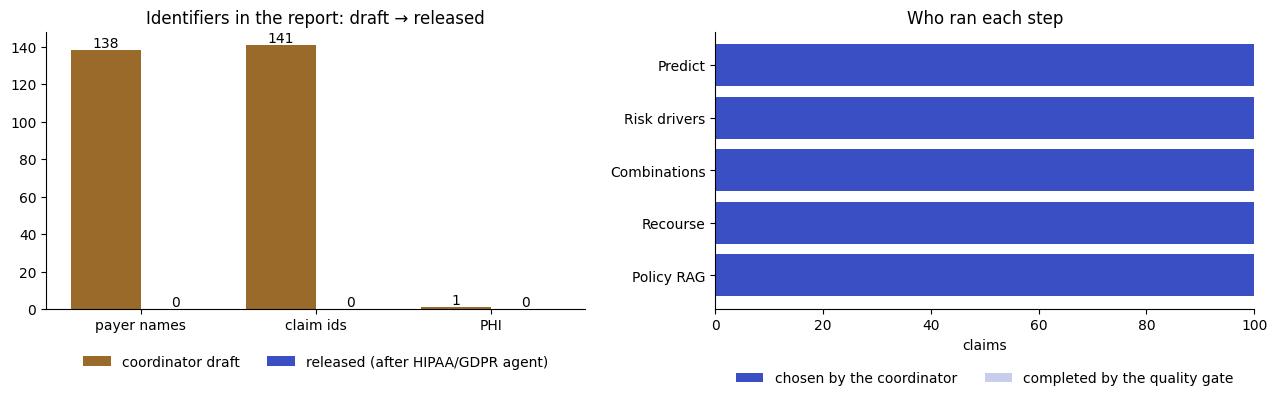

In [655]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
kinds = ["payer names", "claim ids", "PHI"]
before = [EVAL.payer_names_draft.sum(), EVAL.claim_ids_draft.sum(), EVAL.phi_draft.sum()]
after = [EVAL.payer_names_released.sum(), EVAL.claim_ids_released.sum(), EVAL.phi_released.sum()]
x = np.arange(len(kinds))
ax = axes[0]
b1 = ax.bar(x - 0.2, before, 0.4, label="coordinator draft", color="#9a6a2a")
b2 = ax.bar(x + 0.2, after, 0.4, label="released (after HIPAA/GDPR agent)", color="#3b4fc4")
ax.bar_label(b1); ax.bar_label(b2)
ax.set_xticks(x, kinds); ax.set_title("Identifiers in the report: draft → released")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
comps = ["prediction", "explainability", "combinations", "causality", "search_policy_docs"]
names = ["Predict", "Risk drivers", "Combinations", "Recourse", "Policy RAG"]
coord = [sum(bool(r.trace[r.trace.name == n]["by"].eq("coordinator").any()) for r in EVAL_RUNS.values()) for n in comps]
gate = [len(EVAL_RUNS) - k for k in coord]
ax.barh(names, coord, color="#3b4fc4", label="chosen by the coordinator")
ax.barh(names, gate, left=coord, color="#c7cdea", label="completed by the quality gate")
ax.set_xlim(0, len(EVAL_RUNS)); ax.invert_yaxis(); ax.set_xlabel("claims")
ax.set_title("Who ran each step"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(TRAIN_OUT_DIR / "evaluation" / "high_risk_evaluation.png", dpi=160, bbox_inches="tight")
plt.show()

#### Draft → released report through the HIPAA / GDPR agent (claim with the most identifiers in its draft)

In [656]:
cid = max(EVAL_RUNS, key=lambda c: EVAL.set_index("claim").loc[_pseudonym("CLAIM", c), ["payer_names_draft", "claim_ids_draft", "phi_draft"]].sum())
res = EVAL_RUNS[cid]


def _mark_draft(text: str) -> str:
    t = _html.escape(text)
    for n, p, _ in INSURER_PATTERNS:
        t = p.sub(lambda m: f'<mark class="payer">{m.group(0)}</mark>', t)
    t = re.sub(r"(?<!\d)" + r"[\s,.  ]?".join(str(cid)) + r"(?!\d)", lambda m: f'<mark class="cid">{m.group(0)}</mark>', t)
    for _, p in PHI_PATTERNS.items():
        t = re.sub(p, lambda m: f'<mark class="phi">{m.group(0)}</mark>', t, flags=re.I)
    return t


def _mark_released(text: str) -> str:
    t = _html.escape(text)
    t = re.sub(r"PAYER-[0-9A-F]{6}", lambda m: f'<mark class="payer">{m.group(0)}</mark>', t)
    t = re.sub(r"CLAIM-[0-9A-F]{6}", lambda m: f'<mark class="cid">{m.group(0)}</mark>', t)
    t = re.sub(r"\[REDACTED-[A-Z_]+\]", lambda m: f'<mark class="phi">{m.group(0)}</mark>', t)
    return t


row = EVAL.set_index("claim").loc[_pseudonym("CLAIM", cid)]
display(HTML(f"""
<style>.dv{{display:flex;gap:14px}} .dv>div{{flex:1;border:1px solid #e5e7eb;border-radius:10px;padding:10px 12px;
 max-height:520px;overflow:auto;white-space:pre-wrap;font:12px/1.45 ui-monospace,Menlo,monospace}}
 .dv h4{{margin:0 0 8px;font:600 13px -apple-system,Helvetica,sans-serif}}
 mark.payer{{background:#fde68a}} mark.cid{{background:#bfdbfe}} mark.phi{{background:#fecaca}}</style>
<p><b>Claim {_pseudonym("CLAIM", cid)}</b> — draft had {row.payer_names_draft} payer name(s), {row.claim_ids_draft} raw claim id(s),
 {row.phi_draft} PHI pattern(s); released report: {row.payer_names_released} · {row.claim_ids_released} · {row.phi_released}.
 Legend: <mark class="payer">payer</mark> <mark class="cid">claim id</mark> <mark class="phi">PHI</mark></p>
<div class="dv"><div><h4>① Coordinator draft (internal, never released)</h4>{_mark_draft(res.draft)}</div>
<div><h4>② Released report (after the HIPAA / GDPR agent)</h4>{_mark_released(res.report)}</div></div>"""))